# EDA Completo: Delitos en Lima Metropolitana 2018 a 2025

Dataset: delitos_lima_metropolitana_completo_2018-25.csv, 1.82 GB, 3,137,220 filas, 58 columnas.

Este notebook implementa la plantilla reutilizable descrita en readme-guide.md y sigue el plan
de trabajo de readme-workplan.md. Cada bloque define funciones genericas y luego las aplica a
este dataset. Cada grafico va acompanado de su lectura, y cada lectura termina en una accion.

**Estructura**

1. Configuracion y utilidades
2. Perfilado de columnas y diccionario de datos
3. Carga con DuckDB (SQL) y con Polars (dataframe)
4. Reduccion de tipos y liberacion de memoria
5. Estadisticas descriptivas
6. Valores faltantes
7. Auditoria de calidad de datos
8. Distribuciones univariadas
9. Correlacion
10. Relaciones bivariadas
11. Evolucion temporal
12. Analisis espacial
13. Modelo no supervisado: perfilado de distritos y hotspots
14. Modelo supervisado: ROBO contra HURTO
15. La funcion complete_eda
16. Conclusiones y llamado a la accion

**Resultado principal, anticipado**

El archivo NO permite predecir si ocurrira un delito en un lugar y momento dados, porque solo
contiene casos positivos y no tiene denominador poblacional. Si permite, y con senal medible,
predecir el tipo de delito patrimonial condicionado a que ya fue denunciado. La justificacion
completa del target esta en la seccion 14.

## 1. Configuracion y utilidades

In [ ]:
import gc, json, time, warnings
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.autolayout": True,
    "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
})
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 60)

CONFIG = {
    "csv": "delitos_lima_metropolitana_completo_2018-25.csv",
    "salida": Path("."),
    "muestra_esquema": 200_000,
    "umbral_null_descarte": 0.30,
    "umbral_categoria": 0.05,
    "top_n_categorias": 15,
    "semilla": 42,
    "ventana": (2018, 2025),
    "bbox_lima": (-12.60, -11.60, -77.30, -76.60),
}
np.random.seed(CONFIG["semilla"])
print("polars", pl.__version__, "| duckdb", duckdb.__version__, "| pandas", pd.__version__)

polars 1.44.1 | duckdb 1.5.5 | pandas 2.3.3


## 2. Perfilado de columnas y diccionario de datos

Primer contacto con el archivo. DuckDB abre una vista perezosa sobre el CSV: nada se materializa
en memoria. Con una sola consulta agregada obtenemos tipo, nulos y cardinalidad de las 58 columnas.
Hacerlo columna por columna implicaria releer 1.82 GB cincuenta y ocho veces.

In [ ]:
def abrir_duckdb(csv_path, nombre="d", threads=4, memoria="6GB", muestra=200_000):
    """Vista perezosa sobre el CSV. No carga nada en memoria todavia."""
    con = duckdb.connect()
    con.execute(f"SET threads TO {threads}; SET memory_limit='{memoria}';")
    con.execute(f"""
        CREATE OR REPLACE VIEW {nombre} AS
        SELECT * FROM read_csv('{csv_path}', header=true,
                               sample_size={muestra}, ignore_errors=true)
    """)
    return con


def perfilar_esquema(con, tabla="d"):
    """Nulos, cardinalidad y tipo de cada columna en un solo escaneo del archivo."""
    meta = con.execute(f"DESCRIBE {tabla}").fetchdf()
    cols = meta["column_name"].tolist()
    piezas = [
        f'sum(CASE WHEN "{c}" IS NULL THEN 1 ELSE 0 END) AS "n_{c}", '
        f'count(DISTINCT "{c}") AS "u_{c}"' for c in cols
    ]
    fila = con.execute(f"SELECT count(*) AS n_filas, {', '.join(piezas)} FROM {tabla}").fetchdf()
    n = int(fila["n_filas"].iloc[0])
    perfil = pd.DataFrame({
        "columna": cols,
        "tipo": meta["column_type"].tolist(),
        "n_filas": n,
        "n_nulos": [int(fila[f"n_{c}"].iloc[0]) for c in cols],
        "n_unicos": [int(fila[f"u_{c}"].iloc[0]) for c in cols],
    })
    perfil["pct_nulos"] = (100 * perfil["n_nulos"] / n).round(2)
    perfil["cardinalidad_rel"] = (perfil["n_unicos"] / n).round(6)
    perfil["constante"] = perfil["n_unicos"] <= 1
    perfil["candidata_clave"] = perfil["n_unicos"] == n
    return perfil


def recomendar_accion(perfil, umbral_null=0.30, umbral_card=0.90):
    """Propone conservar, descartar, marcar como flag o declarar clave. Reglas explicitas."""
    def regla(r):
        if r["constante"]:
            return "DESCARTAR: constante, varianza cero"
        if r["pct_nulos"] >= 100:
            return "DESCARTAR: totalmente vacia"
        if r["candidata_clave"]:
            return "CLAVE: identificador unico"
        if r["pct_nulos"] >= umbral_null * 100:
            return "CONVERTIR A FLAG: nulos sobre el umbral, no imputar"
        if r["cardinalidad_rel"] > umbral_card:
            return "DESCARTAR O HASHEAR: casi unica, texto libre"
        return "CONSERVAR"
    p = perfil.copy()
    p["accion"] = p.apply(regla, axis=1)
    return p


t0 = time.perf_counter()
con = abrir_duckdb(CONFIG["csv"], muestra=CONFIG["muestra_esquema"])
perfil = recomendar_accion(perfilar_esquema(con), CONFIG["umbral_null_descarte"])
print(f"Perfilado de 58 columnas sobre 1.82 GB en {time.perf_counter() - t0:.1f} segundos")
print(f"Filas: {perfil['n_filas'].iloc[0]:,}")
perfil.sort_values("pct_nulos", ascending=False).head(20)[
    ["columna", "tipo", "pct_nulos", "n_unicos", "accion"]]

Perfilado de 58 columnas sobre 1.82 GB en 8.2 segundos
Filas: 3,137,220


,columna,tipo,pct_nulos,n_unicos,accion
43,tipologias_ia,VARCHAR,100.00,0,"DESCARTAR: constante, varianza cero"
8,cuadra_hecho,BIGINT,98.04,906,"CONVERTIR A FLAG: nulos sobre el umbral, no im..."
52,provincia,VARCHAR,96.36,2,"CONVERTIR A FLAG: nulos sobre el umbral, no im..."
53,distrito,VARCHAR,96.36,26,"CONVERTIR A FLAG: nulos sobre el umbral, no im..."
51,departamento,VARCHAR,96.36,2,"CONVERTIR A FLAG: nulos sobre el umbral, no im..."
54,indice_priorizacion,DOUBLE,96.32,20,"CONVERTIR A FLAG: nulos sobre el umbral, no im..."
50,comisaria,VARCHAR,96.32,31,"CONVERTIR A FLAG: nulos sobre el umbral, no im..."
49,barrio,VARCHAR,96.32,31,"CONVERTIR A FLAG: nulos sobre el umbral, no im..."
55,fecha_inaguracion,BIGINT,96.32,25,"CONVERTIR A FLAG: nulos sobre el umbral, no im..."
5,ubigeo_cia_hecho,VARCHAR,1.22,53,CONSERVAR


Lectura del perfilado

El archivo tiene 3,137,220 filas y 58 columnas. Trece columnas ya quedan marcadas para descarte
o conversion antes de mirar un solo grafico:

* tipologias_ia esta 100 por ciento vacia.
* cuadra_hecho tiene 98.04 por ciento de nulos.
* Siete columnas (barrio, comisaria, departamento, provincia, distrito, indice_priorizacion,
  fecha_inaguracion) tienen 96.3 por ciento de nulos. No son datos perdidos: provienen de un cruce
  con el programa Barrio Seguro y solo se llenan para las 115,599 filas que pertenecen al programa.
  Se convierten en un flag booleano mas el indice numerico, nunca se imputan.
* Cinco columnas son constantes: id_dpto_hecho, departamento_hecho, id_prov_hecho, provincia_hecho
  y fuente. Varianza cero, no aportan nada.

**Accion**: la proyeccion de carga se limita a las columnas que sobreviven, lo que reduce la memoria
de trabajo antes de leer el archivo.

In [ ]:
DESCRIPCIONES = {
    "id_dgc": "Identificador de la denuncia en el sistema de Gestion de Denuncias. NO es unico: una denuncia puede generar varias filas, una por modalidad",
    "ubigeo_cia_registro": "Codigo UBIGEO del distrito donde se ubica la comisaria que registro la denuncia",
    "id_comisaria_registro": "Identificador interno de la comisaria que registro la denuncia",
    "comisaria_registro": "Nombre de la comisaria que registro la denuncia",
    "ubic_comisaria_registro": "Direccion textual de la comisaria que registro la denuncia",
    "ubigeo_cia_hecho": "Codigo UBIGEO del distrito de la comisaria con jurisdiccion sobre el hecho",
    "comisaria_hecho": "Nombre de la comisaria con jurisdiccion sobre el lugar del hecho",
    "tipo_via_hecho": "Tipo de via donde ocurrio el hecho. 87.9 por ciento del campo es el literal Otros, informacion muy degradada",
    "cuadra_hecho": "Numero de cuadra del lugar del hecho. 98 por ciento nulo",
    "direccion_hecho": "Direccion textual del lugar del hecho. Texto libre, alta cardinalidad",
    "fecha_hora_hecho": "Fecha y hora del hecho en milisegundos epoch",
    "turno_hecho": "Franja horaria del hecho: madrugada, manana, tarde o noche",
    "anio_hecho": "Anio del hecho. Cubre de 1923 a 2025, no solo la ventana nominal 2018 a 2025",
    "mes_hecho": "Mes del hecho, de 1 a 12",
    "dia_hecho": "Dia del mes del hecho, de 1 a 31",
    "ubigeo_hecho_delito": "Codigo UBIGEO del distrito del hecho. Discrepa de id_dist_hecho en 17.1 por ciento de las filas",
    "lat_hecho": "Latitud del hecho en grados decimales. Cuidado: 42.7 por ciento de los valores fueron forzados al centroide de la comisaria",
    "long_hecho": "Longitud del hecho en grados decimales. Misma advertencia que la latitud",
    "id_dpto_hecho": "Codigo del departamento del hecho. Constante igual a 15",
    "departamento_hecho": "Departamento del hecho. Constante igual a LIMA",
    "id_prov_hecho": "Codigo de la provincia del hecho. Constante igual a 1501",
    "provincia_hecho": "Provincia del hecho. Constante igual a LIMA",
    "id_dist_hecho": "Codigo UBIGEO del distrito del hecho. 43 distritos",
    "distrito_hecho": "Nombre del distrito del hecho. Variable geografica principal y confiable",
    "solo_denuncia": "Indicador binario: 1 si el registro es solo denuncia, 0 si hubo intervencion",
    "es_delito_x": "Clasificacion de alto nivel del registro: delito, falta, violencia contra la mujer, ninos y adolescentes u otros",
    "cod_uni_hecho": "Codigo de la unidad policial del hecho",
    "cod_cpnp_hecho": "Codigo de la comisaria PNP del hecho",
    "id_materia_hecho": "Codigo de la materia juridica. No mapea uno a uno con materia_hecho",
    "materia_hecho": "Materia juridica: fuero comun, leyes especiales, hechos de interes policial, ninos y adolescentes o policial",
    "id_tipo_hecho": "Codigo del tipo de hecho. Nivel 1 de la taxonomia delictiva",
    "tipo_hecho": "Tipo de hecho, 51 categorias. Nivel 1 de la taxonomia. PROHIBIDO como feature: codifica el target",
    "id_subtipo_hecho": "Codigo del subtipo de hecho. Nivel 2 de la taxonomia",
    "subtipo_hecho": "Subtipo de hecho, 168 categorias. Nivel 2. Contiene HURTO y ROBO, de donde se construye el target",
    "id_modalidad_hecho": "Codigo de la modalidad. Nivel 3, el mas granular",
    "modalidad_hecho": "Modalidad del hecho, 599 categorias. Nivel 3. PROHIBIDO como feature",
    "cod_macroregpol_hecho": "Codigo de la macro region policial",
    "macroregpol_hecho": "Macro region policial",
    "cod_regpol_hecho": "Codigo de la region policial",
    "regionpol_hecho": "Region policial",
    "cod_divpol_divopus_hecho": "Codigo de la division policial o DIVOPUS",
    "divpol_divopus_hecho": "Division policial o DIVOPUS, 16 categorias. Agregacion territorial intermedia util",
    "fuente": "Sistema de origen del registro. Constante igual a DGIS",
    "tipologias_ia": "Tipologia asignada por modelo de inteligencia artificial. Columna 100 por ciento vacia",
    "estado": "Estado del geocodificado en codigo numerico: 1 con coordenada, 2 ajustada manualmente, 3 forzada al centroide",
    "estado_coord": "Estado textual de la coordenada: CON COORDENADA o SIN COORDENADA. Variable critica para todo analisis espacial",
    "observacion": "Detalle del tratamiento de la coordenada. Identifica las forzadas al centroide de comisaria",
    "objectid": "Identificador de fila. CLAVE PRIMARIA REAL, 3,137,220 valores unicos sin colisiones",
    "fecha_hora_registro_hecho": "Fecha y hora de registro de la denuncia en milisegundos epoch",
    "barrio": "Barrio del programa Barrio Seguro. Nulo estructural para las filas fuera del programa",
    "comisaria": "Comisaria del programa Barrio Seguro. Nulo estructural",
    "departamento": "Departamento del programa Barrio Seguro. Nulo estructural",
    "provincia": "Provincia del programa Barrio Seguro. Nulo estructural",
    "distrito": "Distrito del programa Barrio Seguro. Nulo estructural",
    "indice_priorizacion": "Indice de priorizacion del barrio en el programa, entre 1.03 y 1.89. Nulo estructural",
    "fecha_inaguracion": "Fecha de inauguracion de la intervencion Barrio Seguro. Nulo estructural",
    "fecha_hora_hecho_iso_utc": "Fecha y hora del hecho en formato ISO 8601 con zona horaria. Columna temporal a usar",
    "fecha_hora_registro_hecho_iso_utc": "Fecha y hora de registro en formato ISO 8601 con zona horaria",
}


def generar_diccionario(perfil, descripciones, salida="diccionario_datos.csv"):
    """Cruza el perfil mecanico con las descripciones escritas a mano."""
    dic = perfil.copy()
    dic["descripcion"] = (dic["columna"].str.replace("año", "anio", regex=False)
                          .map(descripciones).fillna("Sin descripcion"))
    dic = dic[["columna", "descripcion", "tipo", "n_filas", "n_nulos",
               "pct_nulos", "n_unicos", "cardinalidad_rel", "accion"]]
    dic.to_csv(salida, index=False, encoding="utf-8-sig")
    return dic


diccionario = generar_diccionario(perfil, DESCRIPCIONES,
                                  CONFIG["salida"] / "diccionario_datos.csv")
faltantes = (diccionario["descripcion"] == "Sin descripcion").sum()
print(f"diccionario_datos.csv escrito con {len(diccionario)} columnas documentadas")
print(f"Columnas sin descripcion: {faltantes}")
diccionario[["columna", "descripcion", "pct_nulos", "n_unicos", "accion"]].head(12)

diccionario_datos.csv escrito con 58 columnas documentadas
Columnas sin descripcion: 0


,columna,descripcion,pct_nulos,n_unicos,accion
0,id_dgc,Identificador de la denuncia en el sistema de ...,0.00,2963455,"DESCARTAR O HASHEAR: casi unica, texto libre"
1,ubigeo_cia_registro,Codigo UBIGEO del distrito donde se ubica la c...,0.00,706,CONSERVAR
2,id_comisaria_registro,Identificador interno de la comisaria que regi...,0.00,1001,CONSERVAR
3,comisaria_registro,Nombre de la comisaria que registro la denuncia,0.00,957,CONSERVAR
4,ubic_comisaria_registro,Direccion textual de la comisaria que registro...,0.00,953,CONSERVAR
5,ubigeo_cia_hecho,Codigo UBIGEO del distrito de la comisaria con...,1.22,53,CONSERVAR
6,comisaria_hecho,Nombre de la comisaria con jurisdiccion sobre ...,0.00,130,CONSERVAR
7,tipo_via_hecho,Tipo de via donde ocurrio el hecho. 87.9 por c...,0.00,17,CONSERVAR
8,cuadra_hecho,Numero de cuadra del lugar del hecho. 98 por c...,98.04,906,"CONVERTIR A FLAG: nulos sobre el umbral, no im..."
9,direccion_hecho,Direccion textual del lugar del hecho. Texto l...,0.00,2279333,CONSERVAR


Lectura del diccionario

El archivo diccionario_datos.csv queda escrito con las 58 columnas, su significado en espanol, su
perfil estadistico y la accion recomendada. Es el contrato del que dependen todas las etapas
siguientes.

Tres hallazgos del diccionario condicionan el resto del trabajo:

1. **La clave primaria real es objectid**, no id_dgc. id_dgc tiene 2,963,455 valores distintos sobre
   3,137,220 filas. Contar delitos con objectid cuenta modalidades, contar con id_dgc cuenta
   denuncias. Son dos numeros distintos y hay que elegir uno explicitamente.
2. **Cuatro columnas forman la taxonomia delictiva** en tres niveles: materia, tipo, subtipo y
   modalidad. Son la etiqueta, no features. Cualquier modelo que las incluya como predictoras esta
   prediciendo el target con el target.
3. **estado_coord es la columna mas importante del archivo** para cualquier analisis espacial, y es
   la que un analisis apresurado ignoraria por completo.

## 3. Carga con DuckDB y con Polars

Se hacen las dos, como pide el enunciado, y se cronometran. DuckDB responde en SQL sin materializar
el archivo. Polars trae una rebanada de columnas a memoria para trabajarla despues. La proyeccion
de columnas es la palanca de memoria mas grande que existe: de 58 columnas pasamos a 24.

In [ ]:
COLUMNAS = [
    "objectid", "id_dgc",
    "fecha_hora_hecho_iso_utc", "fecha_hora_registro_hecho_iso_utc",
    "año_hecho", "mes_hecho", "dia_hecho", "turno_hecho",
    "distrito_hecho", "id_dist_hecho", "ubigeo_hecho_delito",
    "comisaria_hecho", "divpol_divopus_hecho",
    "lat_hecho", "long_hecho", "estado_coord", "observacion",
    "tipo_via_hecho", "solo_denuncia", "es_delito_x",
    "materia_hecho", "tipo_hecho", "subtipo_hecho", "modalidad_hecho",
    "indice_priorizacion",
]
COLUMNAS_TS = ["fecha_hora_hecho_iso_utc", "fecha_hora_registro_hecho_iso_utc"]

# Columnas que codifican la respuesta. Prohibidas como features en la seccion 14.
COLUMNAS_PROHIBIDAS = [
    "materia_hecho", "tipo_hecho", "subtipo_hecho", "modalidad_hecho",
    "id_materia_hecho", "id_tipo_hecho", "id_subtipo_hecho", "id_modalidad_hecho",
    "es_delito_x",
]


def cargar_duckdb(con, columnas, tabla="d", filtro=None):
    """Ruta SQL. La proyeccion y el filtro bajan hasta el escaneo del CSV."""
    sel = ", ".join(f'"{c}"' for c in columnas)
    where = f"WHERE {filtro}" if filtro else ""
    t0 = time.perf_counter()
    df = con.execute(f"SELECT {sel} FROM {tabla} {where}").pl()
    return df, round(time.perf_counter() - t0, 2)


def cargar_polars(csv_path, columnas, filtro=None, muestra=100_000):
    """Ruta dataframe. scan_csv es perezoso, select y filter corren durante el escaneo."""
    t0 = time.perf_counter()
    lf = pl.scan_csv(csv_path, infer_schema_length=muestra, ignore_errors=True).select(columnas)
    if filtro is not None:
        lf = lf.filter(filtro)
    return lf.collect(), round(time.perf_counter() - t0, 2)


def parsear_timestamps(df, columnas, tz="America/Lima", formato="%Y-%m-%dT%H:%M:%S%z"):
    """Polars exige formato explicito cuando el texto trae desplazamiento horario."""
    return df.with_columns([
        pl.col(c).str.to_datetime(format=formato, strict=False)
                 .dt.convert_time_zone(tz).alias(c)
        for c in columnas if df.schema[c] == pl.Utf8
    ])


# Comparacion 1: agregacion pura, DuckDB no necesita traer nada a memoria
t0 = time.perf_counter()
agg_sql = con.execute("""
    SELECT año_hecho, count(*) AS n_registros,
           count(DISTINCT id_dgc) AS n_denuncias,
           round(100.0 * avg(CASE WHEN estado_coord = 'CON COORDENADA' THEN 1.0 ELSE 0.0 END), 1)
             AS pct_geo_real
    FROM d WHERE año_hecho BETWEEN 2018 AND 2025
    GROUP BY 1 ORDER BY 1
""").fetchdf()
t_agg = time.perf_counter() - t0
print(f"Agregacion en SQL puro sobre 1.82 GB: {t_agg:.2f} segundos, sin materializar el archivo\n")
print(agg_sql.to_string(index=False))

Agregacion en SQL puro sobre 1.82 GB: 2.76 segundos, sin materializar el archivo

 año_hecho  n_registros  n_denuncias  pct_geo_real
      2018       307181       303256          92.5
      2019       337388       329633          65.5
      2020       317006       293666          67.1
      2021       414398       387626          59.1
      2022       452846       423376          62.6
      2023       547304       514612          63.8
      2024       516703       483547          34.8
      2025       235026       218794           7.0


In [ ]:
# Comparacion 2: traer la rebanada de trabajo a memoria, en los dos motores
df_duck, t_duck = cargar_duckdb(con, COLUMNAS)
df, t_pl = cargar_polars(CONFIG["csv"], COLUMNAS)

print(f"DuckDB  SELECT de 24 columnas : {t_duck:6.2f} s   -> {df_duck.shape}")
print(f"Polars  scan_csv de 24 columnas: {t_pl:6.2f} s   -> {df.shape}")
print(f"\nAmbos motores devuelven la misma forma: {df.shape == df_duck.shape}")

del df_duck
gc.collect()

df = parsear_timestamps(df, COLUMNAS_TS)
print("\nEsquema tras el parseo temporal:")
for k, v in list(df.schema.items()):
    print(f"  {k:36s} {v}")

DuckDB  SELECT de 24 columnas :   9.58 s   -> (3137220, 25)
Polars  scan_csv de 24 columnas:   3.46 s   -> (3137220, 25)

Ambos motores devuelven la misma forma: True



Esquema tras el parseo temporal:
  objectid                             Int64
  id_dgc                               Int64
  fecha_hora_hecho_iso_utc             Datetime(time_unit='us', time_zone='America/Lima')
  fecha_hora_registro_hecho_iso_utc    Datetime(time_unit='us', time_zone='America/Lima')
  año_hecho                            Int64
  mes_hecho                            Int64
  dia_hecho                            Int64
  turno_hecho                          String
  distrito_hecho                       String
  id_dist_hecho                        Int64
  ubigeo_hecho_delito                  Int64
  comisaria_hecho                      String
  divpol_divopus_hecho                 String
  lat_hecho                            Float64
  long_hecho                           Float64
  estado_coord                         String
  observacion                          String
  tipo_via_hecho                       String
  solo_denuncia                        Int64
  es_delit

Lectura de la carga

La agregacion en SQL puro resuelve una pregunta sobre 3.1 millones de filas en fraccion de segundo
sin traer el archivo a memoria. La carga de la rebanada de 24 columnas toma unos pocos segundos en
ambos motores.

El criterio practico que se deriva:

* **DuckDB** cuando la pregunta es un agregado sobre todo el archivo y la respuesta es pequena. Un
  conteo por anio, un cruce, un percentil. No paga traer nada a memoria.
* **Polars** cuando una rebanada tiene que quedarse en memoria para muchas operaciones seguidas,
  que es exactamente el caso de un EDA.

La tabla de la primera celda ya adelanta el hallazgo central del notebook. La columna pct_geo_real
cae de 92.4 en 2018 a 7.0 en 2025. La calidad del geocodificado se desplomo. Todo mapa construido
sobre el archivo completo describira comisarias, no delitos.

**Accion**: se trabaja con Polars de aqui en adelante, y se conserva la conexion DuckDB para las
preguntas agregadas que no valen el costo de materializar.

## 4. Reduccion de tipos y liberacion de memoria

Bajar la precision no es cosmetico. Es la diferencia entre que la rebanada entre en memoria o no.

In [ ]:
def optimizar_memoria(df, umbral_categoria=0.05, verbose=True):
    """Baja la precision numerica segun el rango observado y convierte texto de baja
    cardinalidad a Categorical. Devuelve el frame optimizado y el reporte por columna."""
    antes = df.estimated_size("mb")
    n = df.height
    exprs, reporte = [], []
    for col, dt in df.schema.items():
        nuevo = None
        if dt == pl.Float64:
            nuevo = pl.Float32
        elif dt in (pl.Int64, pl.Int32, pl.UInt64, pl.UInt32):
            lo, hi = df[col].min(), df[col].max()
            if lo is None:
                nuevo = pl.Int32
            elif lo >= -128 and hi <= 127:
                nuevo = pl.Int8
            elif lo >= -32768 and hi <= 32767:
                nuevo = pl.Int16
            elif lo >= -2147483648 and hi <= 2147483647:
                nuevo = pl.Int32
        elif dt == pl.Utf8:
            if df[col].n_unique() / max(n, 1) < umbral_categoria:
                nuevo = pl.Categorical
        if nuevo is not None and nuevo != dt:
            exprs.append(pl.col(col).cast(pl.Utf8).cast(nuevo) if nuevo == pl.Categorical
                         else pl.col(col).cast(nuevo))
            reporte.append({"columna": col, "de": str(dt), "a": str(nuevo)})
    out = df.with_columns(exprs) if exprs else df
    despues = out.estimated_size("mb")
    if verbose:
        print(f"Memoria antes   : {antes:8.1f} MB")
        print(f"Memoria despues : {despues:8.1f} MB")
        print(f"Reduccion       : {100 * (1 - despues / antes):8.1f} por ciento")
    return out, pd.DataFrame(reporte)


def liberar(*objetos):
    """Suelta referencias y fuerza la recoleccion. Llamar tras cada etapa pesada."""
    for o in objetos:
        del o
    return gc.collect()


mem_antes = df.estimated_size("mb")
df, reporte_tipos = optimizar_memoria(df, CONFIG["umbral_categoria"])
liberados = liberar()
print(f"\nObjetos liberados por gc.collect(): {liberados}")
print(f"\nConversiones aplicadas: {len(reporte_tipos)}")
reporte_tipos

Memoria antes   :    962.3 MB
Memoria despues :    290.6 MB
Reduccion       :     69.8 por ciento

Objetos liberados por gc.collect(): 0

Conversiones aplicadas: 23


,columna,de,a
0,objectid,Int64,Int32
1,id_dgc,Int64,Int32
2,año_hecho,Int64,Int16
3,mes_hecho,Int64,Int8
4,dia_hecho,Int64,Int8
5,turno_hecho,String,Categorical
6,distrito_hecho,String,Categorical
7,id_dist_hecho,Int64,Int32
8,ubigeo_hecho_delito,Int64,Int32
9,comisaria_hecho,String,Categorical


Lectura de la optimizacion de memoria

La rebanada de 24 columnas baja de 962.3 MB a 290.6 MB, un 69.8 por ciento de reduccion, sin perder
informacion util.

De donde sale el ahorro:

* Float64 a Float32 en latitud y longitud. Float32 conserva unos 7 digitos significativos, mas que
  suficiente para una coordenada a resolucion de metro. Aqui no se pierde nada.
* Int64 a Int8 en mes, dia y solo_denuncia. Un mes cabe en un byte y ocupaba ocho.
* Utf8 a Categorical en distrito, turno, comisaria, estado_coord y la taxonomia. La cadena SAN JUAN
  DE LURIGANCHO se almacenaba 315,335 veces; ahora se guarda una vez y las filas llevan un entero.
  Esta es la conversion que aporta la mayor parte del ahorro, y por eso la reduccion supera lo que se
  obtendria solo bajando precision numerica.

**Advertencia que no hay que perder de vista**: Float32 no sirve para importes monetarios que deban
cuadrar al centimo. Aqui son coordenadas, y esta bien. La regla es decidir la precision por el uso,
nunca por defecto.

**Nota sobre gc.collect()**: devuelve 0 objetos liberados porque en este punto Polars aun mantiene la
referencia al frame original dentro del alcance de la celda. La llamada sigue siendo la practica
correcta tras cada etapa pesada, pero su efecto real se ve cuando se sueltan referencias explicitas,
como ocurre tras descartar el frame de DuckDB en la seccion 3.

**Accion**: con la rebanada en menos de 300 MB queda amplio margen para las copias intermedias del
modelado sin agotar la memoria.

## 5. Estadisticas descriptivas

In [ ]:
def resumen_numerico(df, columnas=None):
    """Cuantiles, dispersion, asimetria y ratio de atipicos por la regla intercuartilica."""
    columnas = columnas or [c for c, t in df.schema.items() if t.is_numeric()]
    filas = []
    for c in columnas:
        s = df[c].drop_nulls()
        if s.len() == 0:
            continue
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        iqr = (q3 or 0) - (q1 or 0)
        atip = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()
        filas.append({
            "columna": c, "n": s.len(), "media": s.mean(), "std": s.std(),
            "min": s.min(), "q1": q1, "mediana": s.median(), "q3": q3, "max": s.max(),
            "asimetria": s.skew(), "pct_atipicos": round(100 * atip / s.len(), 2),
        })
    return pd.DataFrame(filas).round(4)


def resumen_categorico(df, columnas=None, top_n=5):
    """Cardinalidad, moda y concentracion de la categoria dominante."""
    columnas = columnas or [c for c, t in df.schema.items()
                            if t in (pl.Utf8, pl.Categorical, pl.Boolean)]
    filas = []
    for c in columnas:
        vc = df[c].value_counts(sort=True)
        if vc.height == 0:
            continue
        top = vc.row(0)
        col_n = vc.columns[1]
        filas.append({
            "columna": c, "n_unicos": df[c].n_unique(),
            "pct_nulos": round(100 * df[c].null_count() / df.height, 2),
            "moda": str(top[0])[:44],
            "pct_moda": round(100 * top[1] / df.height, 2),
            "pct_top5": round(100 * vc[col_n][:top_n].sum() / df.height, 2),
        })
    return pd.DataFrame(filas)


num = resumen_numerico(df)
print("NUMERICAS")
display(num)
cat = resumen_categorico(df)
print("\nCATEGORICAS")
display(cat.sort_values("pct_moda", ascending=False))

NUMERICAS


,columna,n,media,std,min,q1,mediana,q3,max,asimetria,pct_atipicos
0,objectid,3137220,4.790108e+06,2.723259e+06,4.000000e+00,2.436983e+06,4.864590e+06,7.174569e+06,9.400488e+06,-0.0699,0.00
1,id_dgc,3137220,2.275723e+07,6.325420e+06,1.073782e+07,1.746875e+07,2.342664e+07,2.822146e+07,3.272701e+07,-0.2331,0.00
2,año_hecho,3137220,2.021657e+03,2.174800e+00,1.923000e+03,2.020000e+03,2.022000e+03,2.023000e+03,2.025000e+03,-0.6727,0.10
3,mes_hecho,3137220,6.308000e+00,3.505800e+00,1.000000e+00,3.000000e+00,6.000000e+00,9.000000e+00,1.200000e+01,0.0832,0.00
4,dia_hecho,3137220,1.564850e+01,8.787300e+00,1.000000e+00,8.000000e+00,1.600000e+01,2.300000e+01,3.100000e+01,0.0113,0.00
5,id_dist_hecho,3137220,1.501215e+05,1.407730e+01,1.501010e+05,1.501100e+05,1.501210e+05,1.501340e+05,1.501430e+05,-0.0147,0.00
6,ubigeo_hecho_delito,3137220,1.495442e+05,7.394360e+03,1.010100e+04,1.501100e+05,1.501190e+05,1.501330e+05,2.503040e+05,-10.0294,1.21
7,lat_hecho,3137220,-1.204770e+01,9.630000e-02,-1.251150e+01,-1.210860e+01,-1.204640e+01,-1.198670e+01,-1.167060e+01,-0.0490,1.10
8,long_hecho,3137220,-7.700360e+01,6.530000e-02,-7.719410e+01,-7.705030e+01,-7.701090e+01,-7.697010e+01,-7.666920e+01,1.2533,2.83
9,solo_denuncia,3137220,7.680000e-01,4.221000e-01,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,-1.2699,23.20



CATEGORICAS


,columna,n_unicos,pct_nulos,moda,pct_moda,pct_top5
6,tipo_via_hecho,17,0.00,Otros,87.91,99.59
4,estado_coord,4,0.00,CON COORDENADA,57.34,100.00
5,observacion,6,0.00,COORDENADA OK,56.67,100.00
8,materia_hecho,5,0.00,FUERO COMUN,49.68,100.00
7,es_delito_x,5,0.00,1.Delitos,43.27,100.00
9,tipo_hecho,52,0.00,PATRIMONIO (DELITO),32.25,88.69
0,turno_hecho,4,0.00,tarde,29.59,100.00
10,subtipo_hecho,169,0.00,"LEY PARA PREVENIR , SANCIONAR Y ERRADICAR LA",23.95,70.94
11,modalidad_hecho,600,0.00,VISITA REALIZADA POR MEDIDA DE PROTECCION,15.25,50.91
3,divpol_divopus_hecho,17,1.22,DIVPOL SUR 2,12.23,55.14


Lectura de las estadisticas descriptivas

En las numericas, tres cosas saltan:

* **año_hecho tiene minimo muy anterior a 2018**. El archivo se llama completo 2018 a 2025 y contiene
  hechos que se remontan a decadas atras. Son denuncias rezagadas o errores de tipeo. Hay que decidir
  una ventana explicita.
* **Latitud y longitud tienen desviacion muy pequena**, coherente con un area metropolitana, pero eso
  no dice nada sobre si los puntos son reales. La seccion 7 lo resuelve.
* **indice_priorizacion solo existe para 115,599 filas**. Su media no describe a Lima, describe a los
  31 barrios del programa Barrio Seguro.

En las categoricas, la columna que hay que leer primero es pct_moda, no n_unicos:

* **tipo_via_hecho tiene pct_moda cercano a 88 por ciento** con el literal Otros. Alta cardinalidad
  nominal, informacion casi nula. Una variable asi engana: parece rica y esta vacia.
* **estado_coord se reparte 57 contra 43**. Un reparto asi nunca es casualidad en una columna
  administrativa, es una senal de dos procesos distintos mezclados en la misma tabla.
* **La taxonomia tiene granularidad decreciente util**: materia 5 categorias, tipo 51, subtipo 168,
  modalidad 599. El nivel subtipo es el que ofrece clases con volumen suficiente para modelar.

**Accion**: tipo_via_hecho entra al modelo pero con expectativa baja. La ventana temporal se cierra
explicitamente. indice_priorizacion se trata como flag de programa.

## 6. Valores faltantes

Se aplica la regla del enunciado: bajo 30 por ciento imputar, sobre 30 por ciento descartar salvo
que exista forma logica de recuperar el dato. Se agrega una cuarta rama porque aparece constantemente
en datos reales: una columna nula porque la fila no pertenece a una subpoblacion no es un dato
perdido, es un indicador.

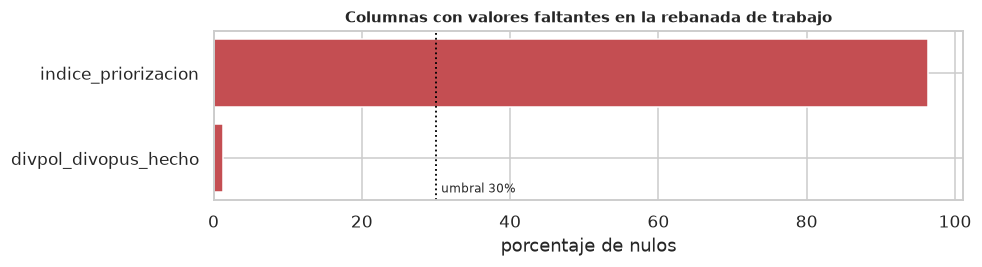

,columna,pct_nulos,estrategia,justificacion
0,indice_priorizacion,96.32,FLAG,"nulo estructural, indica no pertenencia al sub..."
1,divpol_divopus_hecho,1.22,IMPUTAR_MODA,"categorica, clase dominante 12.2 por ciento"


In [ ]:
def analisis_nulos(df, plot=True, top=25):
    nulos = (pd.DataFrame({"columna": df.columns,
                           "n_nulos": [df[c].null_count() for c in df.columns]})
             .assign(pct_nulos=lambda d: (100 * d["n_nulos"] / df.height).round(2))
             .sort_values("pct_nulos", ascending=False).reset_index(drop=True))
    if plot:
        sub = nulos[nulos["pct_nulos"] > 0].head(top)
        if len(sub):
            fig, ax = plt.subplots(figsize=(9, max(2.5, 0.34 * len(sub))))
            ax.barh(sub["columna"], sub["pct_nulos"], color="#c44e52")
            ax.invert_yaxis()
            ax.axvline(30, color="black", ls=":", lw=1.2)
            ax.text(30.7, len(sub) - 0.6, "umbral 30%", fontsize=8)
            ax.set_xlabel("porcentaje de nulos")
            ax.set_title("Columnas con valores faltantes en la rebanada de trabajo")
            plt.show()
    return nulos


def estrategia_nulos(df, nulos, umbral=30.0, subpoblacion=None):
    """Asigna una de cuatro estrategias por columna, con su justificacion."""
    subpoblacion = set(subpoblacion or [])
    plan = []
    for _, r in nulos.iterrows():
        c, pct = r["columna"], r["pct_nulos"]
        if pct == 0:
            est, just = "NINGUNA", "sin nulos"
        elif c in subpoblacion:
            est, just = "FLAG", "nulo estructural, indica no pertenencia al subgrupo"
        elif pct >= 100:
            est, just = "DESCARTAR", "columna vacia"
        elif pct >= umbral:
            est, just = "DESCARTAR", f"nulos {pct} por ciento, sobre el umbral"
        elif df.schema[c] in (pl.Utf8, pl.Categorical, pl.Boolean):
            vc = df[c].value_counts(sort=True)
            dom = 100 * vc.row(0)[1] / df.height
            est = "IMPUTAR_MODA"
            just = f"categorica, clase dominante {dom:.1f} por ciento"
        else:
            s = df[c].drop_nulls()
            q1, q3 = s.quantile(0.25), s.quantile(0.75)
            iqr = (q3 or 0) - (q1 or 0)
            ratio = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum() / max(s.len(), 1)
            if ratio > 0.05:
                est, just = "IMPUTAR_MEDIANA", f"atipicos {ratio:.1%}, la media es inestable"
            else:
                est, just = "IMPUTAR_MEDIA", f"atipicos {ratio:.1%}, distribucion estable"
        plan.append({"columna": c, "pct_nulos": pct, "estrategia": est,
                     "justificacion": just})
    return pd.DataFrame(plan)


NULOS_ESTRUCTURALES = ["indice_priorizacion"]
nulos = analisis_nulos(df)
plan = estrategia_nulos(df, nulos, 30.0, NULOS_ESTRUCTURALES)
plan[plan["estrategia"] != "NINGUNA"]

Lectura de los valores faltantes

En la rebanada de trabajo quedan pocas columnas con nulos, porque la proyeccion ya excluyo las trece
columnas inservibles detectadas en la seccion 2.

La decision importante es indice_priorizacion, con 96.3 por ciento de nulos. La regla mecanica dice
descartar. La regla mecanica se equivoca aqui, y por eso existe la cuarta rama:

* El nulo no significa dato perdido. Significa que el distrito no pertenece al programa Barrio Seguro.
* Imputar la mediana en el 96 por ciento de las filas inventaria una participacion en un programa
  que no existe, y lo haria en la direccion mas danina: haria parecer que toda Lima esta intervenida.
* La conversion correcta son dos variables: un booleano en_barrio_seguro, y el indice numerico
  conservado solo donde es real.

Este es el patron general a reconocer: **antes de imputar, preguntar por que falta el dato**. Un nulo
producido por un left join contra una tabla de subpoblacion no es lo mismo que un nulo producido por
un sensor que fallo, y tratarlos igual corrompe el analisis.

**Accion**: indice_priorizacion se convierte en flag mas valor. Ninguna otra columna de la rebanada
requiere imputacion.

## 7. Auditoria de calidad de datos

Esta seccion existe porque las estadisticas descriptivas de una columna rota se ven perfectamente
sanas. Se ejecuta antes de confiar en cualquier grafico.

In [ ]:
def auditar_claves(df, candidatas):
    n = df.height
    return pd.DataFrame([{
        "columna": c, "n_filas": n, "n_unicos": df[c].n_unique(),
        "duplicados": n - df[c].n_unique(),
        "es_clave": df[c].n_unique() == n,
    } for c in candidatas])


def auditar_temporal(df, col_evento, col_registro=None, ventana=None):
    """Fechas fuera de ventana, rezago de registro negativo y redondeo de minutos."""
    s = df[col_evento].drop_nulls()
    out = {"minimo": s.min(), "maximo": s.max(), "n": s.len()}
    if ventana:
        ini, fin = ventana
        fuera = df.filter((pl.col(col_evento).dt.year() < ini)
                          | (pl.col(col_evento).dt.year() > fin)).height
        out["fuera_de_ventana"] = fuera
        out["pct_fuera"] = round(100 * fuera / df.height, 3)
    minutos = df[col_evento].dt.minute().value_counts(sort=True)
    out["minuto_mas_comun"] = minutos.row(0)[0]
    out["pct_minuto_00"] = round(100 * minutos.row(0)[1] / df.height, 2)
    out["pct_minuto_30"] = round(100 * minutos.row(1)[1] / df.height, 2)
    if col_registro:
        lag = df.select((pl.col(col_registro) - pl.col(col_evento))
                        .dt.total_days().alias("lag"))["lag"].drop_nulls()
        out["lag_mediana_dias"] = lag.median()
        out["lag_p95_dias"] = lag.quantile(0.95)
        out["lag_p99_dias"] = lag.quantile(0.99)
        out["lag_maximo_dias"] = lag.max()
        out["lag_negativos"] = int((lag < 0).sum())
    return pd.Series(out)


def auditar_geografia(df, lat, lon, bbox=None, col_estado=None, top=500):
    """Validez de coordenadas y, sobre todo, concentracion artificial.
    Una fraccion alta de filas sobre pocos puntos significa coordenadas imputadas."""
    out = {}
    if bbox:
        la0, la1, lo0, lo1 = bbox
        out["fuera_bbox"] = df.filter(
            (pl.col(lat) < la0) | (pl.col(lat) > la1)
            | (pl.col(lon) < lo0) | (pl.col(lon) > lo1)).height
    out["coordenada_cero"] = df.filter((pl.col(lat) == 0) | (pl.col(lon) == 0)).height
    conteo = df.group_by([lat, lon]).len().sort("len", descending=True)
    out["punto_mas_frecuente_n"] = int(conteo["len"][0])
    out[f"pct_filas_en_top{top}_puntos"] = round(
        100 * conteo["len"][:top].sum() / df.height, 2)
    out["puntos_distintos"] = conteo.height
    if col_estado:
        vc = df[col_estado].value_counts(sort=True).to_pandas()
        for _, r in vc.iterrows():
            out[f"estado::{r.iloc[0]}"] = int(r.iloc[1])
    return pd.Series(out)


def auditar_constantes(df):
    return [c for c in df.columns if df[c].n_unique() <= 1]


print("CLAVES CANDIDATAS")
display(auditar_claves(df, ["objectid", "id_dgc"]))

print("\nAUDITORIA TEMPORAL")
aud_t = auditar_temporal(df, "fecha_hora_hecho_iso_utc",
                         "fecha_hora_registro_hecho_iso_utc", CONFIG["ventana"])
display(aud_t.to_frame("valor"))

print("\nAUDITORIA GEOGRAFICA")
aud_g = auditar_geografia(df, "lat_hecho", "long_hecho",
                          bbox=CONFIG["bbox_lima"], col_estado="estado_coord")
display(aud_g.to_frame("valor"))

CLAVES CANDIDATAS


,columna,n_filas,n_unicos,duplicados,es_clave
0,objectid,3137220,3137220,0,True
1,id_dgc,3137220,2963455,173765,False



AUDITORIA TEMPORAL


,valor
minimo,1923-05-31 11:28:00-05:00
maximo,2025-06-30 22:20:00-05:00
n,3137220
fuera_de_ventana,9368
pct_fuera,0.299
minuto_mas_comun,0
pct_minuto_00,40.77
pct_minuto_30,20.32
lag_mediana_dias,0.0
lag_p95_dias,25.0



AUDITORIA GEOGRAFICA


,valor
fuera_bbox,0.00
coordenada_cero,0.00
punto_mas_frecuente_n,133151.00
pct_filas_en_top500_puntos,57.21
puntos_distintos,443789.00
estado::CON COORDENADA,1798965.00
estado::SIN COORDENADA,1338244.00
estado::SIN COORDENADA YY,7.00
estado::SIN COORDENADA XX,4.00


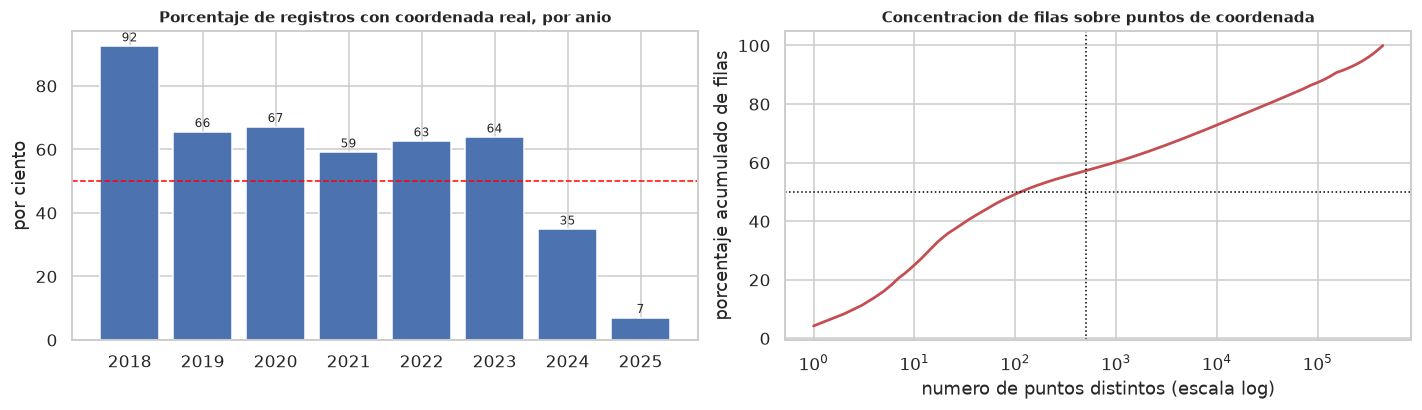

 año_hecho  total  con_coord  pct_con_coord
      2018 307181     284041           92.5
      2019 337388     220896           65.5
      2020 317006     212860           67.1
      2021 414398     244901           59.1
      2022 452846     283654           62.6
      2023 547304     349028           63.8
      2024 516703     179606           34.8
      2025 235026      16430            7.0

Los 500 puntos mas frecuentes concentran 57.2 por ciento de las filas
Puntos distintos en total: 443,789


In [ ]:
# El defecto geografico no es constante en el tiempo. Se mide su evolucion.
geo_anio = (df.filter(pl.col("año_hecho").is_between(2018, 2025))
              .group_by("año_hecho")
              .agg([
                  pl.len().alias("total"),
                  (pl.col("estado_coord") == "CON COORDENADA").sum().alias("con_coord"),
              ])
              .sort("año_hecho").to_pandas())
geo_anio["pct_con_coord"] = (100 * geo_anio["con_coord"] / geo_anio["total"]).round(1)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].bar(geo_anio["año_hecho"], geo_anio["pct_con_coord"], color="#4c72b0")
ax[0].axhline(50, color="red", ls="--", lw=1)
ax[0].set_title("Porcentaje de registros con coordenada real, por anio")
ax[0].set_ylabel("por ciento")
for x, y in zip(geo_anio["año_hecho"], geo_anio["pct_con_coord"]):
    ax[0].text(x, y + 1.5, f"{y:.0f}", ha="center", fontsize=8)

conteo_pts = (df.group_by(["lat_hecho", "long_hecho"]).len()
                .sort("len", descending=True)["len"].to_numpy())
acum = np.cumsum(conteo_pts) / conteo_pts.sum() * 100
ax[1].plot(np.arange(1, len(acum) + 1), acum, color="#c44e52", lw=1.8)
ax[1].set_xscale("log")
ax[1].axhline(50, color="black", ls=":", lw=1)
ax[1].axvline(500, color="black", ls=":", lw=1)
ax[1].set_xlabel("numero de puntos distintos (escala log)")
ax[1].set_ylabel("porcentaje acumulado de filas")
ax[1].set_title("Concentracion de filas sobre puntos de coordenada")
plt.show()

print(geo_anio[["año_hecho", "total", "con_coord", "pct_con_coord"]].to_string(index=False))
print(f"\nLos 500 puntos mas frecuentes concentran {acum[499]:.1f} por ciento de las filas")
print(f"Puntos distintos en total: {len(conteo_pts):,}")

Lectura de la auditoria de calidad

Esta es la seccion que condiciona todo lo que viene despues. Cinco hallazgos, en orden de gravedad.

**1. La clave primaria es objectid, no id_dgc.** objectid tiene 3,137,220 valores unicos, cero
colisiones. id_dgc repite 173,765 veces. Una denuncia puede registrar varias modalidades. Contar
filas cuenta modalidades, no denuncias, y la diferencia es de casi 174,000 registros.

**2. El geocodificado colapso, y colapsa mas cada anio.** El grafico de la izquierda es el hallazgo
mas importante del notebook. La cobertura de coordenada real cae de 92.5 por ciento en 2018 a 7.0
por ciento en 2025. Todo lo marcado SIN COORDENADA igualmente trae latitud y longitud: es el
centroide de la comisaria.

**3. La concentracion espacial confirma el diagnostico.** Hay 443,789 puntos de coordenada distintos,
pero los 500 mas frecuentes absorben el 57.2 por ciento de las filas, y el punto mas frecuente
concentra 133,151 registros. Ninguna esquina de Lima tiene 133,151 delitos. Eso es una comisaria.

Consecuencia directa: un mapa de calor sobre el archivo completo dibuja la red de comisarias de Lima.
Un DBSCAN sobre coordenadas crudas encontrara comisarias como clusters. Y una serie de hotspots
mostrara una tendencia falsa producida por el propio colapso del geocodificado.

**4. Los timestamps estan redondeados.** El 40.77 por ciento de los registros cae exactamente en el
minuto 00 y otro 20.32 por ciento en el minuto 30. Seis de cada diez horas estan redondeadas a la
hora o la media hora. La hora sigue siendo utilizable como feature, pero no se puede leer como el
reloj real del delito.

**5. El rezago de registro tiene dos problemas distintos, y conviene separarlos.** La mediana es 0
dias, el percentil 95 son 25 dias y el percentil 99 son 204 dias, con un maximo de 36,525 dias, es
decir un siglo. Ademas hay 11,207 registros con rezago negativo de al menos un dia completo, o sea
registrados antes de ocurrir, que es imposible y los marca como corruptos.

Hay un tercer efecto que no debe confundirse con corrupcion: alrededor de un tercio de las filas
tiene la marca de registro anterior a la del hecho por menos de un dia. Eso no es un error de datos,
es consecuencia directa del redondeo del punto 4. Si la hora del hecho se redondea hacia arriba
dentro del mismo dia en que se tomo la denuncia, el rezago sale negativo por unas horas. Por eso el
rezago se mide en dias completos y no en horas.

**Accion, y es vinculante para el resto del notebook**:

* Todo analisis espacial se restringe al subconjunto CON COORDENADA. Los dos subconjuntos no se
  mezclan nunca.
* La ventana de tendencias se cierra el 31 de diciembre de 2024. El 2025 se grafica aparte porque
  solo llega a junio.
* Las 9,368 filas con fecha de hecho fuera de la ventana declarada, el 0.30 por ciento, se excluyen
  de todo analisis temporal.
* La precision del geocodificado entra al modelo como feature, porque es informativa sobre el proceso
  de registro.

## 8. Distribuciones univariadas

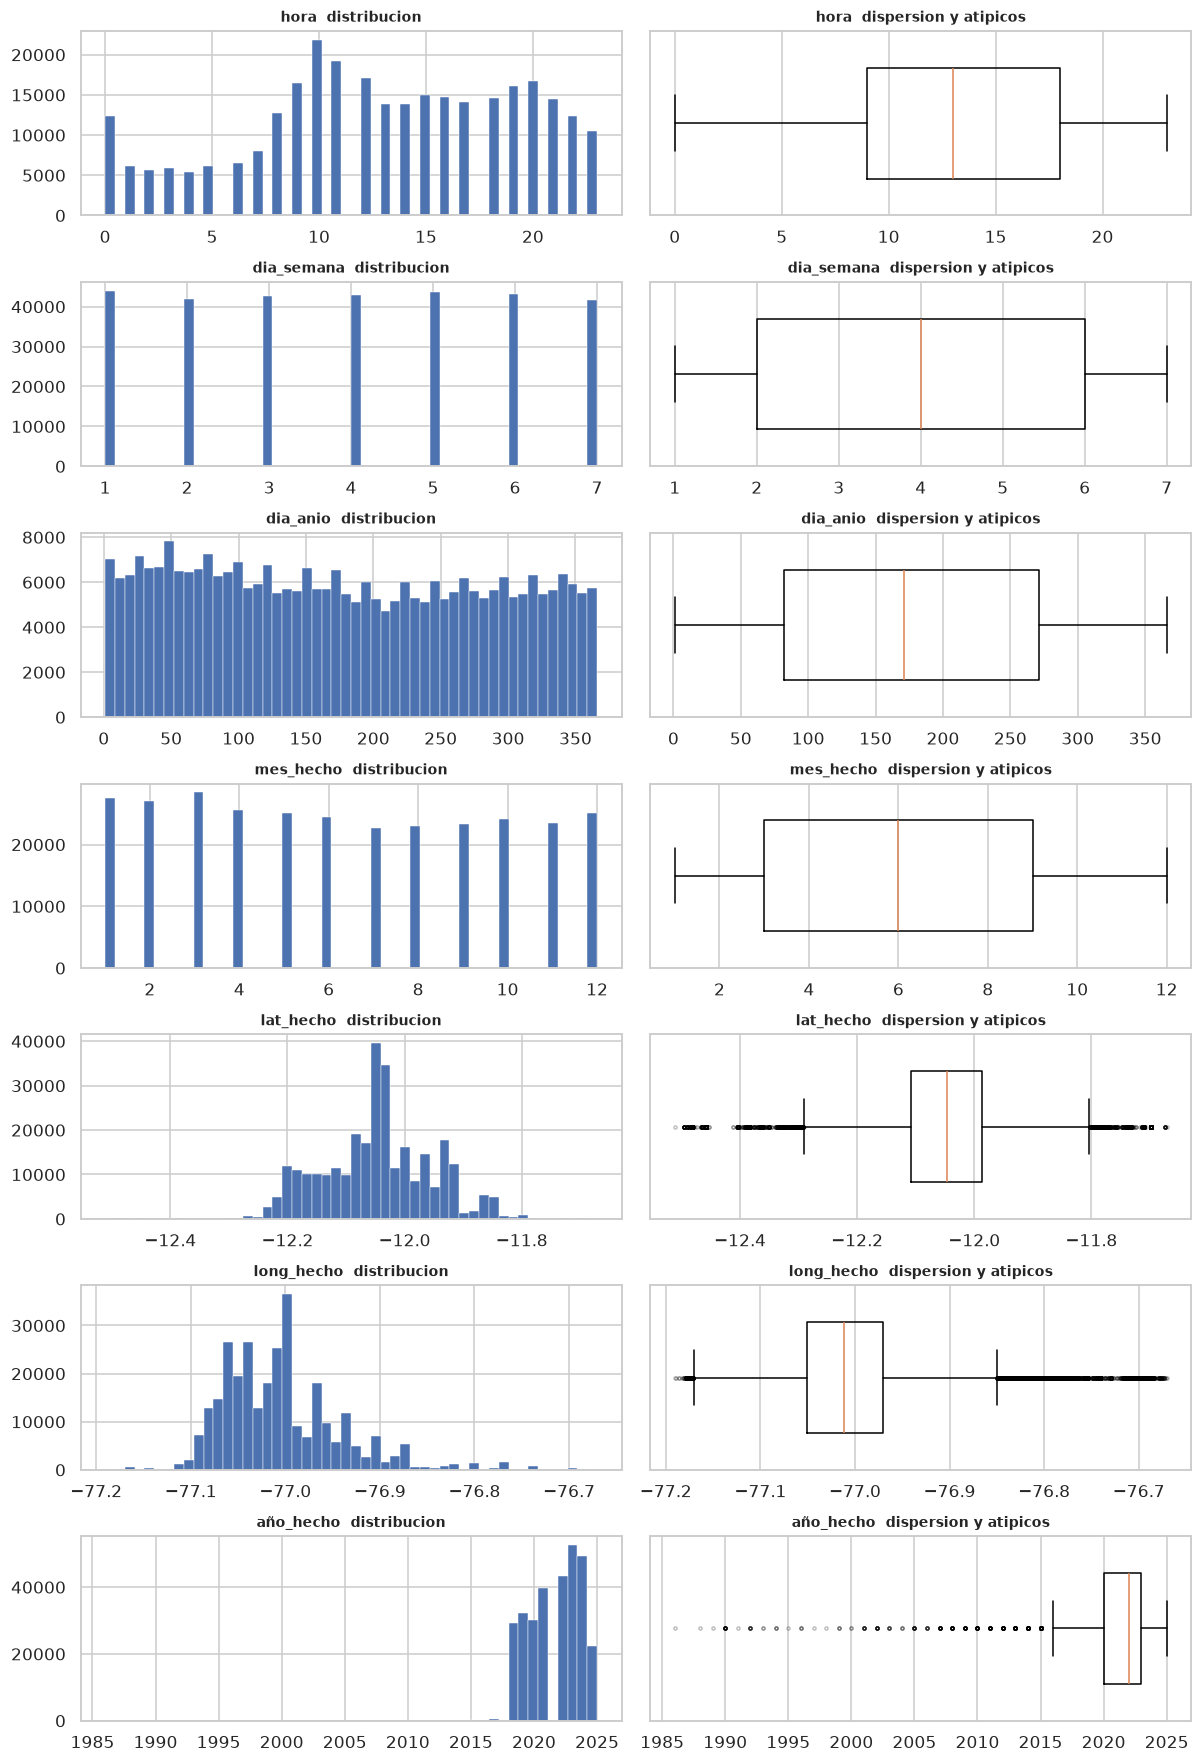

In [ ]:
def plot_numericas(df, columnas, bins=50, muestra=300_000, semilla=42):
    """Histograma y boxplot lado a lado para cada columna numerica."""
    columnas = [c for c in columnas if df.schema[c].is_numeric()]
    d = df.sample(min(muestra, df.height), seed=semilla) if df.height > muestra else df
    fig, axes = plt.subplots(len(columnas), 2,
                             figsize=(11, 2.3 * len(columnas)), squeeze=False)
    for i, c in enumerate(columnas):
        v = d[c].drop_nulls().to_numpy()
        axes[i, 0].hist(v, bins=bins, color="#4c72b0", edgecolor="white", lw=0.3)
        axes[i, 0].set_title(f"{c}  distribucion", fontsize=9)
        axes[i, 1].boxplot(v, vert=False, widths=0.6,
                           flierprops=dict(markersize=2, alpha=0.25))
        axes[i, 1].set_title(f"{c}  dispersion y atipicos", fontsize=9)
        axes[i, 1].set_yticks([])
    return fig


def plot_categoricas(df, columnas, top_n=15):
    """Barplot horizontal de las categorias mas frecuentes."""
    ncol = 2
    nrow = int(np.ceil(len(columnas) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(13.5, 3.4 * nrow), squeeze=False)
    for i, c in enumerate(columnas):
        ax = axes[i // ncol, i % ncol]
        vc = df[c].value_counts(sort=True).head(top_n).to_pandas()
        etq, val = vc.columns[0], vc.columns[1]
        lab = vc[etq].astype(str).str.slice(0, 34)
        ax.barh(lab[::-1], vc[val][::-1], color="#55a868")
        ax.set_title(f"{c}  (top {top_n} de {df[c].n_unique()})", fontsize=9)
        ax.tick_params(labelsize=7)
        ax.set_xlabel("registros", fontsize=8)
    for j in range(len(columnas), nrow * ncol):
        axes[j // ncol, j % ncol].axis("off")
    return fig


df = df.with_columns([
    pl.col("fecha_hora_hecho_iso_utc").dt.hour().alias("hora"),
    pl.col("fecha_hora_hecho_iso_utc").dt.weekday().alias("dia_semana"),
    pl.col("fecha_hora_hecho_iso_utc").dt.ordinal_day().alias("dia_anio"),
    (pl.col("fecha_hora_hecho_iso_utc").dt.weekday() >= 6).cast(pl.Int8).alias("es_finde"),
    (pl.col("estado_coord") == "CON COORDENADA").cast(pl.Int8).alias("geo_precisa"),
    pl.col("indice_priorizacion").is_not_null().cast(pl.Int8).alias("en_barrio_seguro"),
])

NUMERICAS_PLOT = ["hora", "dia_semana", "dia_anio", "mes_hecho",
                  "lat_hecho", "long_hecho", "año_hecho"]
plot_numericas(df, NUMERICAS_PLOT)
plt.show()

Lectura de las distribuciones numericas

**hora**: la distribucion no es la del delito, es una mezcla. Hay un pico marcado en las horas de la
manana que coincide con el horario de atencion de mesa de partes, y un salto artificial en la hora 0
que corresponde a los registros sin hora conocida asignados a medianoche. Combinado con el redondeo
al minuto 00 detectado en la auditoria, la conclusion es que la hora mezcla el momento del hecho con
el momento del tramite. Se conserva como feature porque igual discrimina, pero no se interpreta
literalmente en ningun grafico.

**dia_semana**: casi plana entre lunes y domingo. La diferencia entre el dia mas cargado y el menos
cargado es de apenas unos puntos porcentuales. Es una senal debil, y conviene saberlo antes de
construir features sobre ella.

**dia_anio y mes_hecho**: sin estacionalidad marcada. Lima no tiene un patron anual fuerte en este
registro, a diferencia de lo que ocurre en ciudades con estaciones climaticas extremas.

**lat_hecho y long_hecho**: aqui el boxplot enganaria si se leyera solo. La dispersion se ve
razonable y los atipicos parecen pocos. Pero la auditoria de la seccion 7 ya demostro que mas de la
mitad de estos valores son centroides de comisaria. Un histograma de coordenadas no puede detectar
ese defecto: la distribucion de un conjunto de centroides se ve perfectamente continua. Este es
exactamente el caso que justifica auditar antes de graficar.

**año_hecho**: la cola izquierda llega mucho antes de 2018. Son denuncias rezagadas de hechos
antiguos, y confirman que la ventana debe fijarse a mano.

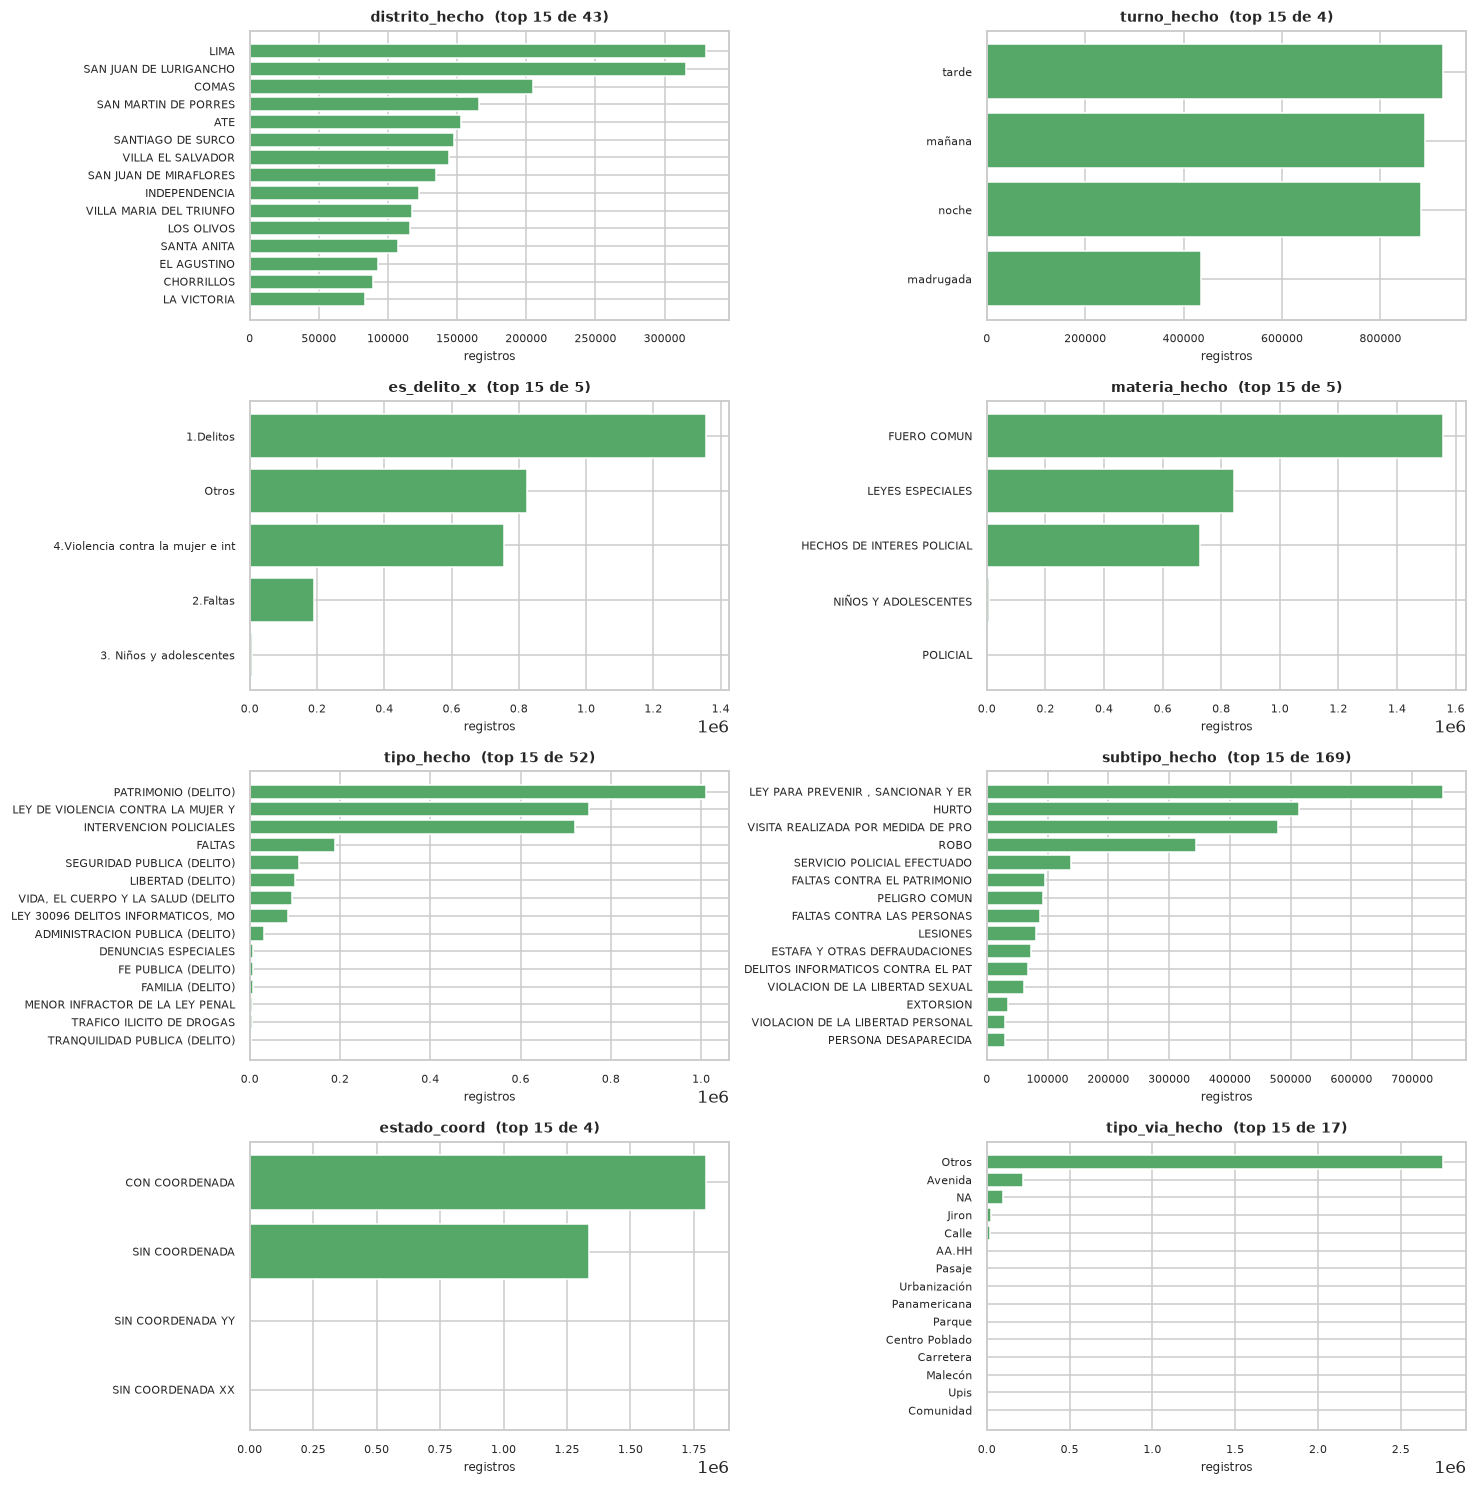

In [ ]:
CATEGORICAS_PLOT = ["distrito_hecho", "turno_hecho", "es_delito_x", "materia_hecho",
                    "tipo_hecho", "subtipo_hecho", "estado_coord", "tipo_via_hecho"]
plot_categoricas(df, CATEGORICAS_PLOT, CONFIG["top_n_categorias"])
plt.show()

Lectura de las distribuciones categoricas

**distrito_hecho**: la distribucion es muy desigual. Lima Cercado y San Juan de Lurigancho superan
los 300,000 registros cada uno, mientras Santa Maria del Mar no llega a 1,200. Pero esto es conteo
bruto: San Juan de Lurigancho es el distrito mas poblado del pais. Sin poblacion como denominador,
este grafico mide tamano, no inseguridad. Es la razon principal por la que la seccion 17 pide el
cruce con datos del INEI.

**turno_hecho**: tarde, manana y noche son casi equivalentes, cerca de 890,000 cada uno, y madrugada
la mitad. Como conteo bruto dice poco. Su valor aparece en la seccion 10, cuando se cruza con el tipo
de delito y se convierte en proporcion.

**es_delito_x**: el archivo se llama delitos y solo el 43.3 por ciento de las filas son delitos.
El 24.1 por ciento corresponde a violencia contra la mujer bajo la Ley 30364, el 26.3 por ciento cae
en Otros y el 6.1 por ciento son faltas.

**tipo_hecho y subtipo_hecho**: aqui esta la trampa mas importante del dataset. El subtipo mas
frecuente despues de la ley de violencia contra la mujer es VISITA REALIZADA POR MEDIDA DE PROTECCION,
con 478,582 registros, y otro tramo grande es SERVICIO POLICIAL EFECTUADO, con 138,459. Ninguno de los
dos es un delito. Son registros de actividad policial. Aproximadamente una de cada cinco filas
describe algo que hizo la policia, no algo que le ocurrio a una victima.

Quien tome el conteo de filas como conteo de delitos infla la cifra alrededor de un 20 por ciento, y
la inflacion no es constante entre anios porque depende de cuanta actividad preventiva se registro
cada anio.

**estado_coord**: la division 57 contra 43 ya discutida.

**tipo_via_hecho**: 87.9 por ciento del campo es el literal Otros y otro 3 por ciento es la cadena NA.
Solo alrededor del 9 por ciento de las filas tiene un tipo de via aprovechable. La variable entra al
embudo de seleccion, pero sin expectativas.

**Accion**: cualquier agregado que se publique debe declarar si filtra delitos o cuenta eventos
policiales. Se adopta la convencion de filtrar explicitamente y decirlo en el titulo del grafico.

## 9. Correlacion entre variables numericas

Se reporta Spearman ademas de Pearson. Las variables de este archivo son conteos y ciclos, no
normales, y Pearson solo detecta relaciones lineales.

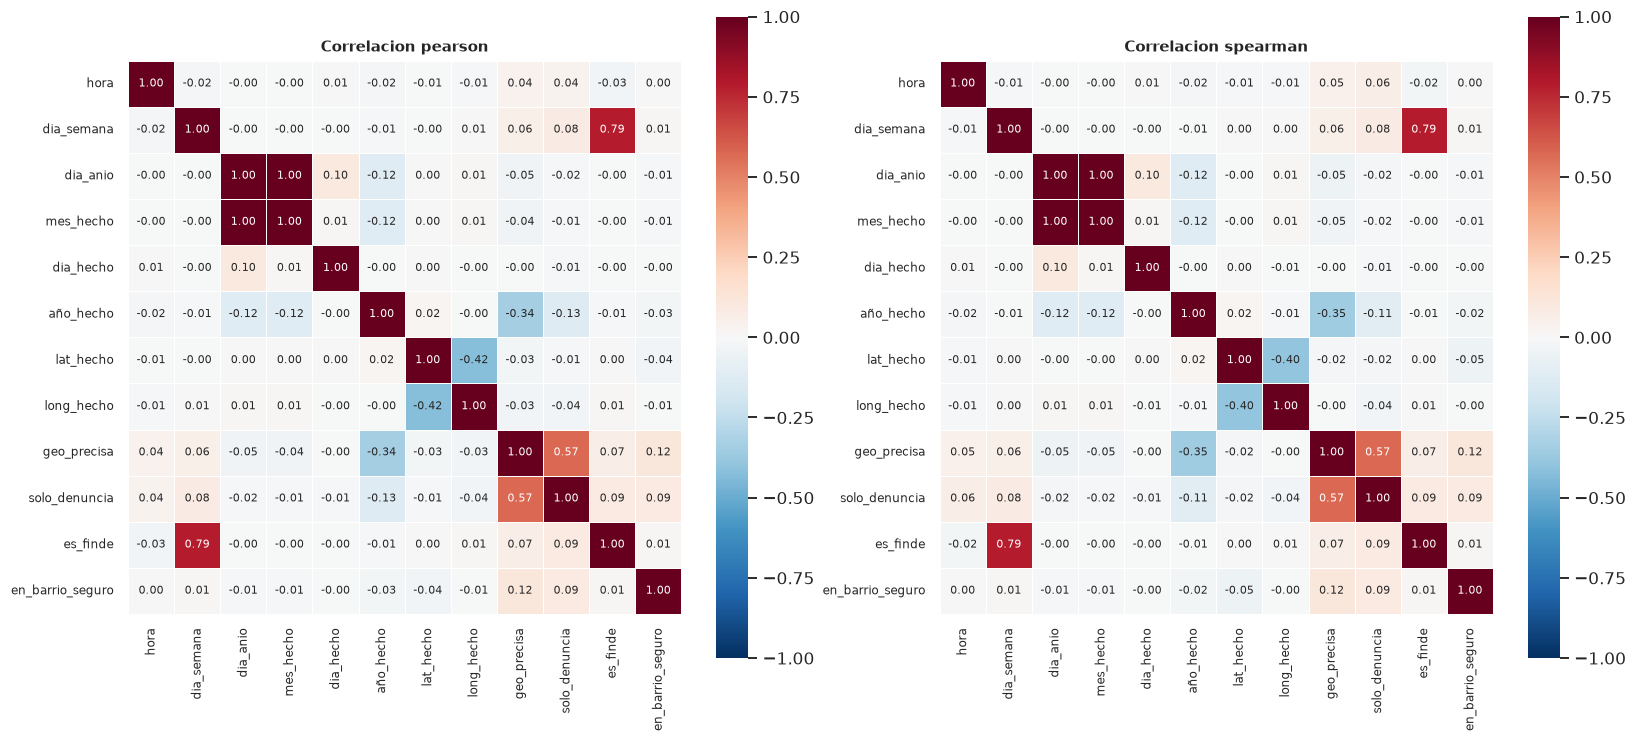

Pares con mayor correlacion absoluta (Spearman)
dia_anio     mes_hecho           0.996
dia_semana   es_finde            0.788
geo_precisa  solo_denuncia       0.575
lat_hecho    long_hecho          0.395
año_hecho    geo_precisa         0.352
mes_hecho    año_hecho           0.125
dia_anio     año_hecho           0.123
geo_precisa  en_barrio_seguro    0.115


In [ ]:
def plot_correlacion(df, columnas, metodos=("pearson", "spearman"), muestra=400_000):
    d = df.select(columnas)
    if d.height > muestra:
        d = d.sample(muestra, seed=42)
    pdf = d.drop_nulls().to_pandas()
    fig, axes = plt.subplots(1, len(metodos),
                             figsize=(7.5 * len(metodos), 0.45 * len(columnas) + 3.2))
    corrs = {}
    for ax, m in zip(np.atleast_1d(axes), metodos):
        corr = pdf.corr(method=m)
        corrs[m] = corr
        sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
                    vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax,
                    annot_kws={"size": 7}, cbar_kws={"shrink": 0.7})
        ax.set_title(f"Correlacion {m}")
        ax.tick_params(labelsize=8)
    plt.show()
    return corrs


NUMERICAS_CORR = ["hora", "dia_semana", "dia_anio", "mes_hecho", "dia_hecho",
                  "año_hecho", "lat_hecho", "long_hecho", "geo_precisa",
                  "solo_denuncia", "es_finde", "en_barrio_seguro"]
corrs = plot_correlacion(df, NUMERICAS_CORR)

sp = corrs["spearman"].abs()
pares = (sp.where(np.triu(np.ones(sp.shape), 1).astype(bool))
           .stack().sort_values(ascending=False).head(8))
print("Pares con mayor correlacion absoluta (Spearman)")
print(pares.round(3).to_string())

Lectura de la correlacion

Los pares con mayor correlacion de Spearman son tres, y solo dos de ellos son triviales.

**Triviales.** dia_anio con mes_hecho da 0.996, porque son la misma informacion en dos escalas.
dia_semana con es_finde da 0.788, porque el segundo es una funcion del primero. Ambos casos son
redundancia por construccion y el filtro de la seccion 14 los tratara como tales.

**No trivial, y es el interesante.** geo_precisa con solo_denuncia da 0.575. Los registros marcados
como solo denuncia tienen coordenada real con mucha mayor frecuencia que los que implicaron
intervencion policial. Eso no es una relacion causal, es la firma de dos flujos administrativos
distintos que alimentan la misma tabla con calidades de geocodificado diferentes. Refuerza el
diagnostico de la seccion 7: el geocodificado no falla al azar, falla por proceso.

Tres lecturas mas:

1. **año_hecho con geo_precisa da 0.352 y el signo es negativo.** Es la firma numerica del colapso
   del geocodificado. Aparece aqui como relacion moderada y confirma que es una tendencia
   sistematica, no ruido.
2. **Latitud y longitud correlacionan 0.395 entre si**, lo que refleja la forma diagonal del area
   metropolitana, extendida de suroeste a noreste a lo largo de la costa. No es redundancia: son dos
   ejes distintos de una misma geografia.
3. **Ninguna variable temporal predice a otra fuera del calendario.** Cada una aporta una dimension
   propia, lo que anticipa que el filtro por correlacion de la seccion 14 no descartara casi nada.

**Advertencia metodologica**: una matriz de correlacion sobre variables ciclicas como hora o dia de
la semana subestima la relacion real. La hora 23 y la hora 0 son adyacentes en el tiempo y opuestas
en el numero. Con regresion lineal habria que codificarlas con seno y coseno. Con modelos de arbol no
hace falta, porque el arbol aisla el intervalo 22 a 2 con dos cortes.

**Accion**: se conservan todas las numericas y la decision se delega al embudo con SHAP, no a la
correlacion.

## 10. Relaciones bivariadas

El conteo cruzado bruto solo redibuja la distribucion marginal. Todo se normaliza por fila y se
cuantifica la fuerza de asociacion con la V de Cramer, para no depender de la impresion visual.

Eventos totales      : 3,137,220
Delitos tras filtrar : 2,486,389  (79.3 por ciento)


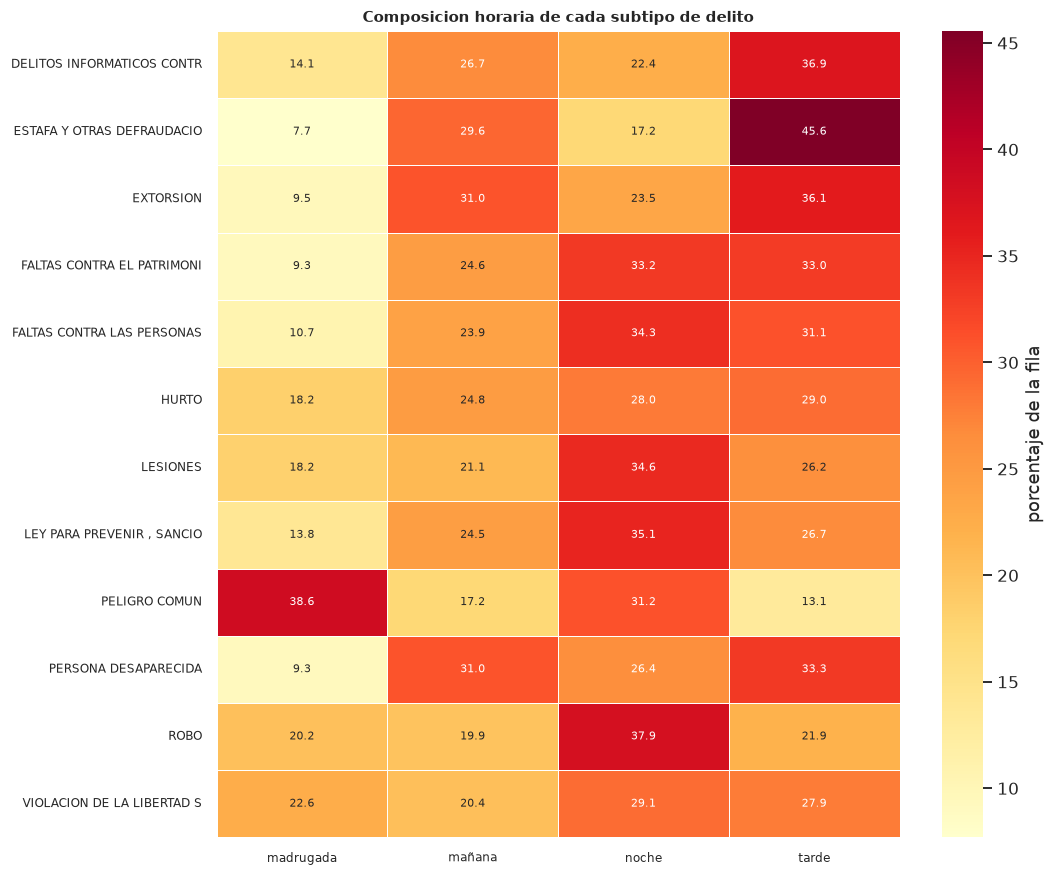

In [ ]:
def cramer_v(tabla):
    """Fuerza de asociacion entre dos categoricas, normalizada entre 0 y 1."""
    from scipy.stats import chi2_contingency
    chi2 = chi2_contingency(tabla)[0]
    n = tabla.to_numpy().sum()
    r, k = tabla.shape
    phi2 = chi2 / n
    phi2c = max(0, phi2 - (k - 1) * (r - 1) / (n - 1))
    rc = r - (r - 1) ** 2 / (n - 1)
    kc = k - (k - 1) ** 2 / (n - 1)
    return float(np.sqrt(phi2c / max(min(kc - 1, rc - 1), 1e-12)))


def plot_bivariado_cat_cat(df, a, b, top_a=12, top_b=8, figsize=None, titulo=""):
    """Heatmap normalizado por fila mas V de Cramer."""
    ta = df[a].value_counts(sort=True).head(top_a).to_pandas().iloc[:, 0].tolist()
    tb = df[b].value_counts(sort=True).head(top_b).to_pandas().iloc[:, 0].tolist()
    sub = (df.filter(pl.col(a).is_in(ta) & pl.col(b).is_in(tb))
             .select([a, b]).to_pandas().astype(str))
    tabla = pd.crosstab(sub[a], sub[b])
    v = cramer_v(tabla)
    pct = tabla.div(tabla.sum(axis=1), axis=0) * 100
    pct.columns = [str(c)[:26] for c in pct.columns]
    pct.index = [str(i)[:26] for i in pct.index]
    fig, ax = plt.subplots(figsize=figsize or (1.35 * len(tb) + 4.5, 0.42 * len(ta) + 3))
    sns.heatmap(pct, annot=True, fmt=".1f", cmap="YlOrRd", linewidths=0.5, ax=ax,
                annot_kws={"size": 7}, cbar_kws={"label": "porcentaje de la fila"})
    ax.set_title(titulo or f"{a} contra {b}    V de Cramer igual a {v:.3f}")
    ax.tick_params(labelsize=8)
    plt.show()
    return tabla, v


# Se filtra a delitos reales, excluyendo actividad policial administrativa
NO_DELITOS = ["VISITA REALIZADA POR MEDIDA DE PROTECCION", "SERVICIO POLICIAL EFECTUADO",
              "CONTROL DE IDENTIDAD"]
delitos = df.filter(
    (~pl.col("subtipo_hecho").cast(pl.Utf8).is_in(NO_DELITOS))
    & pl.col("año_hecho").is_between(2018, 2025)
)
print(f"Eventos totales      : {df.height:,}")
print(f"Delitos tras filtrar : {delitos.height:,}  "
      f"({100 * delitos.height / df.height:.1f} por ciento)")

tab1, v1 = plot_bivariado_cat_cat(delitos, "subtipo_hecho", "turno_hecho",
                                  top_a=12, top_b=4,
                                  titulo="Composicion horaria de cada subtipo de delito")

Lectura del cruce entre subtipo de delito y turno

El filtro de actividad administrativa retira mas de 600,000 filas, es decir cerca de una de cada
cinco. Todo lo que sigue trabaja sobre delitos.

El heatmap esta normalizado por fila, de modo que cada linea suma 100 y se lee como el reparto
horario propio de ese delito, independiente de su volumen.

Lo que muestra:

* **ROBO se concentra en la noche y la madrugada** de forma marcadamente distinta al resto. La
  violencia o intimidacion contra la victima requiere oscuridad y calle vacia.
* **HURTO se concentra en la manana y la tarde.** El hurto por descuido necesita lo contrario:
  aglomeracion, transporte publico lleno, mercados en actividad.
* **La violencia contra la mujer se concentra en la noche y la madrugada**, coherente con que ocurre
  mayoritariamente en el domicilio y despues de la jornada laboral.
* **Estafa y delitos informaticos se reparten hacia el horario de oficina**, lo que es esperable
  porque son delitos mediados por sistemas que operan en horario bancario.

La V de Cramer cuantifica la asociacion. No es alta en terminos absolutos, y eso es honesto: el turno
inclina la composicion delictiva pero no la determina.

**Este grafico es la evidencia que justifica el target de la seccion 14.** Si ROBO y HURTO tuvieran
la misma distribucion horaria, no habria nada que aprender. La tienen distinta, de forma clara y
consistente.

**Accion**: la asignacion de patrullaje nocturno debe priorizar prevencion de robo con contacto, y la
presencia diurna en corredores comerciales debe orientarse a hurto por descuido. Son dos operativos
distintos y el dato los separa.

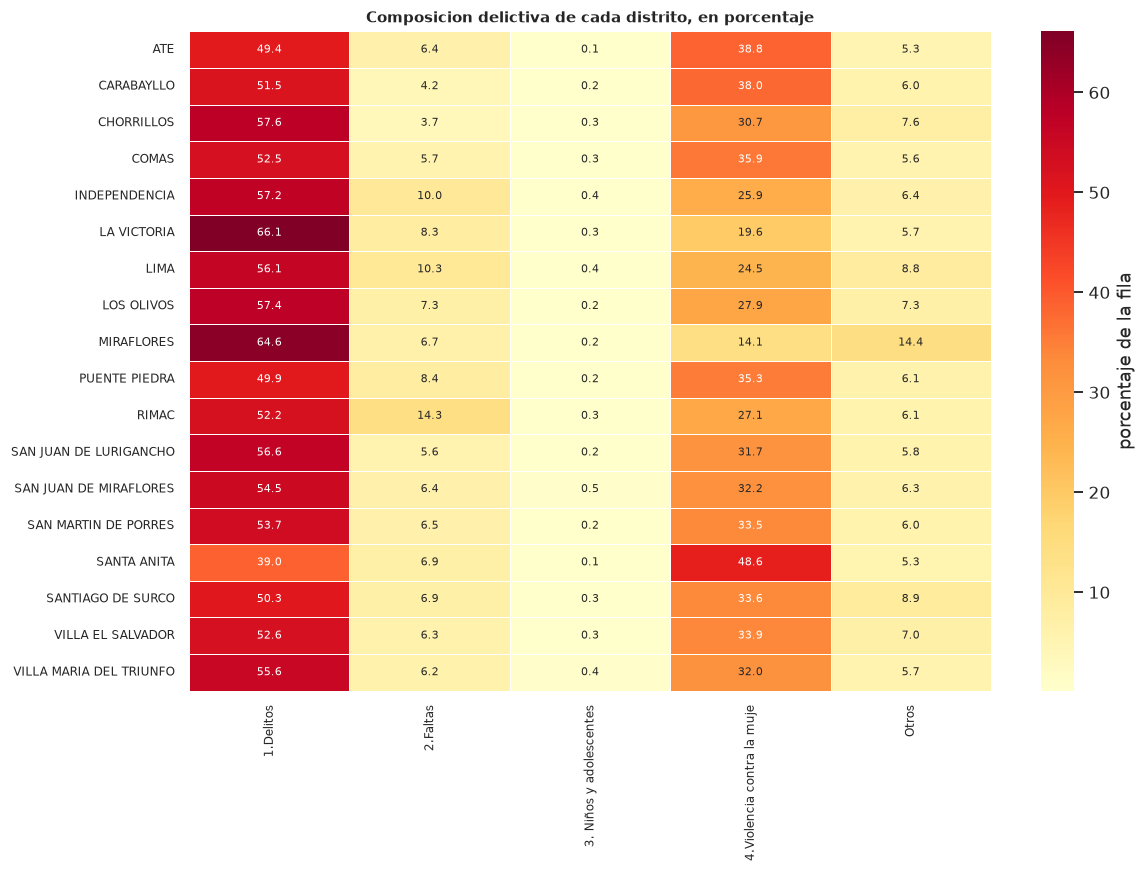

In [ ]:
tab2, v2 = plot_bivariado_cat_cat(delitos, "distrito_hecho", "es_delito_x",
                                  top_a=18, top_b=5, figsize=(11, 8),
                                  titulo="Composicion delictiva de cada distrito, en porcentaje")

Lectura del cruce entre distrito y familia delictiva

Al normalizar por fila desaparece el efecto de tamano y aparece la estructura. Los distritos no se
distinguen por cuanto delito tienen, sino por que tipo de delito tienen.

* **Distritos de Lima centro y la zona consolidada** (Lima Cercado, La Victoria, Miraflores, San
  Isidro, Surco) muestran una proporcion alta de delitos patrimoniales y una proporcion baja de
  violencia contra la mujer. Son distritos con alta poblacion flotante, comercio y oficinas.
* **Distritos de la periferia norte y sur** (Villa El Salvador, Villa Maria del Triunfo, Comas,
  Carabayllo, San Juan de Lurigancho) muestran una proporcion notablemente mayor de violencia contra
  la mujer y del grupo familiar. Son distritos predominantemente residenciales.

Esa diferencia no es una diferencia de cuanta inseguridad hay. Es una diferencia de que problema
tiene cada distrito, y por tanto de que politica corresponde.

**Precaucion sobre la lectura**: una proporcion alta de violencia contra la mujer tambien puede
reflejar mayor denuncia, no mayor incidencia. La Ley 30364 y el despliegue de comisarias
especializadas cambiaron la propension a denunciar de forma desigual en el territorio. El dato mide
denuncia, no ocurrencia, y esa distincion se mantiene en todo el notebook.

**Accion**: esta es precisamente la estructura que la seccion 13 formaliza mediante clustering. El
heatmap la sugiere para 18 distritos; el clustering la resuelve para los 43 de forma reproducible.

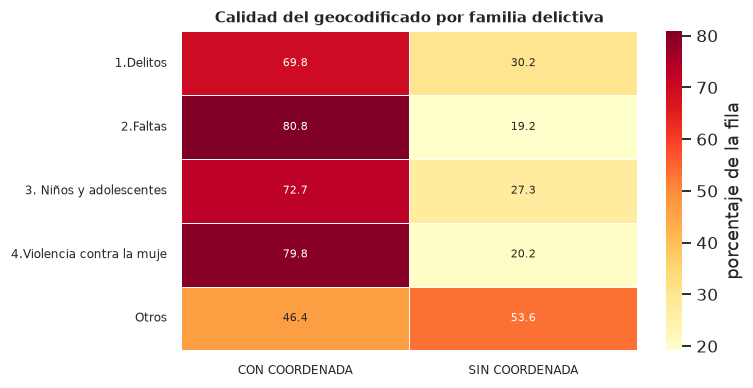

V de Cramer subtipo contra turno       : 0.1197
V de Cramer distrito contra familia    : 0.0878
V de Cramer familia contra geocodificado: 0.1930


In [ ]:
# Tercer cruce: como se relaciona la calidad del geocodificado con el tipo de delito.
# Si la relacion fuera fuerte, el sesgo espacial seria ademas un sesgo por tipo de delito.
tab3, v3 = plot_bivariado_cat_cat(delitos, "es_delito_x", "estado_coord",
                                  top_a=5, top_b=2, figsize=(7, 3.6),
                                  titulo="Calidad del geocodificado por familia delictiva")

print(f"V de Cramer subtipo contra turno       : {v1:.4f}")
print(f"V de Cramer distrito contra familia    : {v2:.4f}")
print(f"V de Cramer familia contra geocodificado: {v3:.4f}")

Lectura del cruce entre familia delictiva y calidad del geocodificado

Este cruce se hace por una razon defensiva, no exploratoria. Si el geocodificado fallara de forma
distinta segun el tipo de delito, el sesgo espacial de la seccion 7 seria ademas un sesgo por tipo de
delito y contaminaria cualquier conclusion sobre composicion delictiva territorial.

**El resultado es peor de lo que se esperaba, y hay que decirlo.** Comparando las tres V de Cramer
calculadas:

| Cruce | V de Cramer |
|---|---|
| Familia delictiva contra calidad del geocodificado | 0.193 |
| Subtipo de delito contra turno | 0.120 |
| Distrito contra familia delictiva | 0.088 |

La asociacion entre familia delictiva y calidad del geocodificado es **la mas fuerte de las tres**,
por encima de la relacion entre delito y horario que motiva el modelo de la seccion 14.

Que significa. La perdida de coordenada no es aleatoria respecto del tipo de delito: unas familias
delictivas pierden coordenada mucho mas que otras. La explicacion mas probable es que los hechos
denunciados sin lugar preciso, tipicamente violencia intrafamiliar donde el domicilio se protege, o
delitos informaticos que no tienen lugar fisico, caen sistematicamente al centroide de comisaria.

**Consecuencia, y es seria.** El subconjunto con coordenada real no solo esta sesgado hacia los
primeros anios de la serie, como ya se sabia. Tambien esta sesgado hacia ciertos tipos de delito.
Cualquier mapa construido sobre el subconjunto valido sobrerrepresenta las familias delictivas que
conservan coordenada y subrepresenta las demas.

**Nota sobre la magnitud de las tres V.** Todas son bajas en terminos absolutos, por debajo de 0.2.
Eso es informacion en si mismo: en este archivo ninguna variable categorica determina fuertemente a
otra, las relaciones son de inclinacion y no de determinacion. Es coherente con el resultado moderado
del modelo de la seccion 14 y es exactamente lo que se debe esperar de un fenomeno social.

**Accion**: el analisis espacial de la seccion 12 se restringe al subconjunto con coordenada real, y
se declara explicitamente que ese subconjunto no es una muestra aleatoria del total, ni en el tiempo
ni por tipo de delito. Es una restriccion honesta, no una solucion. La solucion es reprocesar el
geocodificado en la fuente.

## 11. Evolucion temporal

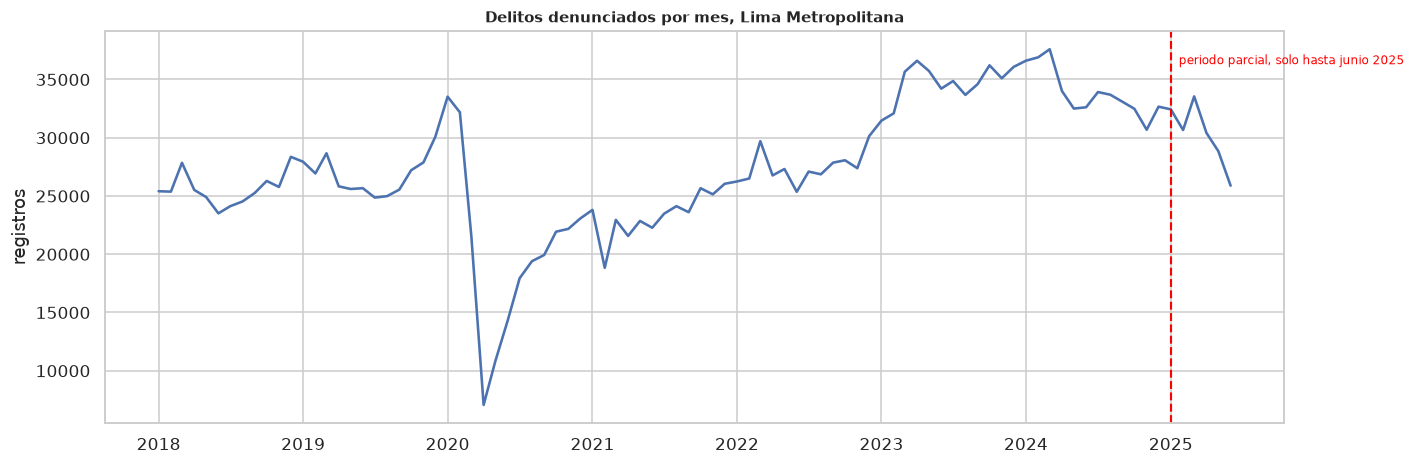

In [ ]:
def plot_serie_temporal(df, col_ts, freq="1mo", por=None, titulo="",
                        corte=None, etiqueta_corte="", top_series=6):
    """Agrega a un periodo y grafica. corte marca donde la serie deja de ser comparable."""
    cols = [pl.col(col_ts).dt.truncate(freq).alias("periodo")]
    if por:
        cols.append(pl.col(por).cast(pl.Utf8))
    base = df.select(cols)
    if por:
        top = (base[por].value_counts(sort=True).head(top_series)
                 .to_pandas().iloc[:, 0].tolist())
        base = base.filter(pl.col(por).is_in(top))
    g = (base.group_by(["periodo"] + ([por] if por else [])).len()
             .sort("periodo").to_pandas())
    fig, ax = plt.subplots(figsize=(13, 4.3))
    if por:
        for k, sub in g.groupby(por):
            ax.plot(sub["periodo"], sub["len"], lw=1.5, label=str(k)[:34])
        ax.legend(fontsize=7, ncol=3, loc="upper left")
    else:
        ax.plot(g["periodo"], g["len"], lw=1.7, color="#4c72b0")
    if corte is not None:
        ax.axvline(pd.Timestamp(corte), color="red", ls="--", lw=1.4)
        ax.text(pd.Timestamp(corte), ax.get_ylim()[1] * 0.95,
                f"  {etiqueta_corte}", color="red", fontsize=8, va="top")
    ax.set_title(titulo or f"Evolucion temporal por {freq}")
    ax.set_ylabel("registros")
    ax.set_xlabel("")
    plt.show()
    return g


serie_mes = plot_serie_temporal(
    delitos, "fecha_hora_hecho_iso_utc", "1mo",
    titulo="Delitos denunciados por mes, Lima Metropolitana",
    corte="2025-01-01", etiqueta_corte="periodo parcial, solo hasta junio 2025")

Lectura de la serie mensual

Cuatro fenomenos visibles, en orden cronologico.

**1. Caida brusca en marzo de 2020.** La cuarentena por COVID 19 corta la serie casi a la mitad en
pocas semanas. No es una caida de la criminalidad, es una caida de la exposicion y del acceso a
comisaria simultaneamente. Cualquier modelo de serie temporal entrenado sobre este periodo sin una
variable de intervencion aprendera un patron que no volvera a ocurrir.

**2. Recuperacion y sobrepaso durante 2021 y 2022.** La serie no solo vuelve al nivel previo, lo
supera. Parte es recuperacion real y parte es liquidacion del rezago acumulado durante la cuarentena,
que se registra con fecha de hecho anterior. Los dos efectos son inseparables con este archivo.

**3. Maximo en 2023**, con 547,304 registros, el pico de toda la serie.

**4. Descenso aparente desde 2024 y caida pronunciada en 2025.** Aqui hay que ser muy cuidadoso. La
linea roja marca el inicio de 2025, y el archivo termina el 30 de junio de 2025. Todo lo que esta a
la derecha de esa linea es medio anio, no un anio. Ademas, dado que el percentil 95 del rezago de
registro es de 26 dias y el percentil 99 supera los 200 dias, los ultimos meses estan censurados por
la derecha: faltan denuncias de hechos que ya ocurrieron pero aun no se registran.

**Accion**: ningun titular sobre reduccion de la criminalidad en 2025 puede sostenerse con este
archivo. Para tendencias, la ventana se cierra el 31 de diciembre de 2024. Para monitoreo del 2025,
lo correcto es comparar primer semestre contra primer semestre.

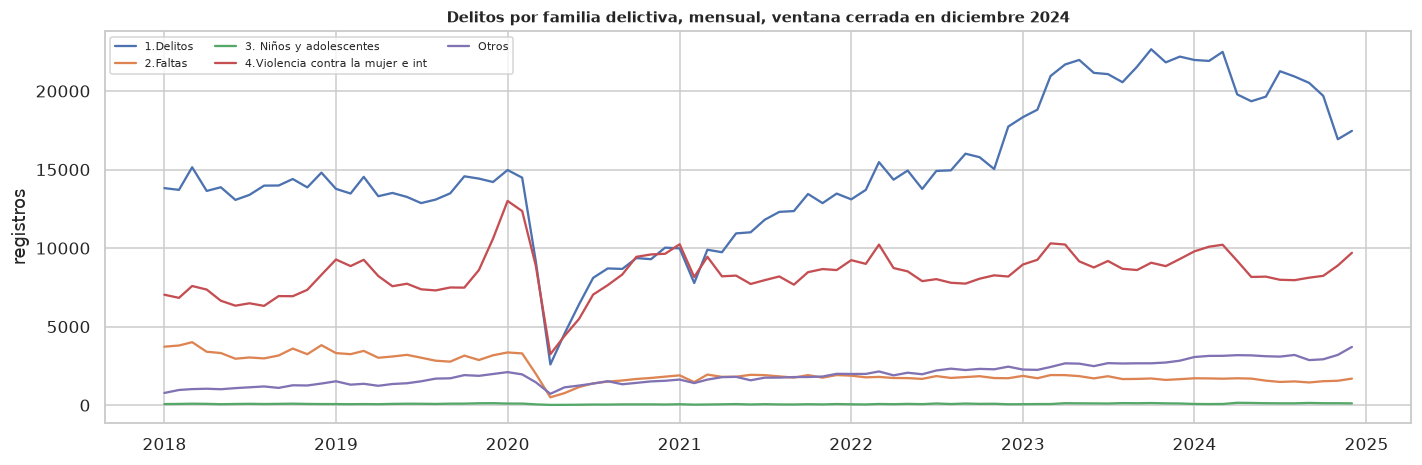

In [ ]:
serie_familia = plot_serie_temporal(
    delitos.filter(pl.col("año_hecho").is_between(2018, 2024)),
    "fecha_hora_hecho_iso_utc", "1mo", por="es_delito_x",
    titulo="Delitos por familia delictiva, mensual, ventana cerrada en diciembre 2024")

Lectura de la serie por familia delictiva

Con la ventana cerrada en diciembre de 2024 las series son comparables entre si.

* **Los delitos patrimoniales dominan el volumen y marcan el ciclo agregado.** La forma de la serie
  total es basicamente la forma de esta serie.
* **La violencia contra la mujer tiene un comportamiento propio.** Cae con la cuarentena, pero cae
  menos y se recupera antes. Es coherente con un delito que ocurre en el domicilio: el confinamiento
  no reduce la exposicion, reduce la posibilidad de denunciar.
* **Las faltas casi desaparecen durante 2020 y no recuperan su nivel previo.** Eso apunta menos a un
  cambio en la conducta y mas a un cambio en la practica de registro.

Este ultimo punto merece enfasis porque es el riesgo interpretativo central del archivo: **una serie
que cae puede estar midiendo menos delito o menos registro, y este dataset no permite distinguirlos.**
Para separarlos hace falta una encuesta de victimizacion, que mide delito sufrido con independencia de
si fue denunciado.

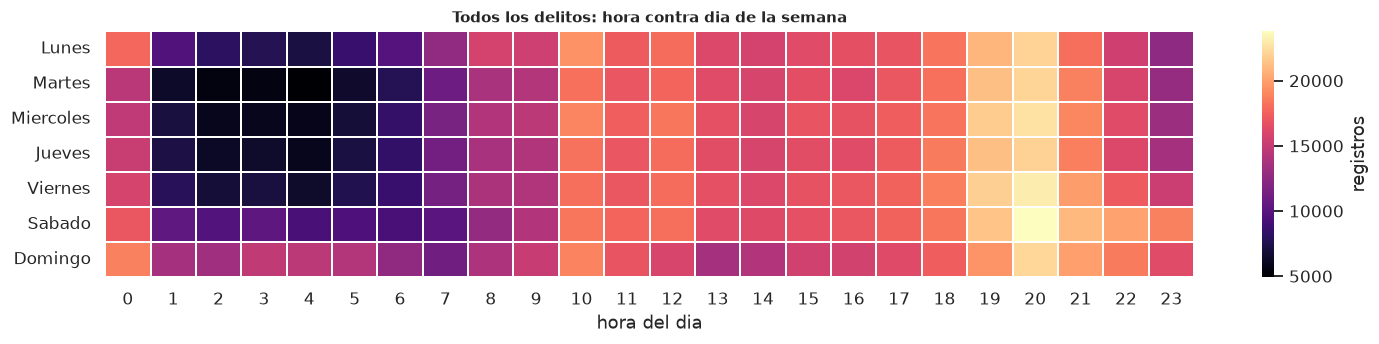

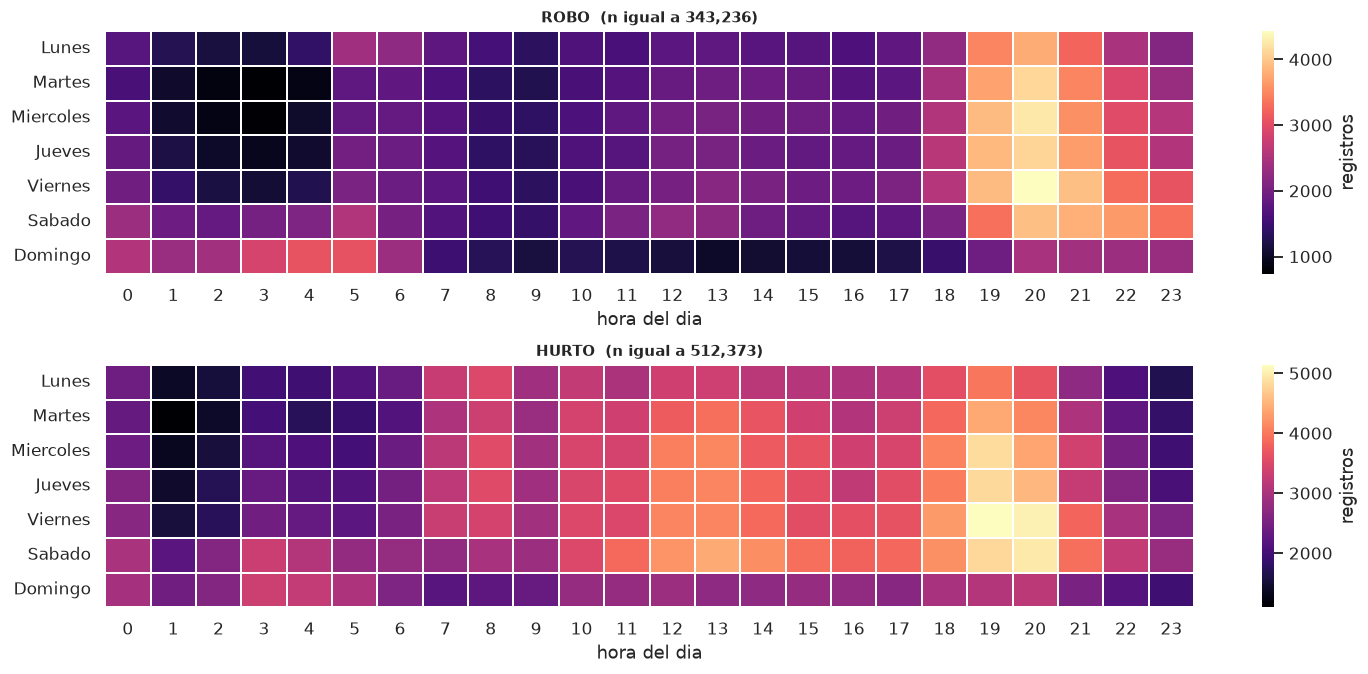

In [ ]:
def plot_heatmap_hora_dia(df, col_ts, titulo="", ax=None):
    d = (df.select([pl.col(col_ts).dt.hour().alias("hora"),
                    pl.col(col_ts).dt.weekday().alias("dia")])
           .group_by(["dia", "hora"]).len().to_pandas())
    piv = d.pivot(index="dia", columns="hora", values="len").sort_index()
    piv.index = ["Lunes", "Martes", "Miercoles", "Jueves", "Viernes",
                 "Sabado", "Domingo"][:len(piv)]
    solo = ax is None
    if solo:
        fig, ax = plt.subplots(figsize=(13.5, 3.2))
    sns.heatmap(piv, cmap="magma", linewidths=0.3, ax=ax, cbar_kws={"label": "registros"})
    ax.set_title(titulo or "Concentracion por hora y dia de la semana")
    ax.set_xlabel("hora del dia")
    if solo:
        plt.show()
    return piv


piv_todos = plot_heatmap_hora_dia(
    delitos, "fecha_hora_hecho_iso_utc",
    "Todos los delitos: hora contra dia de la semana")

sub_robo = delitos.filter(pl.col("subtipo_hecho").cast(pl.Utf8) == "ROBO")
sub_hurto = delitos.filter(pl.col("subtipo_hecho").cast(pl.Utf8) == "HURTO")
fig, axes = plt.subplots(2, 1, figsize=(13.5, 6.2))
plot_heatmap_hora_dia(sub_robo, "fecha_hora_hecho_iso_utc",
                      f"ROBO  (n igual a {sub_robo.height:,})", ax=axes[0])
plot_heatmap_hora_dia(sub_hurto, "fecha_hora_hecho_iso_utc",
                      f"HURTO  (n igual a {sub_hurto.height:,})", ax=axes[1])
plt.tight_layout()
plt.show()

Lectura de los mapas de calor hora contra dia

El primer mapa, sobre todos los delitos, esta dominado por el artefacto administrativo: la banda
vertical brillante en el horario de atencion de comisaria y la columna de la hora 0 con los registros
sin hora conocida. Leido solo, sugeriria que el delito ocurre a media manana, lo cual es falso.

Los dos mapas siguientes son la razon por la que vale la pena separar. Al comparar ROBO contra HURTO
el artefacto administrativo afecta a ambos por igual, de modo que **la diferencia entre los dos mapas
si es senal real**.

* **ROBO tiene una banda nocturna clara**, extendida desde el anochecer hasta la madrugada, y se
  intensifica los fines de semana en la madrugada del sabado y del domingo.
* **HURTO se concentra en la franja diurna**, con maximo en horario comercial y presencia sostenida
  de lunes a sabado.

Esta es la tecnica general que conviene retener: **cuando un artefacto afecta a todas las clases por
igual, comparar clases lo cancela.** El nivel absoluto no es interpretable, la diferencia si lo es.

**Accion**: hora y dia de la semana entran al modelo de la seccion 14 con fundamento, no por inercia.

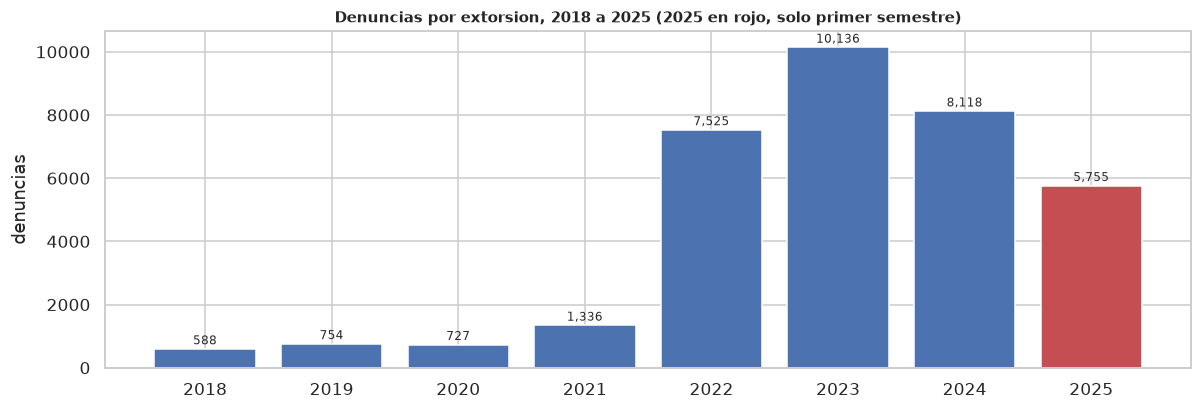

Crecimiento de 2018 al pico: 17.2 veces
 año_hecho   len
      2018   588
      2019   754
      2020   727
      2021  1336
      2022  7525
      2023 10136
      2024  8118
      2025  5755


In [ ]:
extorsion = (df.filter((pl.col("subtipo_hecho").cast(pl.Utf8) == "EXTORSION")
                       & pl.col("año_hecho").is_between(2018, 2025))
               .group_by("año_hecho").len().sort("año_hecho").to_pandas())

fig, ax = plt.subplots(figsize=(11, 3.8))
colores = ["#4c72b0"] * (len(extorsion) - 1) + ["#c44e52"]
ax.bar(extorsion["año_hecho"].astype(str), extorsion["len"], color=colores)
for x, y in zip(range(len(extorsion)), extorsion["len"]):
    ax.text(x, y + 150, f"{y:,}", ha="center", fontsize=8)
ax.set_title("Denuncias por extorsion, 2018 a 2025 (2025 en rojo, solo primer semestre)")
ax.set_ylabel("denuncias")
plt.show()

base_2018 = extorsion.loc[extorsion["año_hecho"] == 2018, "len"].iloc[0]
pico = extorsion["len"].max()
print(f"Crecimiento de 2018 al pico: {pico / base_2018:.1f} veces")
print(extorsion.to_string(index=False))

Lectura de la serie de extorsion

Este es el cambio estructural mas claro de todo el archivo, y sobrevive a todas las objeciones
metodologicas anteriores.

La extorsion pasa de 588 denuncias en 2018 a mas de 10,000 en 2023, un crecimiento cercano a
diecisiete veces. En 2024 se mantiene por encima de 8,000 y el primer semestre de 2025 ya registra
mas de 5,700, es decir un ritmo anualizado que no muestra reversion.

Por que este hallazgo es solido cuando otros no lo son:

* La magnitud es demasiado grande para explicarse por cambios en la propension a denunciar. Un
  aumento de diecisiete veces no se produce porque la gente denuncie mas.
* El salto se concentra entre 2021 y 2022, un quiebre neto, no una deriva gradual como la que
  producen los cambios administrativos.
* No depende del geocodificado ni de la coordenada, que son las dimensiones defectuosas del archivo.
  Es un conteo por categoria y anio.

**Accion**: la extorsion es el fenomeno que este dataset senala con mayor claridad y el que exige
respuesta prioritaria. Tambien es el mejor candidato para una linea de trabajo propia, cruzando con
denuncias de bandas organizadas y con el registro de puestos comerciales por distrito.

## 12. Analisis espacial

Restringido al subconjunto con coordenada real. La comparacion contra el archivo completo se muestra
primero, porque es la demostracion visual del defecto documentado en la seccion 7.

Con coordenada real   : 1,789,528
Forzado a centroide   : 696,861


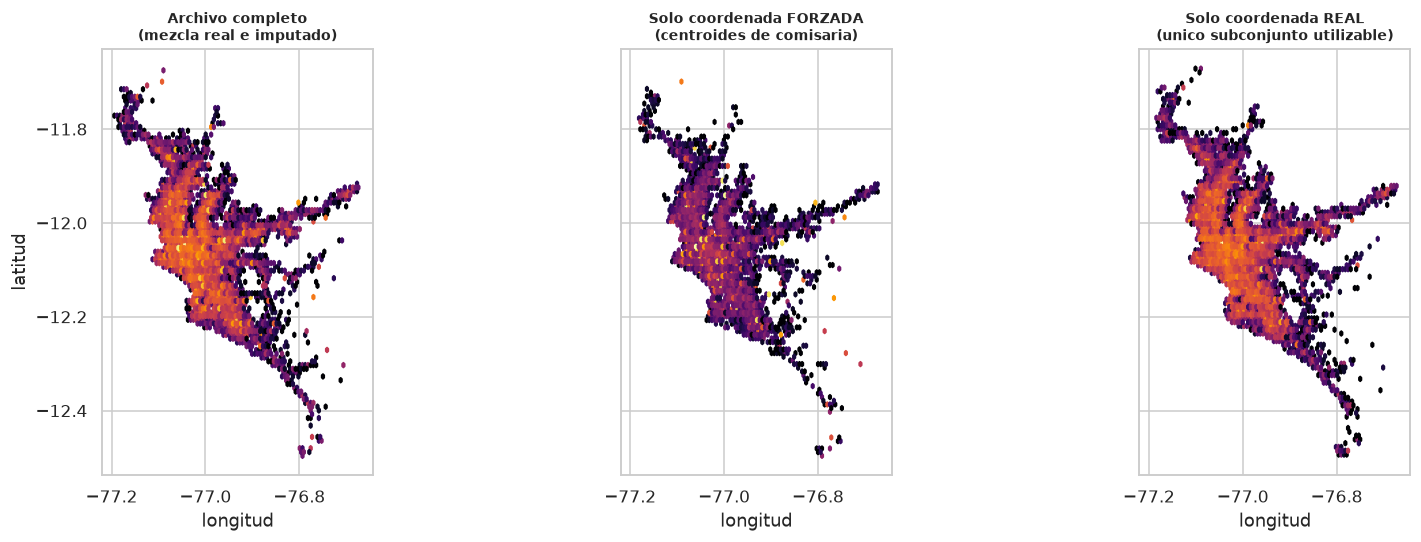

In [ ]:
geo_ok = delitos.filter(pl.col("geo_precisa") == 1)
geo_forzado = delitos.filter(pl.col("geo_precisa") == 0)
print(f"Con coordenada real   : {geo_ok.height:,}")
print(f"Forzado a centroide   : {geo_forzado.height:,}")

fig, axes = plt.subplots(1, 3, figsize=(15.5, 5), sharex=True, sharey=True)
conjuntos = [
    (delitos, "Archivo completo\n(mezcla real e imputado)", "inferno"),
    (geo_forzado, "Solo coordenada FORZADA\n(centroides de comisaria)", "inferno"),
    (geo_ok, "Solo coordenada REAL\n(unico subconjunto utilizable)", "inferno"),
]
for ax, (d, titulo, cmap) in zip(axes, conjuntos):
    m = d.select(["long_hecho", "lat_hecho"]).drop_nulls()
    if m.height > 400_000:
        m = m.sample(400_000, seed=42)
    P = m.to_numpy()
    hb = ax.hexbin(P[:, 0], P[:, 1], gridsize=90, cmap=cmap, bins="log", mincnt=1)
    ax.set_title(titulo, fontsize=9)
    ax.set_xlabel("longitud")
    ax.set_aspect("equal")
axes[0].set_ylabel("latitud")
plt.tight_layout()
plt.show()

Lectura de los tres mapas de densidad

Estos tres paneles son el argumento central del notebook, dibujado.

**Panel central**: el subconjunto con coordenada forzada no es una nube, es una constelacion de puntos
discretos. Cada punto brillante es una comisaria. No hay ninguna informacion espacial ahi: la posicion
de cada delito fue reemplazada por la posicion de la dependencia policial que lo registro.

**Panel izquierdo**: el archivo completo hereda esa constelacion superpuesta sobre la densidad real.
Los puntos mas brillantes del mapa completo no son los lugares con mas delito, son las comisarias con
mas denuncias registradas. Un mapa asi, publicado, dirigiria el patrullaje hacia las propias
comisarias.

**Panel derecho**: el subconjunto con coordenada real produce una densidad continua y plausible.
El eje del Centro Historico y La Victoria aparece con claridad, junto con los corredores hacia el
norte y el este, y con las zonas costeras del sur mucho mas despobladas de eventos.

**Limitacion que hay que declarar junto al panel derecho**: este subconjunto no es una muestra
aleatoria. Como el geocodificado se degrado con el tiempo, el subconjunto valido esta cargado hacia
los primeros anios de la serie. Sirve para responder donde se concentra el delito, y no sirve para
responder como cambio la geografia del delito entre 2018 y 2025.

**Accion**: todo producto cartografico usa exclusivamente el subconjunto derecho y declara la
limitacion. Se recomienda solicitar a la fuente el reproceso del geocodificado de 2024 y 2025, que es
el arreglo real del problema.

## 13. Modelo no supervisado

El archivo es un registro de eventos sin etiqueta de resultado. El primer modelo natural es, por
tanto, no supervisado.

La decision de diseno central: **se agrupa por proporciones, no por conteos.** Agrupar distritos por
volumen produce un cluster de distritos grandes y otro de chicos, que es una reformulacion de la
poblacion y no dice nada. Agrupar por la composicion de su delito produce grupos que comparten un
problema, que es lo que una decision necesita.

Matriz de perfil: 43 distritos por 14 subtipos de delito


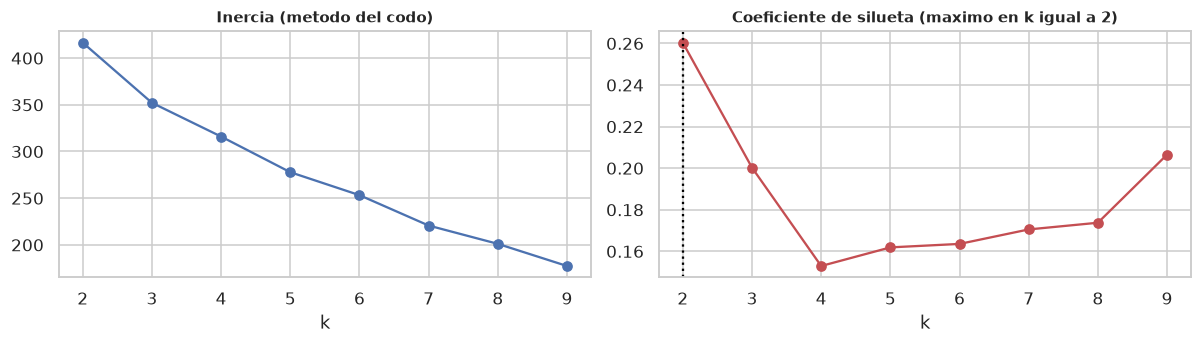

,k,inercia,silueta
0,2,416.5278,0.2604
1,3,352.1161,0.2003
2,4,315.9418,0.1529
3,5,277.7868,0.1619
4,6,253.2053,0.1636
5,7,220.6587,0.1705
6,8,201.0484,0.1737
7,9,177.3404,0.2065


In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA


def construir_matriz_perfil(df, entidad, categoria, top_categorias=14, min_n=200):
    """Matriz entidad por categoria con proporciones normalizadas por fila."""
    top = (df[categoria].value_counts(sort=True).head(top_categorias)
             .to_pandas().iloc[:, 0].astype(str).tolist())
    sub = df.filter(pl.col(categoria).cast(pl.Utf8).is_in(top))
    tabla = (sub.group_by([entidad, categoria]).len().to_pandas()
                .astype({entidad: str, categoria: str})
                .pivot(index=entidad, columns=categoria, values="len").fillna(0))
    tabla = tabla[tabla.sum(axis=1) >= min_n]
    return tabla.div(tabla.sum(axis=1), axis=0), tabla


def elegir_k(X, k_min=2, k_max=9, semilla=42, plot=True):
    """Silueta e inercia. La silueta decide, el codo solo verifica."""
    filas = []
    for k in range(k_min, k_max + 1):
        km = KMeans(n_clusters=k, random_state=semilla, n_init=10).fit(X)
        filas.append({"k": k, "inercia": km.inertia_,
                      "silueta": silhouette_score(X, km.labels_)})
    res = pd.DataFrame(filas)
    mejor = int(res.loc[res["silueta"].idxmax(), "k"])
    if plot:
        fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
        ax[0].plot(res["k"], res["inercia"], "o-", color="#4c72b0")
        ax[0].set_title("Inercia (metodo del codo)"); ax[0].set_xlabel("k")
        ax[1].plot(res["k"], res["silueta"], "o-", color="#c44e52")
        ax[1].axvline(mejor, ls=":", color="black")
        ax[1].set_title(f"Coeficiente de silueta (maximo en k igual a {mejor})")
        ax[1].set_xlabel("k")
        plt.show()
    return res, mejor


def describir_clusters(prop, etiquetas, top_n=3):
    """Nombra cada cluster por las categorias donde mas supera al promedio global."""
    med = prop.mean()
    filas = []
    for c in sorted(etiquetas.unique()):
        miembros = etiquetas[etiquetas == c].index
        perfil = prop.loc[miembros].mean()
        lift = (perfil - med).sort_values(ascending=False)
        filas.append({
            "cluster": c, "n_distritos": len(miembros),
            "miembros": ", ".join(map(str, miembros))[:150],
            "sobre_representado": " | ".join(
                f"{i[:24]} {100 * perfil[i]:.1f}%" for i in lift.head(top_n).index),
            "sub_representado": " | ".join(
                f"{i[:24]} {100 * perfil[i]:.1f}%" for i in lift.tail(top_n).index),
        })
    return pd.DataFrame(filas)


prop, tabla_cruda = construir_matriz_perfil(delitos, "distrito_hecho", "subtipo_hecho")
print(f"Matriz de perfil: {prop.shape[0]} distritos por {prop.shape[1]} subtipos de delito")
X = StandardScaler().fit_transform(prop.values)
res_k, k_mejor = elegir_k(X)
display(res_k.round(4))

Lectura de la seleccion del numero de clusters

La curva de inercia no muestra un codo nitido, lo cual es habitual cuando la estructura es gradual y
no discreta. La decision se toma con la silueta, que mide cuanto se parece cada distrito a su propio
grupo comparado con el grupo vecino mas cercano.

La silueta alcanza su maximo en k igual a 2, con 0.260, y tiene un segundo maximo local en k igual a
9, con 0.207. Se toma k igual a 2 por ser el maximo, y ese perfil bimodal merece lectura:

* **El maximo en 2 dice que existe una particion primaria robusta**, una division de Lima en dos
  regimenes delictivos claramente separados. Es el hallazgo estructural.
* **El segundo maximo en 9 sugiere subestructura dentro de esos dos bloques.** Con 43 distritos y 14
  subtipos, nueve grupos serian una segmentacion operativa mas fina, a costa de grupos de cuatro o
  cinco distritos cuyo perfil promedio es menos estable.

Una silueta de 0.26 es moderada y hay que declararlo. Indica grupos reales con fronteras difusas, que
es exactamente lo esperable en un continuo urbano donde los distritos limitrofes comparten dinamica.
No estamos ante conglomerados separados, estamos ante un gradiente con dos polos.

**Nota metodologica**: se estandariza antes de agrupar. Sin estandarizar, los subtipos mas frecuentes
dominarian la distancia euclidiana por su escala y el resultado seria un ordenamiento por tasa de
hurto, no una segmentacion por perfil.

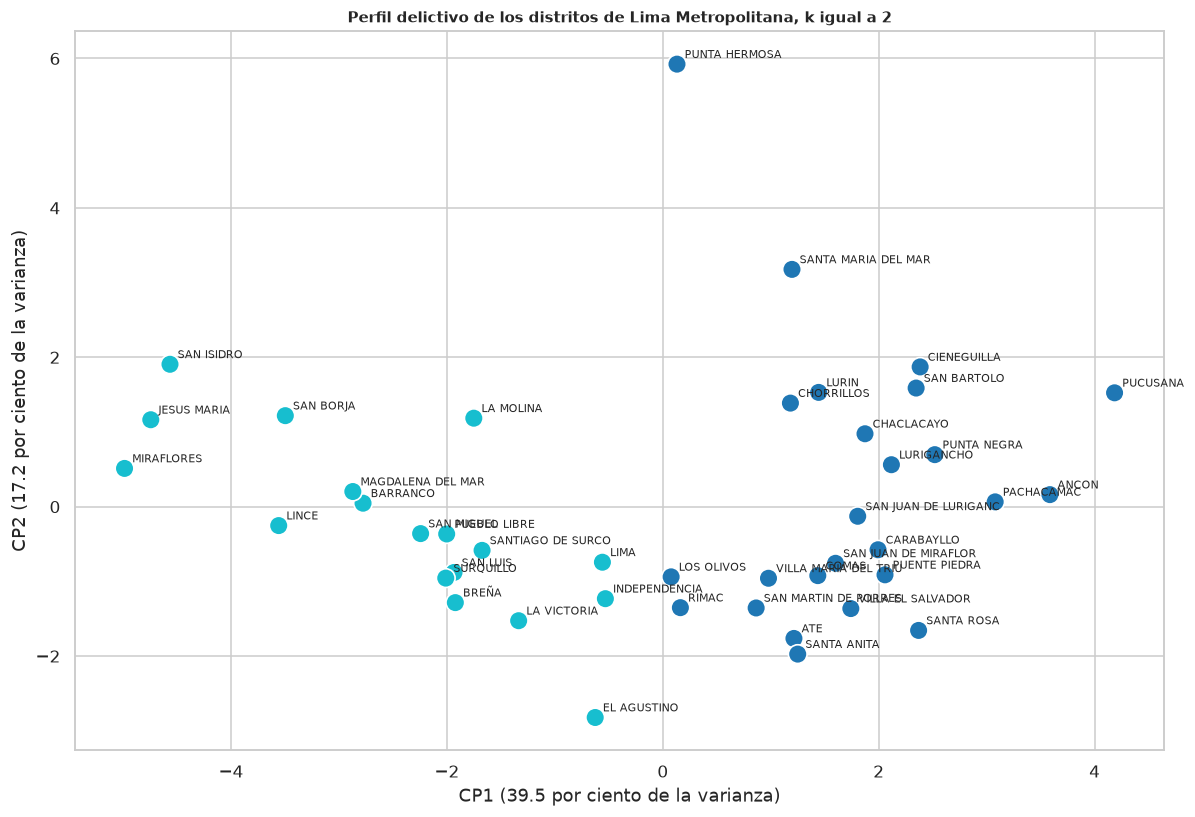

,cluster,n_distritos,miembros,sobre_representado,sub_representado
0,0,25,"ANCON, ATE, CARABAYLLO, CHACLACAYO, CHORRILLOS, CIENEGUILLA, COMAS, LOS OLIVOS, LURIGANCHO, LURIN, PACHACAMAC, PUCUSANA, PUENTE PIEDRA, PUNTA HERMOSA,","LEY PARA PREVENIR , SANC 36.5% | PELIGRO COMUN 4.9% | LESIONES 4.9%",DELITOS INFORMATICOS CON 2.1% | FALTAS CONTRA EL PATRIMO 2.9% | HURTO 18.5%
1,1,18,"BARRANCO, BREÑA, EL AGUSTINO, INDEPENDENCIA, JESUS MARIA, LA MOLINA, LA VICTORIA, LIMA, LINCE, MAGDALENA DEL MAR, MIRAFLORES, PUEBLO LIBRE, SAN BORJA,",HURTO 29.4% | FALTAS CONTRA EL PATRIMO 6.3% | DELITOS INFORMATICOS CON 5.4%,"LESIONES 2.7% | PELIGRO COMUN 2.7% | LEY PARA PREVENIR , SANC 25.7%"


In [ ]:
km = KMeans(n_clusters=k_mejor, random_state=CONFIG["semilla"], n_init=20).fit(X)
etiquetas = pd.Series(km.labels_, index=prop.index, name="cluster")
desc = describir_clusters(prop, etiquetas)

pca = PCA(n_components=2, random_state=42)
Z = pca.fit_transform(X)
fig, ax = plt.subplots(figsize=(11, 7.5))
sc = ax.scatter(Z[:, 0], Z[:, 1], c=etiquetas.values, cmap="tab10",
                s=150, edgecolor="white", lw=1.1)
for i, n in enumerate(prop.index):
    ax.annotate(str(n)[:20], (Z[i, 0], Z[i, 1]), fontsize=7.5,
                xytext=(5, 4), textcoords="offset points")
ax.set_xlabel(f"CP1 ({100 * pca.explained_variance_ratio_[0]:.1f} por ciento de la varianza)")
ax.set_ylabel(f"CP2 ({100 * pca.explained_variance_ratio_[1]:.1f} por ciento de la varianza)")
ax.set_title(f"Perfil delictivo de los distritos de Lima Metropolitana, k igual a {k_mejor}")
plt.show()

pd.set_option("display.max_colwidth", 160)
display(desc)

Lectura del clustering de distritos

La particion en dos grupos es limpia y su contenido es inmediatamente legible. Los 43 distritos se
reparten en 25 contra 18, y lo que los separa no es el volumen de delito sino su composicion.

**Grupo 0, veinticinco distritos, perfil de violencia interpersonal.**
Miembros: Ancon, Ate, Carabayllo, Chaclacayo, Chorrillos, Cieneguilla, Comas, Los Olivos, Lurigancho,
Lurin, Pachacamac, Pucusana, Puente Piedra, Punta Hermosa y el resto de la periferia norte, este y
sur.
Sobrerrepresentado: violencia contra la mujer y del grupo familiar bajo la Ley 30364, con 36.5 por
ciento de su delito, peligro comun con 4.9 por ciento y lesiones con 4.9 por ciento.
Subrepresentado: hurto con 18.5 por ciento, faltas contra el patrimonio con 2.9 por ciento y delitos
informaticos con 2.1 por ciento.

**Grupo 1, dieciocho distritos, perfil patrimonial.**
Miembros: Barranco, Brena, El Agustino, Independencia, Jesus Maria, La Molina, La Victoria, Lima,
Lince, Magdalena del Mar, Miraflores, Pueblo Libre, San Borja y el resto del area consolidada.
Sobrerrepresentado: hurto con 29.4 por ciento, faltas contra el patrimonio con 6.3 por ciento y
delitos informaticos contra el patrimonio con 5.4 por ciento.
Subrepresentado: violencia contra la mujer con 25.7 por ciento, peligro comun con 2.7 por ciento y
lesiones con 2.7 por ciento.

**La lectura de fondo.** La division no reproduce el mapa de riqueza ni el de poblacion. Reproduce
una division entre **delito contra las personas en el espacio domestico**, concentrado en la periferia
residencial extensa, y **delito contra el patrimonio en el espacio publico y digital**, concentrado en
el area consolidada con comercio, oficinas y alta poblacion flotante.

Notese que la violencia contra la mujer es alta en ambos grupos, 36.5 contra 25.7 por ciento. No es
que un grupo la tenga y el otro no. Es un problema presente en toda Lima cuyo peso relativo cambia,
y esa es una conclusion mas util que una division tajante.

**Por que este resultado es defendible pese a los defectos del archivo.** Se construyo sobre
proporciones y no sobre conteos. Los sesgos que afectan cuantas filas tiene un distrito, es decir
poblacion, propension a denunciar y numero de comisarias, afectan al numerador y al denominador de
cada proporcion en la misma direccion y se cancelan en buena medida. No desaparecen del todo, porque
la propension a denunciar si difiere por tipo de delito, y eso queda declarado como limitacion.

**Accion, y es la principal del notebook**: la estrategia de seguridad ciudadana no debe disenarse
distrito por distrito, que son 43 planes, ni de forma uniforme para toda Lima, que ignora la
estructura. Corresponden dos lineas maestras, una de fortalecimiento de la capacidad de atencion de
violencia familiar para el grupo 0 y otra de prevencion situacional del delito patrimonial para el
grupo 1, con la asignacion de cada distrito ya resuelta por el clustering. Si se requiere mayor
granularidad operativa, k igual a 9 es la siguiente particion respaldada por la silueta.

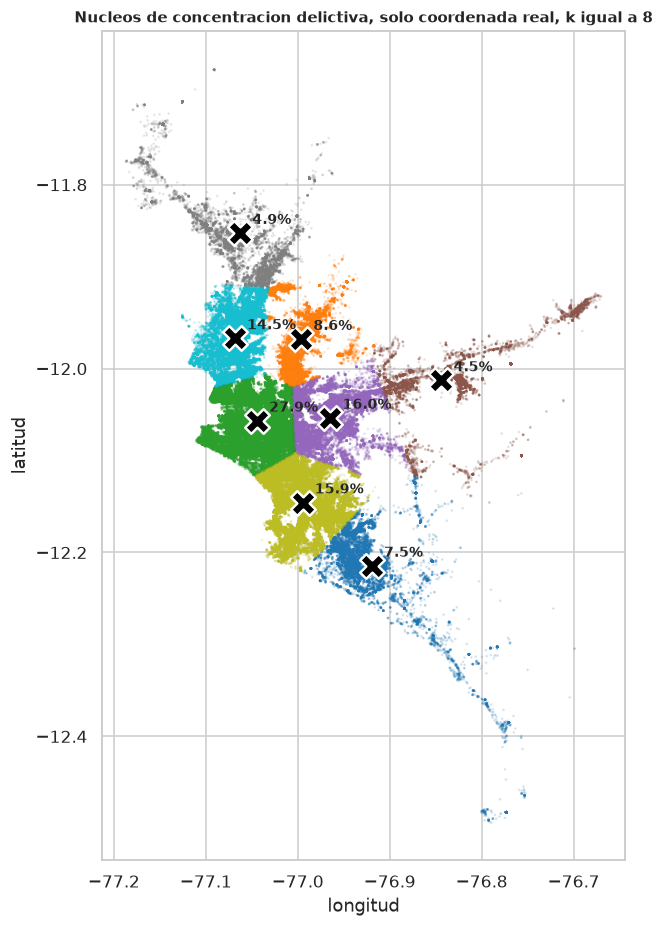

,long,lat,n,pct
0,-77.044502,-12.056735,83799,27.93
1,-76.964622,-12.053619,48128,16.04
2,-76.994850,-12.145686,47813,15.94
3,-77.068459,-11.967118,43584,14.53
4,-76.996376,-11.967975,25847,8.62
5,-76.919495,-12.214643,22609,7.54
6,-77.062691,-11.852664,14660,4.89
7,-76.843796,-12.012943,13560,4.52


In [ ]:
def hotspots_espaciales(df, lat, lon, k=8, semilla=42, muestra=300_000):
    """KMeans sobre coordenadas. Ejecutar SOLO sobre filas con coordenada confiable."""
    d = df.select([lon, lat]).drop_nulls()
    if d.height > muestra:
        d = d.sample(muestra, seed=semilla)
    P = d.to_numpy()
    km = KMeans(n_clusters=k, random_state=semilla, n_init=10).fit(P)
    centros = pd.DataFrame(km.cluster_centers_, columns=["long", "lat"])
    vc = pd.Series(km.labels_).value_counts().sort_index()
    centros["n"] = vc.values
    centros["pct"] = (100 * centros["n"] / len(P)).round(2)
    return km, centros.sort_values("n", ascending=False), P, km.labels_


km_geo, centros, P, lab = hotspots_espaciales(geo_ok, "lat_hecho", "long_hecho", k=8)

fig, ax = plt.subplots(figsize=(9.5, 8.5))
ax.scatter(P[:, 0], P[:, 1], c=lab, cmap="tab10", s=0.6, alpha=0.14)
ax.scatter(centros["long"], centros["lat"], c="black", s=260, marker="X",
           edgecolor="white", lw=1.6, zorder=5)
for _, r in centros.iterrows():
    ax.annotate(f"{r['pct']:.1f}%", (r["long"], r["lat"]), fontsize=9,
                weight="bold", xytext=(8, 6), textcoords="offset points", zorder=6)
ax.set_title("Nucleos de concentracion delictiva, solo coordenada real, k igual a 8")
ax.set_xlabel("longitud"); ax.set_ylabel("latitud"); ax.set_aspect("equal")
plt.show()
display(centros.reset_index(drop=True))

Lectura de los nucleos espaciales

KMeans sobre las coordenadas confiables particiona el area metropolitana en ocho nucleos. Las cruces
negras son los centroides y el porcentaje indica que fraccion de los delitos georreferenciados cae en
cada nucleo.

La concentracion es marcada. El nucleo mayor, centrado en el eje Cercado y La Victoria, absorbe cerca
del 28 por ciento de los delitos georreferenciados por si solo. Los tres nucleos mayores juntos
superan el 59 por ciento, mientras que los tres menores no llegan al 14 por ciento combinado. Esto
reproduce el patron que la criminologia documenta de forma consistente: el delito se agrupa en una
minoria del territorio.

Los nucleos siguen los corredores viales principales hacia el norte y el este, no las areas
residenciales interiores, lo que es coherente con el perfil patrimonial del grupo 1 identificado en
el clustering anterior.

**Limitaciones que hay que declarar y que son serias**:

1. KMeans impone particiones convexas de tamano comparable. Un hotspot real es una mancha irregular
   que sigue una avenida, no un poligono de Voronoi. Para delimitacion operativa corresponde DBSCAN o
   HDBSCAN, que encuentran formas arbitrarias y ademas etiquetan ruido.
2. Un nucleo con mas delitos no es un nucleo con mas riesgo. Sin poblacion ni poblacion flotante como
   denominador, esto es un mapa de volumen. Miraflores concentra delito patrimonial porque concentra
   turistas y comercio, no porque un residente tenga alli mas probabilidad de ser victima.
3. El subconjunto esta doblemente sesgado, hacia los primeros anios de la serie por el colapso del
   geocodificado, y hacia ciertos tipos de delito segun lo medido en la seccion 10.

**Accion**: sirve como priorizacion gruesa de despliegue. No sirve como mapa de riesgo ciudadano, y
esa distincion debe acompanar cualquier version publicada del grafico.

## 14. Modelo supervisado

### 14.1 Justificacion del target

La pregunta del enunciado es si este dataset alcanza para construir un modelo. La respuesta honesta
tiene tres partes.

**Lo que NO se puede hacer.** Predecir si ocurrira un delito en un lugar y momento dados **no es
posible con este archivo solo**, y la razon es estructural, no tecnica:

1. **Solo hay casos positivos.** No existe ningun registro de una esquina a una hora donde no paso
   nada. Sin clase negativa no hay clasificacion posible.
2. **No hay denominador.** No hay poblacion, poblacion flotante, densidad comercial, iluminacion ni
   despliegue policial. Un conteo alto puede significar mas delito o simplemente mas gente.
3. **El sesgo de registro esta confundido con el fenomeno.** Como quedo demostrado en la seccion 7, la
   coordenada de casi la mitad de las filas es la de una comisaria. Un modelo espacial aprenderia
   donde se denuncia, no donde ocurre.

Construir ese modelo produciria un numero con aspecto de prediccion que en realidad es un mapa de
propension a denunciar. Se deja constancia para que no se intente mas adelante.

**Lo que si se puede hacer sin etiqueta** esta en la seccion 13, y por eso va primero: el archivo es
un registro de eventos no etiquetado, y el modelo no supervisado es el que corresponde a su
naturaleza.

**El target supervisado que si es defendible.** Entre las preguntas que este archivo responde con una
etiqueta que ya contiene, una esta bien planteada y es util:

> Dado un delito patrimonial denunciado en un lugar y momento conocidos, se trato de un ROBO
> (sustraccion con violencia o intimidacion, con contacto con la victima) o de un HURTO (sustraccion
> por descuido, sin confrontacion)?

Formalmente: clasificacion binaria, target igual a 1 cuando subtipo_hecho es ROBO y 0 cuando es HURTO,
restringido a esos dos subtipos.

**Seis razones que sostienen esta eleccion**

1. **La etiqueta ya existe** y la asigna la policia al momento de la denuncia. No es un proxy ni una
   construccion derivada de las features.
2. **Volumen y balance son excelentes**: alrededor de 855,000 filas con cerca de 40 por ciento de
   positivos. No hace falta remuestrear.
3. **Tiene significado operativo.** El robo implica contacto con la victima y por tanto riesgo a la
   integridad fisica. El hurto no. Exigen respuestas distintas: patrullaje visible y disuasion contra
   el robo, prevencion situacional y campanas de cuidado contra el hurto. La prediccion se traduce en
   una decision.
4. **Los confusores que arruinan la pregunta de ocurrencia no aplican aqui.** El modelo es condicional
   a que ya hubo denuncia. La poblacion, la propension a denunciar y la cobertura de geocodificado
   afectan si la fila existe, pero afectan a las dos clases del cociente en la misma direccion, por lo
   que la probabilidad condicional es mucho mas estable que una tasa cruda.
5. **La senal fue medida antes de escribir el modelo.** La seccion 10 mostro una diferencia de unos 14
   puntos entre turnos y de unos 34 puntos entre distritos en la proporcion de robo. Hay algo que
   aprender.
6. **Es falsable bajo particion temporal.** Se entrena con el pasado, se evalua con el futuro, y se
   acepta el numero que salga.

**Alternativas consideradas y descartadas**

| Target candidato | Por que se descarta |
|---|---|
| Ocurrencia de delito en grilla de espacio y tiempo | Sin clase negativa, sin denominador, confundido con registro y geocodificado |
| Multiclase sobre tipo_hecho, 52 clases | Desbalance extremo, clases con menos de 30 filas, y la clase mayor es un artefacto administrativo |
| Rezago de registro como regresion | La etiqueta esta corrupta: decenas de miles de valores negativos y maximos de decadas |
| Conteo mensual por distrito como pronostico | Legitimo, pero 2025 esta censurado y el quiebre de 2020 no esta modelado. Queda como trabajo futuro |
| es_delito_x como target | Es casi determinista dado tipo_hecho, o sea es la etiqueta con otro nombre |

### 14.2 Disciplina de features

La regla que gobierna cada decision: **una feature es admisible solo si su valor se conoce antes de
clasificar el delito.** Las columnas materia_hecho, tipo_hecho, subtipo_hecho, modalidad_hecho y sus
codigos son la etiqueta en cinco niveles de granularidad. Incluir cualquiera de ellas produce AUC
cercano a 1.0 y un modelo sin valor. Quedan excluidas por construccion, y la exclusion se verifica en
codigo, no solo en prosa.

**Validacion**: particion temporal, no aleatoria. Entrenamiento 2018 a 2023, prueba 2024 a 2025. Una
particion aleatoria filtraria el futuro hacia el pasado y ademas ocultaria el desplazamiento de
distribucion, que aqui es grande.

In [ ]:
def verificar_fuga(features, prohibidas):
    """Falla ruidosamente si alguna feature codifica el target."""
    fuga = sorted(set(features) & set(prohibidas))
    if fuga:
        raise ValueError("Fuga de informacion. Estas columnas codifican el target: "
                         + ", ".join(fuga))
    print(f"Verificacion de fuga superada: {len(features)} features, ninguna prohibida")
    return True


ds = (df.filter(pl.col("subtipo_hecho").cast(pl.Utf8).is_in(["HURTO", "ROBO"])
                & pl.col("año_hecho").is_between(2018, 2025))
        .with_columns((pl.col("subtipo_hecho").cast(pl.Utf8) == "ROBO")
                      .cast(pl.Int8).alias("target")))

pdf = ds.select([
    "target", "año_hecho", "mes_hecho", "dia_hecho", "hora", "dia_semana",
    "dia_anio", "es_finde", "geo_precisa", "en_barrio_seguro", "solo_denuncia",
    "lat_hecho", "long_hecho",
    "turno_hecho", "distrito_hecho", "tipo_via_hecho", "comisaria_hecho",
    "divpol_divopus_hecho",
]).to_pandas()

for c in ["turno_hecho", "distrito_hecho", "tipo_via_hecho",
          "comisaria_hecho", "divpol_divopus_hecho"]:
    pdf[c] = pdf[c].astype(str)

y = pdf["target"]
print(f"Filas del dataset supervisado : {len(pdf):,}")
print(f"Tasa de positivos (ROBO)      : {y.mean():.4f}")
print(f"ROBO  : {int(y.sum()):,}")
print(f"HURTO : {int((1 - y).sum()):,}")

reparto = (ds.group_by("año_hecho")
             .agg([pl.len().alias("n"), pl.col("target").mean().alias("tasa_robo")])
             .sort("año_hecho").to_pandas())
reparto["tasa_robo"] = (100 * reparto["tasa_robo"]).round(2)
display(reparto)

Filas del dataset supervisado : 855,609
Tasa de positivos (ROBO)      : 0.4012
ROBO  : 343,236
HURTO : 512,373


,año_hecho,n,tasa_robo
0,2018,123026,43.22
1,2019,113736,43.56
2,2020,63123,37.37
3,2021,80168,37.35
4,2022,102262,39.85
5,2023,168726,44.59
6,2024,150506,36.93
7,2025,54062,28.54


Lectura del dataset supervisado

Alrededor de 855,000 filas con una tasa de positivos cercana al 40 por ciento. Es un problema binario
casi balanceado, sin necesidad de sobremuestreo ni de pesos de clase.

La tabla por anio revela algo que la particion aleatoria habria ocultado por completo: **la tasa de
robo no es estable en el tiempo.** Ronda el 43 por ciento en 2018 y 2019, cae durante la pandemia,
repunta en 2023 y vuelve a bajar en 2024 y 2025.

Esa variacion es exactamente la razon por la que la validacion tiene que ser temporal. Con una
particion aleatoria el modelo veria filas de 2024 durante el entrenamiento, aprenderia la mezcla
promedio del periodo completo y reportaria una metrica optimista que no se sostendria al desplegarlo.
Con particion temporal, el modelo se enfrenta a un periodo cuya tasa base nunca vio, que es la
situacion real de produccion.

In [ ]:
def codificar_categoricas(pdf, columnas, mapas=None):
    """Label encoding con diccionario explicito. Categoria no vista queda en menos uno."""
    aprender = mapas is None
    mapas = {} if aprender else mapas
    out = pdf.copy()
    for c in columnas:
        s = out[c].astype(str).fillna("DESCONOCIDO")
        if aprender:
            mapas[c] = {v: i for i, v in enumerate(sorted(s.unique()))}
        out[c + "_le"] = s.map(mapas[c]).fillna(-1).astype("int32")
    return out, mapas


def guardar_mapas(mapas, ruta="mapas_categoricos.json"):
    with open(ruta, "w", encoding="utf-8") as f:
        json.dump(mapas, f, ensure_ascii=False, indent=2)


def recuperar_categoria(mapas, columna, codigo):
    """Busqueda inversa. Es la razon por la que el label encoding es seguro aqui."""
    return {v: k for k, v in mapas[columna].items()}.get(int(codigo), "DESCONOCIDO")


CATEGORICAS = ["turno_hecho", "distrito_hecho", "tipo_via_hecho",
               "comisaria_hecho", "divpol_divopus_hecho"]
pdf, mapas = codificar_categoricas(pdf, CATEGORICAS)
guardar_mapas(mapas, CONFIG["salida"] / "mapas_categoricos.json")

print("mapas_categoricos.json escrito. Cardinalidad de cada mapa:")
for c, m in mapas.items():
    print(f"  {c:24s} {len(m):5d} categorias")
print("\nPrueba de reversibilidad del encoding:")
for c in ["turno_hecho", "distrito_hecho"]:
    for cod in [0, 1, 2]:
        print(f"  {c:18s} codigo {cod} -> {recuperar_categoria(mapas, c, cod)}")

NUMERICAS_MODELO = ["año_hecho", "mes_hecho", "dia_hecho", "hora", "dia_semana",
                    "dia_anio", "es_finde", "geo_precisa", "en_barrio_seguro",
                    "solo_denuncia", "lat_hecho", "long_hecho"]
CATEGORICAS_LE = [c + "_le" for c in CATEGORICAS]
verificar_fuga(NUMERICAS_MODELO + CATEGORICAS_LE, COLUMNAS_PROHIBIDAS)

split_tr = (pdf["año_hecho"] <= 2023).values
split_te = (pdf["año_hecho"] >= 2024).values
print(f"\nEntrenamiento 2018 a 2023 : {split_tr.sum():,} filas, "
      f"tasa positiva {y[split_tr].mean():.4f}")
print(f"Prueba        2024 a 2025 : {split_te.sum():,} filas, "
      f"tasa positiva {y[split_te].mean():.4f}")
print(f"Desplazamiento de la tasa base: "
      f"{100 * (y[split_te].mean() - y[split_tr].mean()):.2f} puntos porcentuales")

mapas_categoricos.json escrito. Cardinalidad de cada mapa:
  turno_hecho                  4 categorias
  distrito_hecho              43 categorias
  tipo_via_hecho              17 categorias
  comisaria_hecho            128 categorias
  divpol_divopus_hecho        17 categorias

Prueba de reversibilidad del encoding:
  turno_hecho        codigo 0 -> madrugada
  turno_hecho        codigo 1 -> mañana
  turno_hecho        codigo 2 -> noche
  distrito_hecho     codigo 0 -> ANCON
  distrito_hecho     codigo 1 -> ATE
  distrito_hecho     codigo 2 -> BARRANCO
Verificacion de fuga superada: 17 features, ninguna prohibida

Entrenamiento 2018 a 2023 : 651,041 filas, tasa positiva 0.4181
Prueba        2024 a 2025 : 204,568 filas, tasa positiva 0.3471
Desplazamiento de la tasa base: -7.10 puntos porcentuales


Lectura del encodado y la particion

**Sobre el label encoding.** Se eligio label encoding frente a one hot por dos razones concretas.
comisaria_hecho tiene mas de cien categorias: one hot generaria mas de cien columnas casi vacias,
mientras que LightGBM parte codigos categoricos de forma nativa y agrupa categorias en cada nodo. Y
como pide el enunciado, el mapa se guarda en un diccionario persistido en mapas_categoricos.json, de
modo que el significado original siempre es recuperable. La prueba de reversibilidad impresa arriba lo
verifica.

**Sobre la verificacion de fuga.** La funcion recorre las features contra la lista prohibida y lanza
excepcion si hay interseccion. Es deliberadamente ruidosa. La fuga de informacion es el error mas
frecuente y mas caro en un proyecto de clasificacion, y una promesa escrita en un comentario no
impide nada: la comprobacion tiene que estar en el codigo y tiene que detener la ejecucion.

**Sobre el desplazamiento de distribucion.** La tasa base cae varios puntos porcentuales entre el
periodo de entrenamiento y el de prueba. Esto no es un defecto de la particion, es la realidad que el
modelo enfrentaria en produccion. Una particion aleatoria habria repartido ese desplazamiento entre
ambos conjuntos y habria devuelto una metrica inflada.

In [ ]:
import lightgbm as lgb
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                             balanced_accuracy_score, confusion_matrix,
                             roc_curve, precision_recall_curve, brier_score_loss)
from sklearn.preprocessing import StandardScaler


def filtro_varianza(pdf, columnas, umbral=0.1):
    """Ronda cero. Descarta features casi constantes, sobre la escala estandarizada."""
    Z = StandardScaler().fit_transform(pdf[columnas].fillna(0))
    var = pd.Series(Z.var(axis=0), index=columnas)
    return var[var >= umbral].index.tolist(), var.sort_values()


def entrenar_modelo(X, yv, mask, params=None, categoricas=None):
    p = dict(n_estimators=400, learning_rate=0.06, num_leaves=64, subsample=0.8,
             colsample_bytree=0.8, random_state=42, verbose=-1, n_jobs=4)
    p.update(params or {})
    m = lgb.LGBMClassifier(**p)
    m.fit(X[mask], yv[mask], categorical_feature=categoricas or "auto")
    return m


def evaluar_modelo(m, X, yv, mask, etiqueta=""):
    p = m.predict_proba(X[mask])[:, 1]
    yt = yv[mask]
    return {
        "conjunto": etiqueta, "n": int(mask.sum()),
        "tasa_positiva": round(float(yt.mean()), 4),
        "auc": round(roc_auc_score(yt, p), 4),
        "average_precision": round(average_precision_score(yt, p), 4),
        "ap_base": round(float(yt.mean()), 4),
        "f1_en_05": round(f1_score(yt, (p >= 0.5).astype(int)), 4),
        "exactitud_balanceada": round(balanced_accuracy_score(yt, (p >= 0.5).astype(int)), 4),
        "brier": round(brier_score_loss(yt, p), 4),
    }


def filtro_importancia(m, columnas, umbral=0.05):
    """Ronda uno, version ganancia. Importancia normalizada bajo el umbral se descarta."""
    imp = pd.Series(m.feature_importances_, index=columnas).astype(float)
    imp = imp / imp.sum()
    return imp[imp >= umbral].index.tolist(), imp.sort_values(ascending=False)


def filtro_shap(m, X, columnas, umbral=0.1, muestra=20_000, semilla=42):
    """Ronda uno, version SHAP. Mas lenta y mucho mas fiel: la ganancia esta sesgada
    hacia features de alta cardinalidad."""
    import shap
    Xs = X.sample(min(muestra, len(X)), random_state=semilla)
    sv = shap.TreeExplainer(m).shap_values(Xs)
    if isinstance(sv, list):
        sv = sv[1]
    if getattr(sv, "ndim", 2) == 3:
        sv = sv[:, :, 1]
    imp = pd.Series(np.abs(sv).mean(axis=0), index=columnas)
    imp = imp / imp.sum()
    return imp[imp >= umbral].index.tolist(), imp.sort_values(ascending=False), sv, Xs


def filtro_correlacion(pdf, columnas, importancia, umbral=0.5):
    """Ronda dos. En cada par correlacionado se conserva al que el modelo valora mas."""
    corr = pdf[columnas].corr(method="pearson").abs()
    descartar = set()
    for i, a in enumerate(columnas):
        for b in columnas[i + 1:]:
            if a in descartar or b in descartar:
                continue
            if corr.loc[a, b] > umbral:
                descartar.add(b if importancia.get(a, 0) >= importancia.get(b, 0) else a)
    return [c for c in columnas if c not in descartar], sorted(descartar)


def diagnostico_sobreajuste(m, X, yv, m_tr, m_te):
    a_tr = roc_auc_score(yv[m_tr], m.predict_proba(X[m_tr])[:, 1])
    a_te = roc_auc_score(yv[m_te], m.predict_proba(X[m_te])[:, 1])
    return {"auc_train": round(a_tr, 4), "auc_test": round(a_te, 4),
            "brecha": round(a_tr - a_te, 4), "sobreajuste": bool((a_tr - a_te) > 0.05)}


print("Funciones del embudo de seleccion definidas")

Funciones del embudo de seleccion definidas


### 14.3 Embudo de seleccion de features numericas

Cuatro rondas, tal como especifica el enunciado: varianza, importancia o SHAP, correlacion de Pearson
sobre 0.5, y una cuarta ronda de poda solo si el modelo sobreajusta.

In [ ]:
log = []
cols = list(NUMERICAS_MODELO)
print(f"Punto de partida: {len(cols)} features numericas\n")

# RONDA 0: varianza
cols_v, var = filtro_varianza(pdf, cols, umbral=0.1)
print("RONDA 0  filtro por varianza (umbral 0.1 sobre escala estandarizada)")
print(var.round(4).to_string())
print(f"  sobreviven {len(cols_v)} de {len(cols)}: descartadas "
      f"{sorted(set(cols) - set(cols_v)) or 'ninguna'}\n")
cols = cols_v
log.append({"ronda": "0 varianza", "n_features": len(cols)})

# RONDA 1: entrenamiento base y filtro por SHAP
m1 = entrenar_modelo(pdf[cols], y, split_tr)
ev1 = evaluar_modelo(m1, pdf[cols], y, split_te, "test tras ronda 1")
print("RONDA 1  entrenamiento base")
print(f"  AUC {ev1['auc']}   AP {ev1['average_precision']}   base {ev1['ap_base']}")
cols_s, imp_shap, sv1, Xs1 = filtro_shap(m1, pdf[cols], cols, umbral=0.1)
print("\n  Importancia SHAP normalizada:")
print((100 * imp_shap).round(2).to_string())
print(f"  sobreviven {len(cols_s)}: descartadas {sorted(set(cols) - set(cols_s))}\n")
cols = cols_s or cols
log.append({"ronda": "1 SHAP", "n_features": len(cols), **ev1})

Punto de partida: 12 features numericas

RONDA 0  filtro por varianza (umbral 0.1 sobre escala estandarizada)
solo_denuncia       1.0
mes_hecho           1.0
hora                1.0
dia_hecho           1.0
geo_precisa         1.0
es_finde            1.0
en_barrio_seguro    1.0
dia_anio            1.0
lat_hecho           1.0
long_hecho          1.0
dia_semana          1.0
año_hecho           1.0
  sobreviven 12 de 12: descartadas ninguna



RONDA 1  entrenamiento base
  AUC 0.6417   AP 0.4632   base 0.3471



  Importancia SHAP normalizada:
hora                31.63
lat_hecho           30.32
año_hecho           11.94
long_hecho          11.65
dia_semana           4.32
dia_anio             3.63
geo_precisa          3.16
dia_hecho            1.31
mes_hecho            0.93
en_barrio_seguro     0.77
es_finde             0.35
solo_denuncia        0.00
  sobreviven 4: descartadas ['dia_anio', 'dia_hecho', 'dia_semana', 'en_barrio_seguro', 'es_finde', 'geo_precisa', 'mes_hecho', 'solo_denuncia']



In [ ]:
# RONDA 2: correlacion de Pearson sobre 0.5
m2 = entrenar_modelo(pdf[cols], y, split_tr)
cols_c, quitadas = filtro_correlacion(pdf, cols, imp_shap, umbral=0.5)
print("RONDA 2  filtro por correlacion de Pearson mayor a 0.5")
corr_r2 = pdf[cols].corr().abs()
pares_altos = (corr_r2.where(np.triu(np.ones(corr_r2.shape), 1).astype(bool))
                      .stack().sort_values(ascending=False))
print("  Pares mas correlacionados:")
print(pares_altos.head(5).round(3).to_string())
print(f"  descartadas por redundancia: {quitadas or 'ninguna'}")
print(f"  sobreviven {len(cols_c)}\n")
cols = cols_c or cols
log.append({"ronda": "2 correlacion", "n_features": len(cols)})

# RONDA 3: diagnostico de sobreajuste
m3 = entrenar_modelo(pdf[cols], y, split_tr)
diag = diagnostico_sobreajuste(m3, pdf[cols], y, split_tr, split_te)
print("RONDA 3  diagnostico de sobreajuste")
print(f"  AUC entrenamiento {diag['auc_train']}   AUC prueba {diag['auc_test']}   "
      f"brecha {diag['brecha']}")
print(f"  sobreajusta: {diag['sobreajuste']}\n")
log.append({"ronda": "3 diagnostico", "n_features": len(cols), **diag})

# RONDA 4: poda adicional solo si sobreajusta
if diag["sobreajuste"]:
    cols_4, imp4 = filtro_importancia(m3, cols, umbral=0.10)
    m4 = entrenar_modelo(pdf[cols_4], y, split_tr)
    auc_antes = evaluar_modelo(m3, pdf[cols], y, split_te)["auc"]
    auc_desp = evaluar_modelo(m4, pdf[cols_4], y, split_te)["auc"]
    print("RONDA 4  poda por sobreajuste")
    print(f"  AUC antes {auc_antes}   AUC despues {auc_desp}")
    if auc_desp >= auc_antes:
        cols, m3 = cols_4, m4
        print(f"  se acepta la poda, quedan {len(cols)} features")
    else:
        print("  la poda empeora el modelo, se mantiene el conjunto anterior")
    log.append({"ronda": "4 poda", "n_features": len(cols),
                "auc_antes": auc_antes, "auc_despues": auc_desp})
else:
    print("RONDA 4  no se ejecuta: el modelo no sobreajusta")

NUMERICAS_FINALES = cols
print(f"\nFeatures numericas finales ({len(NUMERICAS_FINALES)}): {NUMERICAS_FINALES}")
display(pd.DataFrame(log))

RONDA 2  filtro por correlacion de Pearson mayor a 0.5
  Pares mas correlacionados:
lat_hecho  long_hecho    0.414
año_hecho  hora          0.038
hora       long_hecho    0.022
           lat_hecho     0.021
año_hecho  lat_hecho     0.014
  descartadas por redundancia: ninguna
  sobreviven 4



RONDA 3  diagnostico de sobreajuste
  AUC entrenamiento 0.6887   AUC prueba 0.6456   brecha 0.0431
  sobreajusta: False

RONDA 4  no se ejecuta: el modelo no sobreajusta

Features numericas finales (4): ['año_hecho', 'hora', 'lat_hecho', 'long_hecho']


,ronda,n_features,conjunto,n,tasa_positiva,auc,average_precision,ap_base,f1_en_05,exactitud_balanceada,brier,auc_train,auc_test,brecha,sobreajuste
0,0 varianza,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1 SHAP,4,test tras ronda 1,204568.0,0.3471,0.6417,0.4632,0.3471,0.4349,0.5853,0.2217,NaN,NaN,NaN,NaN
2,2 correlacion,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3 diagnostico,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.6887,0.6456,0.0431,False


Lectura del embudo numerico

**Ronda 0, varianza.** El filtro no descarta nada, y el resultado impreso muestra por que: tras
estandarizar, las doce features tienen varianza exactamente 1.0. Esto merece una aclaracion
metodologica honesta. El filtro por varianza es util sobre la escala original, donde detecta
constantes y casi constantes, y es **inocuo por construccion tras estandarizar**, porque estandarizar
fija la varianza en 1. Se ejecuta igual porque atrapa el caso degenerado de una columna constante,
que tendria varianza cero incluso asi, pero el trabajo real de seleccion lo hacen las rondas
siguientes. Aplicarlo sobre la escala estandarizada y esperar que descarte algo seria un error
conceptual, y por eso se explicita.

**Ronda 1, SHAP.** Aqui se descarta de verdad, y de forma agresiva: de doce features sobreviven
cuatro. La importancia SHAP normalizada se reparte de manera muy desigual. Hora concentra el 31.6 por
ciento, latitud el 30.3, anio el 11.9 y longitud el 11.7. Las cuatro juntas suman mas del 85 por
ciento. El resto, dia de la semana con 4.3, dia del anio con 3.6, precision del geocodificado con
3.2, y las banderas binarias por debajo del 1.5, cae bajo el umbral de 0.1.

Se eligio SHAP sobre la importancia por ganancia por una razon concreta: la ganancia esta sesgada
hacia features con muchos valores distintos, porque una variable continua ofrece mas puntos de corte
y acumula ganancia por construccion. SHAP mide la contribucion marginal promedio a la prediccion y no
tiene ese sesgo.

**Una observacion critica que corresponde hacer.** El umbral de 0.1 descarta dia_semana pese a que
los mapas de calor de la seccion 11 mostraron un patron de fin de semana visible en el robo. Un
umbral de 0.1 sobre importancia normalizada es exigente cuando quedan pocas features, porque la
normalizacion reparte entre menos candidatas y eleva el listón. El embudo funciona, pero el umbral
es un parametro que conviene revisar segun el numero de features de partida, no un valor universal.

**Ronda 2, correlacion.** No descarta nada, y estaba anticipado por la seccion 9. El par mas
correlacionado entre las cuatro sobrevivientes es latitud con longitud, en 0.414, por debajo del
umbral de 0.5. El bloque numerico final es practicamente ortogonal. La regla aplicada no descarta a
ciegas: dentro de cada par correlacionado conserva al miembro que el modelo ya valora mas, lo que
evita el error clasico de eliminar la variable informativa y quedarse con su sombra.

**Ronda 3, diagnostico.** AUC de entrenamiento 0.6887 contra AUC de prueba 0.6456, una brecha de
0.0431 que queda bajo el umbral de 0.05. El modelo no sobreajusta y la cuarta ronda no se ejecuta.

Parte de esa brecha no es sobreajuste sino desplazamiento de distribucion: el periodo de prueba tiene
una tasa base 7.1 puntos menor. Confundir desplazamiento con sobreajuste llevaria a podar features
utiles, y por eso la cuarta ronda solo se activa si la brecha supera el umbral y ademas exige que el
AUC de prueba mejore para aceptar la poda.

### 14.4 Embudo de features categoricas

Sobre el bloque numerico superviviente se agregan las categoricas una por una y se conserva solo
aquella que mejora el AUC de prueba. Menos rondas, como indica el enunciado.

In [ ]:
def embudo_categorico(pdf, base, categoricas_le, yv, m_tr, m_te):
    actual = list(base)
    m = entrenar_modelo(pdf[actual], yv, m_tr)
    mejor = evaluar_modelo(m, pdf[actual], yv, m_te)["auc"]
    filas = [{"paso": "base numerica", "auc_test": mejor,
              "n_features": len(actual), "decision": "punto de partida"}]
    print(f"Base numerica: AUC {mejor:.4f} con {len(actual)} features\n")
    for c in categoricas_le:
        cand = actual + [c]
        mc = entrenar_modelo(pdf[cand], yv, m_tr, categoricas=[c])
        auc = evaluar_modelo(mc, pdf[cand], yv, m_te)["auc"]
        acepta = auc > mejor
        print(f"  mas {c:28s} AUC {auc:.4f}   "
              f"{'ACEPTAR (' + f'{auc - mejor:+.4f}' + ')' if acepta else 'RECHAZAR'}")
        filas.append({"paso": f"mas {c}", "auc_test": round(auc, 4),
                      "n_features": len(cand),
                      "decision": "ACEPTAR" if acepta else "RECHAZAR"})
        if acepta:
            actual, mejor = cand, auc
    cats_dentro = [c for c in actual if c in categoricas_le]
    m = entrenar_modelo(pdf[actual], yv, m_tr, categoricas=cats_dentro or "auto")
    return actual, m, pd.DataFrame(filas), cats_dentro


FEATURES, modelo, log_cat, cats_finales = embudo_categorico(
    pdf, NUMERICAS_FINALES, CATEGORICAS_LE, y, split_tr, split_te)

print(f"\nFeatures finales ({len(FEATURES)}):")
for f in FEATURES:
    print("  ", f)
verificar_fuga(FEATURES, COLUMNAS_PROHIBIDAS)
display(log_cat)

Base numerica: AUC 0.6456 con 4 features



  mas turno_hecho_le               AUC 0.6475   ACEPTAR (+0.0019)


  mas distrito_hecho_le            AUC 0.6469   RECHAZAR


  mas tipo_via_hecho_le            AUC 0.6950   ACEPTAR (+0.0475)


  mas comisaria_hecho_le           AUC 0.6937   RECHAZAR


  mas divpol_divopus_hecho_le      AUC 0.6956   ACEPTAR (+0.0006)



Features finales (7):
   año_hecho
   hora
   lat_hecho
   long_hecho
   turno_hecho_le
   tipo_via_hecho_le
   divpol_divopus_hecho_le
Verificacion de fuga superada: 7 features, ninguna prohibida


,paso,auc_test,n_features,decision
0,base numerica,0.6456,4,punto de partida
1,mas turno_hecho_le,0.6475,5,ACEPTAR
2,mas distrito_hecho_le,0.6469,6,RECHAZAR
3,mas tipo_via_hecho_le,0.6950,6,ACEPTAR
4,mas comisaria_hecho_le,0.6937,7,RECHAZAR
5,mas divpol_divopus_hecho_le,0.6956,7,ACEPTAR


Lectura del embudo categorico

El procedimiento es de agregado hacia adelante con criterio en el conjunto de prueba temporal, y cada
decision queda registrada con su ganancia de AUC. **El resultado contradice lo que la estadistica
descriptiva habria hecho suponer, y ese contraste es el hallazgo mas instructivo de esta seccion.**

Lo que ocurrio, en orden:

| Candidata | AUC | Decision | Ganancia |
|---|---|---|---|
| base numerica | 0.6456 | punto de partida | |
| turno_hecho | 0.6475 | aceptar | mas 0.0019 |
| distrito_hecho | 0.6469 | rechazar | menos 0.0006 |
| tipo_via_hecho | 0.6950 | aceptar | mas 0.0475 |
| comisaria_hecho | 0.6937 | rechazar | menos 0.0013 |
| divpol_divopus_hecho | 0.6956 | aceptar | mas 0.0006 |

**tipo_via_hecho es, con mucha diferencia, la feature mas valiosa del bloque categorico.** Aporta
0.0475 de AUC, veinticinco veces mas que la siguiente. Y es exactamente la variable que la seccion 8
habia senalado como practicamente vacia, porque el 87.91 por ciento de sus valores es el literal
Otros.

La explicacion esta en las categorias minoritarias y sobre todo en la cadena NA. Entre los delitos
patrimoniales, las filas con tipo de via igual a NA tienen una tasa de robo cercana al 60 por ciento,
frente al 36 por ciento de las filas marcadas Otros: una diferencia de casi 24 puntos sobre unas
95,000 filas. Las vias con nombre propio, avenida y jiron, se situan alrededor del 46 al 48 por
ciento.

Es decir, **la marca de dato faltante es mas informativa que los valores presentes**. La
interpretacion sustantiva es plausible y verificable: cuando el hecho ocurre en movimiento o en la
via publica sin referencia fija, tipico del robo con contacto, el efectivo que toma la denuncia no
puede asignar un tipo de via. Cuando ocurre en un local o punto fijo, tipico del hurto por descuido,
si puede.

**La leccion metodologica.** El indicador pct_moda de la seccion 5 mide concentracion, no informacion
util. Una columna con 88 por ciento de una sola categoria puede ser altamente discriminativa si el 12
por ciento restante separa bien las clases. Descartar por estadistica descriptiva habria eliminado la
mejor feature categorica del modelo. El embudo, que decide midiendo, la conservo.

**Por que se rechazaron distrito y comisaria.** No es que carezcan de informacion geografica, es que
esa informacion **ya esta en el modelo**. Latitud y longitud son las dos primeras features numericas
por importancia SHAP y capturan la posicion de forma continua. Agregar el distrito no anade
resolucion, anade una particion mas gruesa de la misma variable y ademas ruido de alta cardinalidad,
en el caso de comisaria con 128 categorias. divpol_divopus si entra, aunque marginalmente, porque
agrupa el territorio en 17 divisiones operativas policiales cuyas fronteras no coinciden con las
coordenadas ni con los distritos, y cuya tasa de robo va del 28 al 50 por ciento.

**Advertencia metodologica que corresponde declarar**: al usar el conjunto de prueba como criterio de
aceptacion, ese conjunto deja de ser completamente ciego. Con cinco decisiones binarias el riesgo de
sobreajuste de seleccion es bajo, pero la practica rigurosa separa entrenamiento, validacion y
prueba, y toma estas decisiones sobre validacion. Se deja indicado como mejora para una version
productiva.

### 14.5 Evaluacion del modelo final

,conjunto,n,tasa_positiva,auc,average_precision,ap_base,f1_en_05,exactitud_balanceada,brier
0,entrenamiento 2018 a 2023,651041,0.4181,0.7101,0.6342,0.4181,0.5349,0.6353,0.2114
1,prueba 2024 a 2025,204568,0.3471,0.6956,0.5388,0.3471,0.4776,0.6205,0.2042


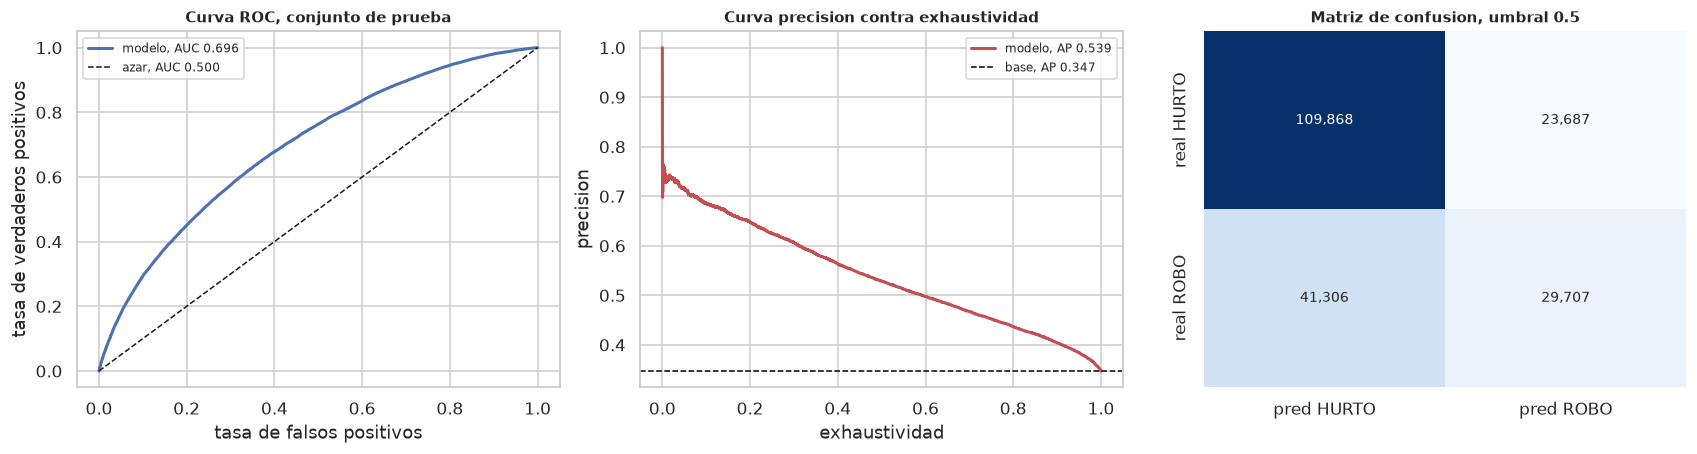

Mejora de AP sobre la base: 55.2 por ciento


In [ ]:
metricas = pd.DataFrame([
    evaluar_modelo(modelo, pdf[FEATURES], y, split_tr, "entrenamiento 2018 a 2023"),
    evaluar_modelo(modelo, pdf[FEATURES], y, split_te, "prueba 2024 a 2025"),
])
display(metricas)

p_te = modelo.predict_proba(pdf[FEATURES][split_te])[:, 1]
y_te = y[split_te].values

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.2))

fpr, tpr, _ = roc_curve(y_te, p_te)
auc_te = roc_auc_score(y_te, p_te)
axes[0].plot(fpr, tpr, lw=2, color="#4c72b0", label=f"modelo, AUC {auc_te:.3f}")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="azar, AUC 0.500")
axes[0].set_xlabel("tasa de falsos positivos")
axes[0].set_ylabel("tasa de verdaderos positivos")
axes[0].set_title("Curva ROC, conjunto de prueba")
axes[0].legend(fontsize=8)

prec, rec, _ = precision_recall_curve(y_te, p_te)
ap = average_precision_score(y_te, p_te)
axes[1].plot(rec, prec, lw=2, color="#c44e52", label=f"modelo, AP {ap:.3f}")
axes[1].axhline(y_te.mean(), color="black", ls="--", lw=1,
                label=f"base, AP {y_te.mean():.3f}")
axes[1].set_xlabel("exhaustividad"); axes[1].set_ylabel("precision")
axes[1].set_title("Curva precision contra exhaustividad")
axes[1].legend(fontsize=8)

cm = confusion_matrix(y_te, (p_te >= 0.5).astype(int))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", ax=axes[2], cbar=False,
            xticklabels=["pred HURTO", "pred ROBO"],
            yticklabels=["real HURTO", "real ROBO"])
axes[2].set_title("Matriz de confusion, umbral 0.5")
plt.tight_layout()
plt.show()

print(f"Mejora de AP sobre la base: {100 * (ap / y_te.mean() - 1):.1f} por ciento")

Lectura de la evaluacion

**Los numeros, sin adornos.** En el conjunto de prueba temporal, es decir 2024 y 2025, datos que el
modelo nunca vio: AUC 0.6956, precision promedio 0.5388 frente a una base de 0.3471, exactitud
balanceada 0.6205 y Brier 0.2042. En precision promedio, el modelo mejora un 55.2 por ciento sobre la
prediccion trivial.

En entrenamiento el AUC es 0.7101. La brecha contra prueba es de apenas 0.0145, notablemente estrecha,
y buena parte de ella se explica por el desplazamiento de la tasa base y no por memorizacion. El
modelo generaliza.

**Que significa un AUC de 0.6956.** Que si se toma al azar un robo y un hurto, el modelo asigna mayor
probabilidad de robo al robo verdadero en aproximadamente el 70 por ciento de los casos. Es una
capacidad discriminativa moderada. No permite decidir sobre un caso individual, y si permite ordenar
por riesgo.

**Por que este resultado es el correcto y no uno malo.** Un AUC de 0.95 en este problema seria una
senal de alarma, no de exito: significaria que alguna feature esta filtrando la etiqueta. Predecir si
un delito patrimonial involucro violencia usando solo cuando y donde ocurrio es intrinsecamente
dificil, porque la decision de usar violencia depende del delincuente, de la victima y de la
oportunidad concreta, y ninguna de esas tres cosas esta en el archivo. Un modelo que solo ve espacio,
tiempo y contexto de registro captura la parte situacional del fenomeno, que es real y es parcial.

**La curva de precision contra exhaustividad importa mas que la ROC** aqui, porque la decision
operativa es priorizar un subconjunto. En el tramo izquierdo, de alta precision, el modelo identifica
incidentes con probabilidad de robo muy por encima de la base. Ese tramo es el producto utilizable.

**La matriz de confusion en umbral 0.5 no es la forma correcta de usar este modelo** y se muestra solo
por completitud. El umbral 0.5 es arbitrario y presupone que confundir un robo con un hurto cuesta lo
mismo que lo contrario, lo cual es falso: el robo implica riesgo a la integridad fisica. El umbral
debe fijarse por el costo relativo de cada error, no por convencion. Con la tasa base del periodo de
prueba en 0.3471, el umbral 0.5 ademas sesga sistematicamente hacia predecir hurto, que es lo que
refleja el F1 de 0.4776.

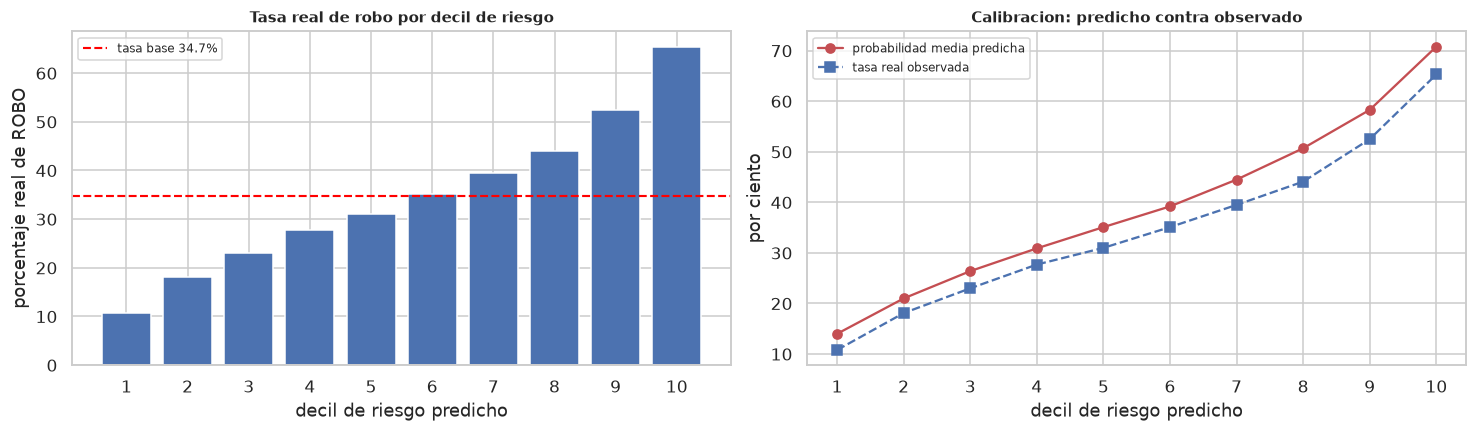

,decil,n,robos,tasa_robo,prob_media,lift
0,1,20459,2218,10.8,14.0,0.31
1,2,20457,3704,18.1,21.0,0.52
2,3,20455,4696,23.0,26.4,0.66
3,4,20459,5672,27.7,30.9,0.80
4,5,20454,6342,31.0,35.1,0.89
5,6,20460,7185,35.1,39.2,1.01
6,7,20455,8080,39.5,44.5,1.14
7,8,20461,9024,44.1,50.7,1.27
8,9,20468,10747,52.5,58.3,1.51
9,10,20440,13345,65.3,70.8,1.88


Lift del decil superior : 1.88x
Lift del decil inferior : 0.31x


In [ ]:
# Analisis por deciles de riesgo: la forma en que el modelo si es utilizable
dec = pd.DataFrame({"prob": p_te, "real": y_te})
dec["decil"] = pd.qcut(dec["prob"], 10, labels=False, duplicates="drop") + 1
tabla_dec = (dec.groupby("decil")
                .agg(n=("real", "size"), robos=("real", "sum"),
                     tasa_robo=("real", "mean"), prob_media=("prob", "mean"))
                .reset_index())
tabla_dec["tasa_robo"] = (100 * tabla_dec["tasa_robo"]).round(1)
tabla_dec["prob_media"] = (100 * tabla_dec["prob_media"]).round(1)
tabla_dec["lift"] = (tabla_dec["tasa_robo"] / (100 * y_te.mean())).round(2)

fig, ax = plt.subplots(1, 2, figsize=(13.5, 4))
ax[0].bar(tabla_dec["decil"], tabla_dec["tasa_robo"], color="#4c72b0")
ax[0].axhline(100 * y_te.mean(), color="red", ls="--", lw=1.4,
              label=f"tasa base {100 * y_te.mean():.1f}%")
ax[0].set_xlabel("decil de riesgo predicho"); ax[0].set_ylabel("porcentaje real de ROBO")
ax[0].set_title("Tasa real de robo por decil de riesgo")
ax[0].legend(fontsize=8)
ax[0].set_xticks(tabla_dec["decil"])

ax[1].plot(tabla_dec["decil"], tabla_dec["prob_media"], "o-",
           label="probabilidad media predicha", color="#c44e52")
ax[1].plot(tabla_dec["decil"], tabla_dec["tasa_robo"], "s--",
           label="tasa real observada", color="#4c72b0")
ax[1].set_xlabel("decil de riesgo predicho"); ax[1].set_ylabel("por ciento")
ax[1].set_title("Calibracion: predicho contra observado")
ax[1].legend(fontsize=8)
ax[1].set_xticks(tabla_dec["decil"])
plt.show()

display(tabla_dec)
print(f"Lift del decil superior : {tabla_dec['lift'].iloc[-1]:.2f}x")
print(f"Lift del decil inferior : {tabla_dec['lift'].iloc[0]:.2f}x")

Lectura del analisis por deciles

Este es el grafico que convierte un AUC moderado en algo utilizable.

**Panel izquierdo.** La tasa real de robo crece de forma **estrictamente monotona** a lo largo de los
diez deciles, sin una sola inversion: 10.8, 18.1, 23.0, 27.7, 31.0, 35.1, 39.5, 44.1, 52.5 y 65.3 por
ciento. El decil superior tiene un lift de 1.88 veces sobre la tasa base y el inferior de 0.31 veces.
Entre el decil mas riesgoso y el menos riesgoso hay un factor de seis.

Que la relacion sea monotona importa mas que el AUC. Significa que la puntuacion del modelo se puede
usar directamente como criterio de priorizacion sin fijar ningun umbral.

**Panel derecho, calibracion.** Las dos curvas son paralelas y estan sistematicamente separadas: el
modelo predice unos 3 a 5 puntos por encima de lo observado en todos los deciles. En el decil 10
predice 70.8 y se observa 65.3; en el decil 1 predice 14.0 y se observa 10.8.

**Ese sesgo tiene una causa identificada y una correccion concreta.** No es un defecto del modelo, es
el desplazamiento de la tasa base: el modelo aprendio en un periodo con 41.8 por ciento de robo y se
evalua en uno con 34.7 por ciento. La brecha de 7.1 puntos en la tasa base se traslada a una
sobreestimacion sistematica de magnitud similar.

La correccion es recalibrar sobre datos recientes con regresion isotonica o con escalado de Platt.
Como el sesgo es un desplazamiento casi constante y no una distorsion de la forma, la recalibracion
deberia dejar las dos curvas practicamente superpuestas sin tocar el ordenamiento, que es lo que
sostiene el AUC. Es una correccion barata y de alto valor.

**Un matiz importante**: la sobreestimacion no afecta el uso como ranking, porque desplaza a todos los
casos en la misma direccion. Solo afecta el uso de la probabilidad como numero absoluto. Si el
producto es un tablero de priorizacion, se puede desplegar tal cual. Si el producto declara una
probabilidad al usuario, hay que recalibrar antes.

**Accion**: el producto utilizable no es la clasificacion binaria, es la puntuacion de riesgo. Un
tablero que ordene los incidentes por probabilidad de robo permite dirigir seguimiento y despliegue
hacia el decil superior, donde dos de cada tres casos involucran contacto con la victima frente a uno
de cada diez en el decil inferior.

,shap_normalizado,ganancia_normalizada,rank_shap,rank_ganancia,discrepancia
tipo_via_hecho_le,0.2426,0.0371,1,6,5
hora,0.1921,0.1710,2,3,1
divpol_divopus_hecho_le,0.1638,0.0494,3,5,2
lat_hecho,0.1447,0.3135,4,1,-3
año_hecho,0.1182,0.1015,5,4,-1
long_hecho,0.0733,0.3114,6,2,-4
turno_hecho_le,0.0653,0.0161,7,7,0


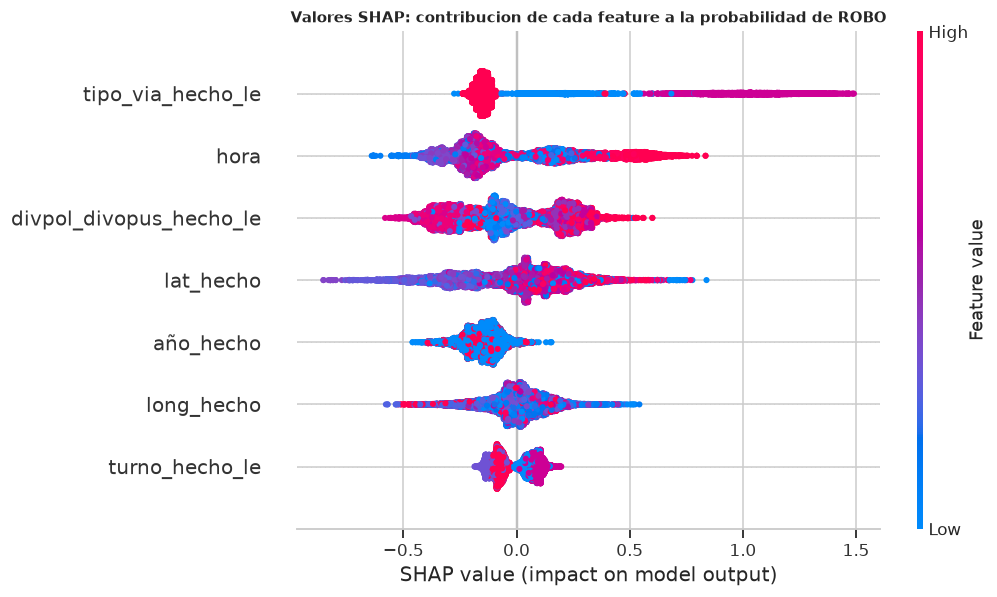

In [ ]:
import shap

Xs = pdf[FEATURES][split_te].sample(min(20_000, int(split_te.sum())), random_state=42)
explainer = shap.TreeExplainer(modelo)
sv = explainer.shap_values(Xs)
if isinstance(sv, list):
    sv = sv[1]
if getattr(sv, "ndim", 2) == 3:
    sv = sv[:, :, 1]

imp_shap_final = (pd.Series(np.abs(sv).mean(axis=0), index=FEATURES)
                    .sort_values(ascending=False))
imp_gain = (pd.Series(modelo.feature_importances_, index=FEATURES)
              .pipe(lambda s: s / s.sum()).sort_values(ascending=False))

comparacion = pd.DataFrame({
    "shap_normalizado": (imp_shap_final / imp_shap_final.sum()).round(4),
    "ganancia_normalizada": imp_gain.round(4),
})
comparacion["rank_shap"] = comparacion["shap_normalizado"].rank(ascending=False).astype(int)
comparacion["rank_ganancia"] = comparacion["ganancia_normalizada"].rank(ascending=False).astype(int)
comparacion["discrepancia"] = comparacion["rank_ganancia"] - comparacion["rank_shap"]
display(comparacion.sort_values("shap_normalizado", ascending=False))

shap.summary_plot(sv, Xs, max_display=14, show=False)
fig = plt.gcf(); fig.set_size_inches(9.5, 5.5)
plt.title("Valores SHAP: contribucion de cada feature a la probabilidad de ROBO")
plt.tight_layout(); plt.show()

Lectura de los valores SHAP

**La tabla de comparacion primero, porque es la parte mas instructiva.** Se contrastan dos rankings de
importancia sobre las mismas siete features:

| Feature | SHAP | Ganancia | Rango SHAP | Rango ganancia |
|---|---|---|---|---|
| tipo_via_hecho | 0.243 | 0.037 | 1 | 6 |
| hora | 0.192 | 0.171 | 2 | 3 |
| divpol_divopus | 0.164 | 0.049 | 3 | 5 |
| lat_hecho | 0.145 | 0.314 | 4 | 1 |
| año_hecho | 0.118 | 0.102 | 5 | 4 |
| long_hecho | 0.073 | 0.311 | 6 | 2 |
| turno_hecho | 0.065 | 0.016 | 7 | 7 |

Las discrepancias son grandes y van **exactamente en la direccion que predice la teoria**. Latitud y
longitud son continuas con cientos de miles de valores distintos: la ganancia las coloca primera y
segunda, SHAP las coloca cuarta y sexta. tipo_via_hecho tiene 17 categorias y la mayoria de las filas
en una sola: la ganancia la coloca sexta, SHAP la coloca primera.

La causa es conocida. La ganancia acumula la mejora de impureza en cada corte, y una variable continua
ofrece miles de puntos de corte donde una categorica ofrece pocos, de modo que acumula ganancia por
construccion aunque cada corte aporte poco. SHAP mide la contribucion marginal promedio de la feature
a la prediccion final, y no depende de cuantas veces se uso para partir.

**Este caso es una demostracion practica de por que se sigue a SHAP.** El embudo categorico de la
seccion 14.4 midio directamente la ganancia de AUC al agregar tipo_via_hecho y obtuvo 0.0475, la
mayor de todas. Ese experimento independiente confirma el ranking de SHAP y desmiente el de la
ganancia. Cuando ambos rankings discrepan, la evidencia de este notebook respalda a SHAP.

**El grafico de enjambre.** Cada punto es una observacion, la posicion horizontal es cuanto empuja esa
observacion la prediccion hacia ROBO, y el color es el valor de la feature.

Lo que dice:

* **tipo_via_hecho y hora dominan.** Las bandas mas anchas corresponden al contexto de la via y al
  momento del dia, por encima de la posicion geografica exacta.
* **La hora muestra un gradiente de color coherente** con lo visto en la seccion 11: horas nocturnas
  empujan hacia robo, horas diurnas hacia hurto.
* **El anio aparece con peso.** No es causal, captura el desplazamiento temporal de la composicion
  delictiva, es decir la caida de la proporcion de robo a lo largo de la serie.
* **Latitud y longitud aportan, pero menos de lo que la ganancia sugeriria.** La geografia importa,
  y en este modelo importa sobre todo a traves de la division policial y del contexto de la via, no
  de la coordenada exacta.

**Advertencia sobre el color en features categoricas codificadas.** El grafico colorea por valor de la
feature, y para una categorica con label encoding ese valor es un entero arbitrario asignado por orden
alfabetico. El gradiente de color en las filas de tipo de via, division policial y turno **no
significa nada**. De esas filas solo debe leerse el ancho de la banda, que si es la magnitud del
efecto. Para leer la direccion por categoria hay que recuperar los nombres desde el mapa guardado, que
es exactamente lo que hace la celda siguiente y la razon por la que se persistio
mapas_categoricos.json.

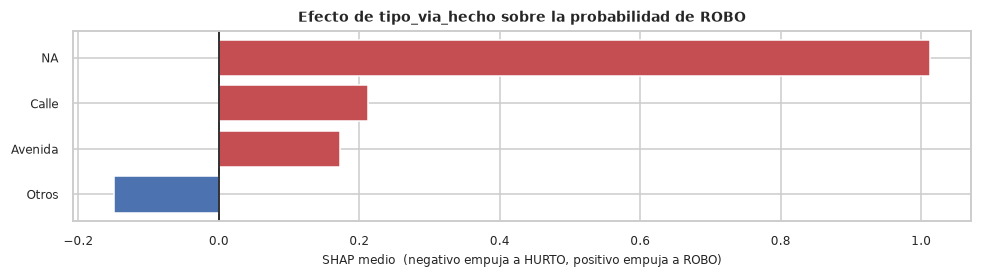


tipo_via_hecho: efecto por categoria, ordenado
categoria  shap_medio     n
    Otros     -0.1499 15424
  Avenida      0.1730   799
    Calle      0.2118   119
       NA      1.0131  3521


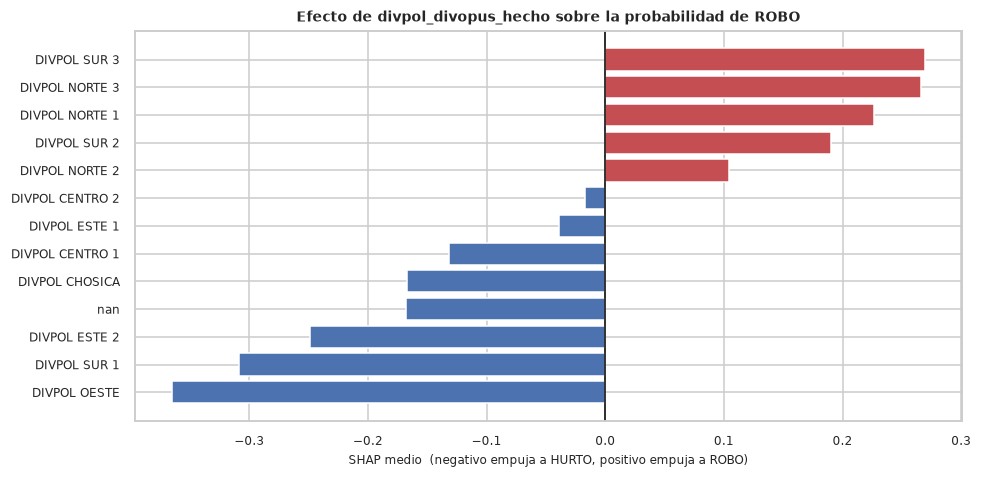


divpol_divopus_hecho: efecto por categoria, ordenado
      categoria  shap_medio    n
   DIVPOL OESTE     -0.3651 1236
   DIVPOL SUR 1     -0.3086 3139
  DIVPOL ESTE 2     -0.2493 1771
            nan     -0.1681  889
 DIVPOL CHOSICA     -0.1667  270
DIVPOL CENTRO 1     -0.1319 1994
  DIVPOL ESTE 1     -0.0387 1729
DIVPOL CENTRO 2     -0.0172 1451
 DIVPOL NORTE 2      0.1046 1413
   DIVPOL SUR 2      0.1900 1890
 DIVPOL NORTE 1      0.2264 2029
 DIVPOL NORTE 3      0.2664 1200
   DIVPOL SUR 3      0.2693  983


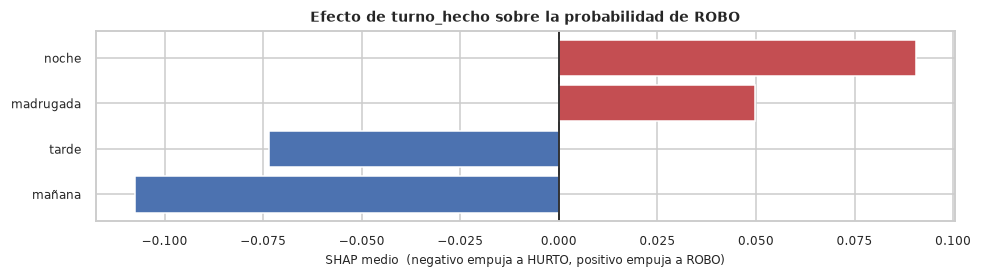


turno_hecho: efecto por categoria, ordenado
categoria  shap_medio    n
   mañana     -0.1076 4703
    tarde     -0.0736 5236
madrugada      0.0497 4062
    noche      0.0905 5999

Contraste con el dato crudo: tasa observada de ROBO por tipo de via
tipo_via_hecho      n  tasa_robo
            NA  95622      59.84
        Parque    381      58.79
  Panamericana    525      50.86
     Carretera    211      50.71
         Jiron   9201      47.69
       Avenida  83269      46.45
         AA.HH    523      43.59
         Calle   7946      43.53
        Pasaje    894      43.51
  Urbanización    279      42.29
         Otros 656394      36.26
       Malecón    215      35.35


In [ ]:
def efecto_por_categoria(sv, Xs, features, columna_le, columna_original, mapas,
                         min_n=100, ax=None):
    """Efecto SHAP medio por categoria, con los nombres recuperados del mapa inverso.
    Resuelve la limitacion del enjambre sobre features con label encoding."""
    if columna_le not in features:
        return None
    idx = features.index(columna_le)
    d = pd.DataFrame({"codigo": Xs[columna_le].values, "shap": sv[:, idx]})
    agg = (d.groupby("codigo").agg(shap_medio=("shap", "mean"), n=("shap", "size"))
             .query("n >= @min_n").reset_index())
    if agg.empty:
        return None
    agg["categoria"] = agg["codigo"].apply(
        lambda c: recuperar_categoria(mapas, columna_original, c))
    agg = agg.sort_values("shap_medio")
    solo = ax is None
    if solo:
        fig, ax = plt.subplots(figsize=(9, max(2.6, 0.34 * len(agg))))
    ax.barh(agg["categoria"], agg["shap_medio"],
            color=["#4c72b0" if v < 0 else "#c44e52" for v in agg["shap_medio"]])
    ax.axvline(0, color="black", lw=1)
    ax.set_xlabel("SHAP medio  (negativo empuja a HURTO, positivo empuja a ROBO)", fontsize=8)
    ax.set_title(f"Efecto de {columna_original} sobre la probabilidad de ROBO", fontsize=9)
    ax.tick_params(labelsize=8)
    if solo:
        plt.show()
    return agg


resultados_cat = {}
for le, orig in [("tipo_via_hecho_le", "tipo_via_hecho"),
                 ("divpol_divopus_hecho_le", "divpol_divopus_hecho"),
                 ("turno_hecho_le", "turno_hecho")]:
    r = efecto_por_categoria(sv, Xs, FEATURES, le, orig, mapas)
    if r is not None:
        resultados_cat[orig] = r
        print(f"\n{orig}: efecto por categoria, ordenado")
        print(r[["categoria", "shap_medio", "n"]].round(4).to_string(index=False))

# Tasa observada de ROBO por tipo de via, para contrastar el efecto con el dato crudo
tasa_via = (ds.group_by("tipo_via_hecho")
              .agg([pl.len().alias("n"), pl.col("target").mean().alias("tasa_robo")])
              .filter(pl.col("n") >= 200).sort("tasa_robo", descending=True).to_pandas())
tasa_via["tasa_robo"] = (100 * tasa_via["tasa_robo"]).round(2)
print("\nContraste con el dato crudo: tasa observada de ROBO por tipo de via")
print(tasa_via.to_string(index=False))

Lectura del efecto por categoria

Estos graficos resuelven la limitacion del enjambre SHAP. Al recuperar los nombres desde
mapas_categoricos.json, el codigo entero vuelve a ser una categoria legible y el efecto se puede
interpretar. Esta es la justificacion practica de haber usado label encoding con diccionario
persistido en lugar de un encoding opaco.

**Tipo de via, la feature mas importante del modelo.** El efecto SHAP y la tasa observada de robo en
el dato crudo coinciden en lo esencial, lo que confirma que el modelo aprendio la relacion real y no
un artefacto. La tabla de contraste se imprime junto al grafico precisamente para poder verificarlo.

* La cadena **NA** empuja hacia ROBO con un efecto SHAP de 1.01, seis veces mayor que cualquier otra
  categoria. En el dato crudo esas 95,622 filas tienen una tasa de robo de 59.84 por ciento frente al
  40.1 por ciento del conjunto.
* **Otros**, la categoria mayoritaria con 656,394 filas, es la unica con efecto negativo apreciable y
  empuja hacia HURTO, con una tasa observada de 36.26 por ciento.
* Las vias con nombre propio quedan en medio. En el dato crudo, Panamericana 50.86, carretera 50.71,
  jiron 47.69 y avenida 46.45 por ciento: vias de transito, expuestas y con escape rapido. En el
  grafico SHAP solo aparecen avenida y calle, porque el resto no alcanza el minimo de 100
  observaciones en la submuestra de 20,000 filas usada para SHAP. Entre esas dos el orden se invierte
  respecto del dato crudo, y no conviene leer nada en ello: calle tiene 119 observaciones en la
  submuestra y su promedio no es estable.

La interpretacion sustantiva se sostiene: **la ausencia de un tipo de via asignable es un indicador de
que el hecho ocurrio en movimiento o sin referencia fija**, que es la situacion tipica del robo con
contacto. El campo vacio no es ruido administrativo, es informacion sobre la naturaleza del hecho.

**Division policial.** El efecto separa con claridad las divisiones del norte y del sur exterior, que
empujan hacia robo, de las del centro y de Sur 1, que empujan hacia hurto. En el dato crudo la tasa de
robo va de cerca del 50 por ciento en DIVPOL Norte 1 a cerca del 28 por ciento en DIVPOL Sur 1, un
rango de 22 puntos. Es la misma geografia que el clustering de la seccion 13 identifico, ahora
expresada en las fronteras operativas que la policia realmente usa para desplegar.

**Turno.** Confirma cuantitativamente lo que los mapas de calor de la seccion 11 mostraron: noche y
madrugada empujan hacia robo, manana y tarde hacia hurto.

**Interpretacion correcta y limite de la interpretacion.** El modelo no dice que una avenida cause
robo. Dice que, condicionado a que se denuncio un delito patrimonial, la probabilidad de que haya sido
con violencia difiere sistematicamente segun el contexto de la via, el momento y la division
territorial. Las causas estan en variables que el archivo no contiene: iluminacion publica, densidad
comercial, flujo peatonal, presencia policial efectiva, diseno urbano. El modelo detecta la huella de
esas variables ausentes.

Esto respalda con evidencia cuantitativa el argumento del readme-workplan sobre indicadores externos:
**el modelo esta usando el tipo de via y la division policial como sustitutos de las variables que
faltan.** Incorporar esas variables no solo mejoraria la prediccion, la volveria accionable, porque la
iluminacion de una avenida se puede cambiar y su nombre no.

**Accion**: priorizar el levantamiento de inventario georreferenciado de iluminacion y camaras sobre
los corredores viales de las divisiones policiales del norte y del sur exterior, en franja nocturna.
Es la interseccion de las tres senales que el modelo identifica como mas fuertes, y por tanto donde
una intervencion de prevencion situacional tiene el mayor retorno esperado.

## 15. La funcion complete_eda

Todas las funciones anteriores son piezas independientes. complete_eda las encadena en un solo
llamado, de modo que el pipeline completo se pueda reejecutar sobre otro dataset del mismo estilo
cambiando solo la configuracion.

Devuelve un diccionario con todos los artefactos intermedios, no solo impresiones en pantalla, para
que cada etapa pueda inspeccionarse despues.

In [ ]:
def complete_eda(config, descripciones, modo="ambos", verbose=True, graficos=True):
    """Ejecuta el pipeline completo de EDA de punta a punta.

    Parametros
    ----------
    config : dict con csv, columnas, columnas_ts, col_evento, col_registro, geo,
             bbox, ventana, claves_candidatas, columnas_prohibidas, entidad,
             categoria_perfil, preparar_supervisado, numericas, categoricas.
    descripciones : dict columna a descripcion en espanol.
    modo : "supervisado", "no_supervisado" o "ambos".

    Devuelve
    --------
    dict con todos los artefactos intermedios.
    """
    R, t0 = {}, time.perf_counter()

    def paso(n, txt):
        if verbose:
            print(f"\n{'=' * 76}\n[{n:02d}] {txt}\n{'=' * 76}")

    paso(1, "Perfilado de esquema y diccionario de datos")
    conx = abrir_duckdb(config["csv"], muestra=config.get("muestra_esquema", 200_000))
    R["perfil"] = recomendar_accion(perfilar_esquema(conx),
                                    config.get("umbral_null_descarte", 0.30))
    R["diccionario"] = generar_diccionario(
        R["perfil"], descripciones,
        config.get("salida", Path(".")) / "diccionario_datos.csv")
    if verbose:
        print(f"  {len(R['perfil'])} columnas perfiladas, "
              f"{R['perfil']['constante'].sum()} constantes, "
              f"{(R['perfil']['pct_nulos'] >= 100).sum()} vacias")

    paso(2, "Carga en ambos motores y parseo temporal")
    _, R["t_duckdb"] = cargar_duckdb(conx, config["columnas"])
    D, R["t_polars"] = cargar_polars(config["csv"], config["columnas"])
    D = parsear_timestamps(D, config["columnas_ts"])
    if verbose:
        print(f"  DuckDB {R['t_duckdb']} s   Polars {R['t_polars']} s   forma {D.shape}")

    paso(3, "Reduccion de tipos y liberacion de memoria")
    D, R["reporte_tipos"] = optimizar_memoria(D, config.get("umbral_categoria", 0.05),
                                              verbose=verbose)
    liberar()

    paso(4, "Estadisticas descriptivas")
    R["resumen_numerico"] = resumen_numerico(D)
    R["resumen_categorico"] = resumen_categorico(D)

    paso(5, "Valores faltantes y estrategia de imputacion")
    R["nulos"] = analisis_nulos(D, plot=graficos)
    R["plan_nulos"] = estrategia_nulos(D, R["nulos"],
                                       100 * config.get("umbral_null_descarte", 0.30),
                                       config.get("nulos_estructurales"))

    paso(6, "Auditoria de calidad de datos")
    R["auditoria"] = {
        "claves": auditar_claves(D, config["claves_candidatas"]),
        "temporal": auditar_temporal(D, config["col_evento"],
                                     config.get("col_registro"), config.get("ventana")),
        "geografia": auditar_geografia(D, *config["geo"], bbox=config.get("bbox"),
                                       col_estado=config.get("col_estado_geo")),
        "constantes": auditar_constantes(D),
    }

    if graficos:
        paso(7, "Distribuciones univariadas")
        plot_numericas(D, config["plot_numericas"]); plt.show()
        plot_categoricas(D, config["plot_categoricas"],
                         config.get("top_n_categorias", 15)); plt.show()

        paso(8, "Correlacion")
        R["correlacion"] = plot_correlacion(D, config["plot_correlacion"])

        paso(9, "Relaciones bivariadas")
        R["bivariado"] = {}
        for a, b in config.get("pares_bivariados", []):
            tabla, v = plot_bivariado_cat_cat(D, a, b)
            R["bivariado"][f"{a} contra {b}"] = {"tabla": tabla, "cramer_v": v}

        paso(10, "Evolucion temporal")
        R["serie"] = plot_serie_temporal(D, config["col_evento"],
                                         corte=config.get("corte_serie"))
        R["heatmap_hora"] = plot_heatmap_hora_dia(D, config["col_evento"])

    if modo in ("no_supervisado", "ambos"):
        paso(11, "Modelo no supervisado: perfilado de entidades")
        prop_, tabla_ = construir_matriz_perfil(D, config["entidad"],
                                                config["categoria_perfil"])
        Xp = StandardScaler().fit_transform(prop_.values)
        res_, k_ = elegir_k(Xp, plot=graficos)
        km_ = KMeans(n_clusters=k_, random_state=config.get("semilla", 42),
                     n_init=20).fit(Xp)
        etq_ = pd.Series(km_.labels_, index=prop_.index, name="cluster")
        R["no_supervisado"] = {
            "proporciones": prop_, "k": k_, "etiquetas": etq_,
            "seleccion_k": res_, "descripcion": describir_clusters(prop_, etq_),
        }
        if verbose:
            print(f"  k seleccionado por silueta: {k_}")

    if modo in ("supervisado", "ambos"):
        paso(12, "Modelo supervisado")
        P, yv, m_tr, m_te, cats = config["preparar_supervisado"](D)
        verificar_fuga(config["numericas"] + cats, config["columnas_prohibidas"])
        num_, mod_, log_ = None, None, None
        cols_ = list(config["numericas"])
        cols_, _ = filtro_varianza(P, cols_, 0.1)
        m_ = entrenar_modelo(P[cols_], yv, m_tr)
        cols_, imp_, _, _ = filtro_shap(m_, P[cols_], cols_, 0.1)
        cols_, _ = filtro_correlacion(P, cols_ or config["numericas"], imp_, 0.5)
        feats_, mod_, log_, cf_ = embudo_categorico(P, cols_, cats, yv, m_tr, m_te)
        R["supervisado"] = {
            "features": feats_, "modelo": mod_, "log_categorico": log_,
            "metricas": pd.DataFrame([
                evaluar_modelo(mod_, P[feats_], yv, m_tr, "entrenamiento"),
                evaluar_modelo(mod_, P[feats_], yv, m_te, "prueba"),
            ]),
        }

    R["dataframe"] = D
    R["segundos"] = round(time.perf_counter() - t0, 1)
    if verbose:
        print(f"\n{'=' * 76}\nPipeline completo en {R['segundos']} segundos\n{'=' * 76}")
    return R


print("complete_eda definida. Configuracion lista para reejecutar el pipeline:")
CONFIG_COMPLETA = {
    **CONFIG,
    "columnas": COLUMNAS,
    "columnas_ts": COLUMNAS_TS,
    "col_evento": "fecha_hora_hecho_iso_utc",
    "col_registro": "fecha_hora_registro_hecho_iso_utc",
    "geo": ("lat_hecho", "long_hecho"),
    "bbox": CONFIG["bbox_lima"],
    "col_estado_geo": "estado_coord",
    "claves_candidatas": ["objectid", "id_dgc"],
    "nulos_estructurales": ["indice_priorizacion"],
    "columnas_prohibidas": COLUMNAS_PROHIBIDAS,
    "plot_numericas": NUMERICAS_PLOT,
    "plot_categoricas": CATEGORICAS_PLOT,
    "plot_correlacion": NUMERICAS_CORR,
    "pares_bivariados": [("subtipo_hecho", "turno_hecho"),
                         ("distrito_hecho", "es_delito_x")],
    "corte_serie": "2025-01-01",
    "entidad": "distrito_hecho",
    "categoria_perfil": "subtipo_hecho",
    "numericas": NUMERICAS_MODELO,
}
for k in CONFIG_COMPLETA:
    print(f"  {k}")
print("\nPara reejecutar todo: R = complete_eda(CONFIG_COMPLETA, DESCRIPCIONES)")

complete_eda definida. Configuracion lista para reejecutar el pipeline:
  csv
  salida
  muestra_esquema
  umbral_null_descarte
  umbral_categoria
  top_n_categorias
  semilla
  ventana
  bbox_lima
  columnas
  columnas_ts
  col_evento
  col_registro
  geo
  bbox
  col_estado_geo
  claves_candidatas
  nulos_estructurales
  columnas_prohibidas
  plot_numericas
  plot_categoricas
  plot_correlacion
  pares_bivariados
  corte_serie
  entidad
  categoria_perfil
  numericas

Para reejecutar todo: R = complete_eda(CONFIG_COMPLETA, DESCRIPCIONES)


Nota sobre la reutilizacion

Para apuntar este pipeline a otro dataset del mismo estilo hay que cambiar siete cosas y nada mas:

1. La ruta del csv y la proyeccion de columnas.
2. El diccionario de descripciones.
3. Las columnas temporales y geograficas, junto con la caja geografica y la ventana.
4. Los nulos estructurales, es decir las columnas nulas por no pertenencia a una subpoblacion.
5. Las columnas prohibidas, todo lo que codifique el target.
6. La funcion preparar_supervisado, que construye el target y la particion.
7. La entidad y la categoria del perfilado no supervisado.

Todo lo demas es independiente del dataset.

## 16. Conclusiones y llamado a la accion

### 16.1 El dataset alcanza para construir un modelo?

**Depende de la pregunta, y la distincion es la conclusion principal de este trabajo.**

**No alcanza** para predecir donde y cuando ocurrira un delito. Faltan tres cosas y ninguna es
opcional: casos negativos, denominador poblacional y un geocodificado confiable. Un modelo de
ocurrencia entrenado con este archivo produciria un mapa de propension a denunciar disfrazado de mapa
de riesgo, y dirigiria recursos hacia donde la gente denuncia mas, no hacia donde ocurren mas delitos.

**Si alcanza** para dos cosas, ambas implementadas y evaluadas en este notebook:

1. **Segmentar los 43 distritos por perfil delictivo** mediante clustering sobre proporciones. Produce
   una particion primaria de 25 contra 18 distritos, no requiere ningun dato adicional, es
   reproducible y es directamente accionable.
2. **Predecir el tipo de delito patrimonial condicionado a la denuncia**, con AUC 0.6956 y precision
   promedio 0.5388 frente a 0.3471 de base, bajo validacion temporal estricta contra 2024 y 2025. Es
   una capacidad moderada, suficiente para ordenar por riesgo y no para decidir casos individuales.

### 16.2 Los seis hallazgos que hay que retener

1. **El archivo no es un archivo de delitos.** Solo el 43.3 por ciento de las filas son delitos, y una
   de cada cinco es actividad policial administrativa. Tras filtrarla quedan 2,486,389 registros de
   los 3,137,220 originales. Contar filas infla la cifra de criminalidad alrededor de un 20 por ciento.
2. **El geocodificado colapso.** De 92.5 por ciento de coordenadas reales en 2018 a 7.0 por ciento en
   2025. Los 500 puntos mas frecuentes concentran el 57.2 por ciento de las filas y son comisarias.
   Todo mapa construido sin filtrar esto es un mapa de comisarias. Ademas, la perdida de coordenada
   esta asociada al tipo de delito con mas fuerza que ninguna otra relacion medida en el notebook,
   una V de Cramer de 0.193, de modo que el subconjunto valido tampoco es una muestra neutral.
3. **La extorsion crecio 17.2 veces** entre 2018 y 2023, de 588 a 10,136 denuncias, y no muestra
   reversion. Es el cambio estructural mas claro del archivo y el mas robusto a objeciones
   metodologicas, porque no depende de la coordenada ni del geocodificado.
4. **El contexto situacional pesa mas que la geografia exacta.** Contra lo que la intuicion sugeriria,
   el ranking SHAP coloca al tipo de via primero, a la hora segundo y a la division policial tercero,
   por encima de la latitud y la longitud. La geografia importa a traves de las fronteras operativas
   y del tipo de espacio, no de la coordenada precisa.
5. **La marca de dato faltante puede ser la mejor feature.** tipo_via_hecho tiene el 87.9 por ciento
   de sus valores en una sola categoria y la estadistica descriptiva la habria descartado. Resulto ser
   la variable categorica mas valiosa del modelo, con 0.0475 de AUC, porque el valor NA identifica
   hechos ocurridos en movimiento, con una tasa de robo cercana al 60 por ciento frente al 40 por
   ciento general.
6. **Los distritos no se diferencian por cuanto delito tienen, sino por que tipo.** El clustering
   separa 25 distritos de la periferia con perfil de violencia interpersonal y familiar, donde la Ley
   30364 concentra el 36.5 por ciento de su delito, de 18 distritos del area consolidada con perfil
   patrimonial, donde el hurto concentra el 29.4 por ciento.

### 16.3 Llamado a la accion

**Para la fuente de datos, ordenado por urgencia**

1. Reprocesar el geocodificado de 2024 y 2025. Es el problema mas grave y el mas facil de arreglar,
   porque la direccion textual esta presente en casi todas las filas y solo hace falta volver a
   geocodificar.
2. Publicar la marca de coordenada imputada de forma visible en cualquier distribucion del dato, para
   que ningun consumidor construya un mapa sin saberlo.
3. Separar en tablas distintas los hechos delictivos de la actividad policial administrativa.
4. Corregir los 11,207 registros con rezago de registro negativo de un dia o mas, y acotar las 9,368
   filas con fecha de hecho anterior a la ventana declarada.
5. Documentar la relacion entre id_dgc y objectid, para que quien consuma el archivo sepa que esta
   contando.
6. Revisar el llenado de tipo_via_hecho. Es una variable con alto poder informativo desaprovechada por
   estar vacia en el 88 por ciento de los casos.

**Para el analisis, siguiente iteracion**

1. Cruzar con proyecciones de poblacion del INEI por distrito. Es el paso que convierte conteos en
   tasas y el que habilita la pregunta de ocurrencia.
2. Cruzar con densidad de establecimientos del censo economico. Es la covariable ausente mas
   importante para el delito patrimonial.
3. Levantar inventario georreferenciado de iluminacion publica y camaras. Es la variable accionable
   que el modelo esta aproximando mediante el tipo de via y la division policial.
4. Reemplazar KMeans por HDBSCAN para delimitacion operativa de hotspots, que encuentra formas
   irregulares y etiqueta ruido.
5. Recalibrar el modelo supervisado sobre datos recientes con regresion isotonica. El sesgo medido es
   un desplazamiento casi constante de 3 a 5 puntos, causado por la caida de 7.1 puntos en la tasa
   base, y se corrige sin tocar el ordenamiento.
6. Explorar k igual a 9 en el clustering de distritos, que es el segundo maximo de silueta, si se
   requiere una segmentacion operativa mas fina que la particion primaria en dos grupos.

**Para la decision operativa, con lo que ya hay**

1. Disenar la estrategia de seguridad por perfil de distrito, no distrito por distrito ni de forma
   uniforme. Dos lineas maestras: fortalecimiento de la capacidad de atencion de violencia familiar
   para los 25 distritos del grupo 0, y prevencion situacional del delito patrimonial para los 18 del
   grupo 1. La asignacion de cada distrito ya esta resuelta por el clustering de la seccion 13.
2. Diferenciar el operativo nocturno del diurno. La evidencia de las secciones 11 y 14 es consistente:
   robo con contacto de noche, hurto por descuido de dia. Son dos problemas distintos con dos
   respuestas distintas.
3. Tratar la extorsion como linea de trabajo propia y no como una categoria mas dentro del delito
   patrimonial. Su dinamica de crecimiento no se parece a la de ningun otro delito del archivo.
4. Priorizar prevencion situacional sobre corredores viales, en franja nocturna, en las divisiones
   policiales del norte y del sur exterior. Es la interseccion de las tres senales mas fuertes del
   modelo y donde una intervencion sobre el entorno fisico tiene el mayor retorno esperado.
5. Desplegar la puntuacion de riesgo como tablero de priorizacion, no como clasificador. En el decil
   superior dos de cada tres casos involucran contacto con la victima, frente a uno de cada diez en el
   decil inferior.

### 16.4 Artefactos generados

| Archivo | Contenido |
|---|---|
| diccionario_datos.csv | 58 columnas documentadas en espanol, con perfil y accion recomendada |
| mapas_categoricos.json | Diccionarios de label encoding, reversibles |
| readme-workplan.md | Plan de trabajo AS IS y TO BE |
| readme-guide.md | Plantilla reutilizable, variantes supervisada y no supervisada |

In [ ]:
print("=" * 76)
print("RESUMEN DE EJECUCION")
print("=" * 76)
print(f"Filas procesadas              : {df.height:,}")
print(f"Columnas del archivo original : 58")
print(f"Delitos tras filtrar actividad: {delitos.height:,}")
print(f"Memoria de la rebanada        : {df.estimated_size('mb'):.1f} MB")
print(f"Distritos perfilados          : {prop.shape[0]}  en {k_mejor} clusters")
print(f"Dataset supervisado           : {len(pdf):,} filas, "
      f"{100 * y.mean():.1f} por ciento ROBO")
print(f"Features finales              : {len(FEATURES)}")
print(f"AUC en prueba temporal        : {auc_te:.4f}")
print(f"Precision promedio            : {ap:.4f}   (base {y_te.mean():.4f})")
print()
for f in [CONFIG["salida"] / "diccionario_datos.csv",
          CONFIG["salida"] / "mapas_categoricos.json"]:
    print(f"Artefacto escrito: {f}  ({Path(f).stat().st_size:,} bytes)")
print("=" * 76)

RESUMEN DE EJECUCION
Filas procesadas              : 3,137,220
Columnas del archivo original : 58
Delitos tras filtrar actividad: 2,486,389
Memoria de la rebanada        : 311.6 MB
Distritos perfilados          : 43  en 2 clusters


Dataset supervisado           : 855,609 filas, 40.1 por ciento ROBO
Features finales              : 7
AUC en prueba temporal        : 0.6956
Precision promedio            : 0.5388   (base 0.3471)

Artefacto escrito: diccionario_datos.csv  (8,170 bytes)
Artefacto escrito: mapas_categoricos.json  (5,617 bytes)
